# 환경 설정


## 한글화 코드


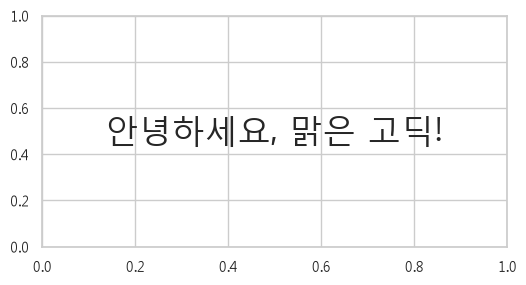

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 스타일을 먼저 적용
sns.set_theme(style="whitegrid")

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 한글 표시 확인
plt.figure(figsize=(6, 3))
plt.text(
    0.5, 0.5,
    "안녕하세요, 맑은 고딕!",
    ha="center",
    va="center",
    size=24
)
plt.show()

## MySQL 연결


In [2]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine, URL, text

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("MySQL 비밀번호: "),
    host="localhost",
    port=3306,
    database="final",
    query={"charset": "utf8mb4"},
)

engine = create_engine(url, pool_pre_ping=True)

# 연결 확인
with engine.connect() as conn:
    print(conn.execute(text("SELECT VERSION()")).scalar())

8.0.37


## DataFrame에 저장


In [3]:
import pandas as pd
from sqlalchemy import text

params = {
    "start_at": "2023-05-04 00:00:00",
    "end_at": "2024-05-06 00:00:00",
}

queries = {
    "polls_question": """
        SELECT
            id,
            TRIM(question_text) AS question_text,
            created_at
        FROM final.polls_question
    """,

    "polls_questionreport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            question_id,
            user_id
        FROM final.polls_questionreport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_usercandidate": """
        SELECT
            id,
            created_at,
            question_piece_id,
            user_id
        FROM final.polls_usercandidate
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionset": """
        SELECT
            id,
            question_piece_id_list,
            opening_time,
            status,
            user_id
        FROM final.polls_questionset
        WHERE opening_time >= created_at
          AND status = 'F'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionpiece": """
        SELECT
            id,
            is_voted,
            question_id,
            is_skipped
        FROM final.polls_questionpiece
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_userquestionrecord": """
        SELECT
            id,
            status,
            created_at,
            chosen_user_id,
            question_id,
            user_id,
            question_piece_id,
            has_read,
            answer_status,
            answer_updated_at,
            report_count,
            opened_times
        FROM final.accounts_userquestionrecord
        WHERE answer_status <> 'P'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    # 가입일 제한 없이 일반 유저 전체 조회
    "accounts_user": """
        SELECT
            id,
            is_superuser,
            is_staff,
            gender,
            friend_id_list,
            is_push_on,
            created_at,
            block_user_id_list,
            hide_user_id_list,
            ban_status,
            report_count,
            group_id
        FROM final.accounts_user
        WHERE is_superuser = 0
          AND is_staff = 0
    """,

    "accounts_timelinereport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            reported_user_id,
            user_id,
            user_question_record_id
        FROM final.accounts_timelinereport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_school": """
        SELECT
            id,
            student_count,
            school_type
        FROM final.accounts_school
    """,

    "accounts_group": """
        SELECT
            id,
            school_id
        FROM final.accounts_group
    """,

    "accounts_blockrecord": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            block_user_id,
            user_id
        FROM final.accounts_blockrecord
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    # 생성일 컬럼이 없어 전체 조회
    "accounts_attendance": """
        SELECT
            id,
            attendance_date_list,
            user_id
        FROM final.accounts_attendance
    """,

    # 구매 기록: 전체 기간 조회 후 분석 셀에서 기간 적용
    "accounts_paymenthistory": """
        SELECT
            id,
            productId,
            phone_type,
            created_at,
            user_id
        FROM final.accounts_paymenthistory
    """,
}

dfs = {}

with engine.connect() as conn:
    for table_name, query in queries.items():
        dfs[table_name] = pd.read_sql_query(
            text(query),
            conn,
            params=params,
        )

        df = dfs[table_name]
        print(f"{table_name}: {len(df):,}행 × {len(df.columns)}열")

# 개별 DataFrame 변수
df_question = dfs["polls_question"]
df_questionreport = dfs["polls_questionreport"]
df_usercandidate = dfs["polls_usercandidate"]
df_questionset = dfs["polls_questionset"]
df_questionpiece = dfs["polls_questionpiece"]
df_userquestionrecord = dfs["accounts_userquestionrecord"]
df_user = dfs["accounts_user"]
df_timelinereport = dfs["accounts_timelinereport"]
df_school = dfs["accounts_school"]
df_group = dfs["accounts_group"]
df_blockrecord = dfs["accounts_blockrecord"]
df_attendance = dfs["accounts_attendance"]
df_paymenthistory = dfs["accounts_paymenthistory"]


polls_question: 5,025행 × 3열
polls_questionreport: 48,928행 × 5열
polls_usercandidate: 4,452,529행 × 4열
polls_questionset: 141,909행 × 5열
polls_questionpiece: 1,177,414행 × 4열
accounts_userquestionrecord: 1,128,249행 × 12열
accounts_user: 677,081행 × 12열
accounts_timelinereport: 208행 × 6열
accounts_school: 5,951행 × 3열
accounts_group: 84,515행 × 2열
accounts_blockrecord: 19,481행 × 5열
accounts_attendance: 349,637행 × 3열
accounts_paymenthistory: 95,140행 × 5열


# 전처리


## 중복값 확인


In [4]:
duplicate_results = []

for table_name, df in dfs.items():
    duplicate_results.append({
        "테이블": table_name,
        "전체 행 수": len(df),

        # 첫 행을 제외한 추가 중복 행 수
        "전체 컬럼 중복 행 수": int(df.duplicated().sum()),

        # 기본키 중복 및 누락
        "ID 중복 수": (
            int(df["id"].duplicated().sum())
            if "id" in df.columns else pd.NA
        ),
        "ID 결측 수": (
            int(df["id"].isna().sum())
            if "id" in df.columns else pd.NA
        ),
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

df_duplicate_summary

,테이블,전체 행 수,전체 컬럼 중복 행 수,ID 중복 수,ID 결측 수
0,polls_question,5025,0,0,0
1,polls_questionreport,48928,0,0,0
2,polls_usercandidate,4452529,0,0,0
3,polls_questionset,141909,0,0,0
4,polls_questionpiece,1177414,0,0,0
5,accounts_userquestionrecord,1128249,0,0,0
6,accounts_user,677081,0,0,0
7,accounts_timelinereport,208,0,0,0
8,accounts_school,5951,0,0,0
9,accounts_group,84515,0,0,0


## 질문 합치기 & 불필요한 질문 드랍


In [5]:
import pandas as pd

# 문서에 정리된 중복 질문 묶음 (같은 튜플 = 같은 질문)
DUPLICATE_GROUPS = [
    # 2. 띄어쓰기·문장부호·단순 오타만 다른 묶음
    (779, 3967, 4950), (3297, 4280), (2753, 2754), (1627, 2486), (3330, 4313),
    (2439, 2440), (2399, 2400), (1250, 2338), (1431, 2283), (1407, 2163),
    (1470, 1978), (729, 1966, 3777, 4760), (673, 1883), (3429, 4412), (3987, 4970),

    # 3-1. 어미·조사가 다른 묶음
    (765, 3133), (1042, 2001), (121, 3454, 4437), (741, 1585, 3084, 3085), (891, 3074),
    (1361, 1624), (1085, 3032), (683, 3014), (1031, 3009), (624, 3003),
    (2996, 2997), (982, 2990), (128, 589), (1345, 3256, 4239), (2908, 2909),
    (1529, 2904), (582, 2777), (2691, 3760, 4743), (1336, 2680), (1375, 2668),
    (1284, 2624), (1246, 2615), (1442, 2518, 4039, 5022), (2504, 3632, 4615), (174, 1198),
    (118, 1329), (381, 2404), (1373, 2307), (1509, 2291), (629, 4127, 5110),
    (2237, 2240), (2214, 4133, 5116), (2169, 2170), (611, 2161), (358, 2155),
    (1169, 2081), (2053, 3448, 4431), (502, 3486, 4469), (1001, 1973),
    (1951, 3547, 4530, 3961, 4944), (1948, 1949), (1548, 1946), (1429, 1929, 1930),
    (1900, 1902), (1061, 1894), (1410, 1879), (748, 1848), (613, 1776),
    (896, 1759), (577, 1738), (1456, 1686), (114, 1150), (345, 1165),
    (1301, 3025), (1382, 2317),

    # 3-2. 유의어·어순·어조가 다른 묶음
    (1013, 1221), (298, 1239, 2202, 3979, 4962), (1634, 2099, 3940, 4923), (1630, 1994),
    (246, 3169, 4152), (597, 2540), (119, 2361, 2362), (228, 2327, 3092), (1224, 2125),
    (672, 1808), (1265, 1727, 3375, 4358), (201, 1356), (1347, 3037), (1168, 3283, 4266),
    (322, 2917), (797, 4136, 5119), (1332, 2784), (1207, 2759), (510, 2733, 3134),
    (1552, 2008), (3127, 3209, 4192), (216, 2693), (313, 501), (453, 3123),
    (1148, 2631), (548, 994), (115, 2490), (1220, 2481), (866, 1030),
    (635, 2448), (2441, 3105), (1491, 3100), (2384, 3099), (301, 986),
    (2036, 3228, 4211), (1319, 3533, 4516), (1888, 3176, 4159), (622, 1853),
    (142, 3980, 4963), (492, 2667), (122, 2492), (599, 3741, 4724), (316, 1271),
    (2228, 2229), (180, 1618),

    # 4-3. 일반 구간 내 텍스트 완전 일치
    (782, 3163), (287, 1391, 3160), (1558, 3159), (1632, 3043), (521, 1492),
    (1598, 3103), (1508, 3096), (3084, 3085), (1299, 3073), (197, 763),
    (1309, 3062), (608, 3059), (1029, 3226, 4209), (1359, 3007), (182, 1124),
    (823, 2968), (674, 2967), (1421, 2964), (2958, 2959), (634, 2954),
    (1395, 2948), (831, 2940), (1503, 2924), (1537, 2915), (1599, 2912),
    (1437, 2883), (1641, 2879), (2868, 2869), (1581, 2847), (1628, 2835),
    (1469, 2812), (856, 2809), (2801, 2802), (1533, 2800), (2775, 2776),
    (708, 2761), (838, 1397, 2750), (2720, 2721), (1565, 2702), (553, 1489),
    (746, 2688), (1571, 2634), (1596, 2599), (1244, 2595), (1617, 2590),
    (1383, 2537), (1639, 2530), (1442, 2518), (870, 2503), (2449, 2450),
    (2445, 2446), (2428, 2429), (1273, 2427), (1341, 2396), (1638, 2373),
    (1637, 2314), (1331, 2309), (868, 2259), (684, 2226), (2220, 2221),
    (1453, 2203), (1342, 2188), (1616, 2181), (1337, 2175), (1549, 2173),
    (1190, 2157), (2127, 2128), (1028, 2112), (2098, 3511, 4494), (1403, 2096),
    (2090, 2091), (730, 2087), (1411, 2083), (1499, 2062), (2051, 2052),
    (1440, 2044), (1623, 2032), (2006, 2007), (1436, 1971), (729, 1966),
    (1951, 3547, 4530), (1315, 1933), (1929, 1930), (1640, 1855), (836, 1839),
    (1279, 1830), (790, 1821), (1772, 1773), (1614, 1769), (1398, 1750),
    (1416, 1742), (1446, 1740), (750, 1728), (1349, 1717), (835, 1687),
    (1237, 1629), (1669, 1670), (620, 1664),
]

# 4-2. 분석에서 제거할 ID ("vote", "포인트")
REMOVE_IDS = {
    186, 483, 639, 696, 712, 725, 736, 807, 881, 940, 946, 1139, 1219, 1232, 1320,
    1507, 1591, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1747, 1749, 2129,
    2246, 2565, 2843, 2916, 3200, 3216, 3314, 3353, 3367, 3447, 3564, 3566, 3695,
    3913, 3915, 4033, 4183, 4199, 4297, 4336, 4350, 4430, 4547, 4549, 4678, 4896,
    4898, 5016,
    3956, 4939,
}

# 4-1. 블록 복제 구간: ID 4151~5133 = ID 3168~4150 (+983)
BLOCK_START, BLOCK_END, BLOCK_OFFSET = 3168, 4150, 983


class QuestionIdMapper:
    """중복 질문 ID를 묶음 내 가장 작은 ID로 치환한다.

    - 블록 복제 구간(4151~5133)은 원본 ID(-983)와 같은 묶음으로 본다.
    - 묶음이 서로 이어지면(예: 4950 → 3967 → 779) 하나로 합쳐 가장 작은 ID로 보낸다.
    - "vote", "포인트" ID는 NA로 바꾼다.
    """

    def __init__(self):
        parent = {}

        def find(x):
            parent.setdefault(x, x)
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        def union(a, b):
            ra, rb = find(a), find(b)
            if ra != rb:
                # 루트를 항상 작은 ID로 유지 → 루트가 곧 대표 ID
                parent[max(ra, rb)] = min(ra, rb)

        for group in DUPLICATE_GROUPS:
            for qid in group[1:]:
                union(group[0], qid)
        for qid in range(BLOCK_START, BLOCK_END + 1):
            union(qid, qid + BLOCK_OFFSET)

        self.mapping = {qid: find(qid) for qid in parent if find(qid) != qid}
        self.remove_ids = set(REMOVE_IDS)

    def map_id(self, qid):
        """ID 하나를 대표 ID로 바꾼다. 제거 대상이면 None."""
        if qid in self.remove_ids:
            return None
        return self.mapping.get(qid, qid)

    def transform(self, ids):
        """ID 리스트/Series를 대표 ID Series(Int64)로 바꾼다. 제거 대상은 NA."""
        s = ids if isinstance(ids, pd.Series) else pd.Series(ids)
        return s.map(self.map_id).astype("Int64")


In [6]:
mapper = QuestionIdMapper()

# 원본 question_id는 유지
df_questionreport_clean = df_questionreport.copy()

df_questionreport_clean["대표 질문 ID"] = mapper.transform(
    df_questionreport_clean["question_id"]
)

# REMOVE_IDS에 해당하는 행 제외
df_questionreport_clean = df_questionreport_clean.dropna(
    subset=["대표 질문 ID"]
)

In [7]:
mapper = QuestionIdMapper()

print(
    "전체 질문 통합 후 질문 수:",
    f"{mapper.transform(df_question['id']).nunique():,}개",
)

전체 질문 통합 후 질문 수: 3,778개


In [8]:
# clean 신고 데이터에 포함된 고유 대표 질문 수
print(
    "질문을 합쳤을 때 신고가 된 질문 수:",
    f"{df_questionreport_clean['대표 질문 ID'].nunique():,}개",
)

질문을 합쳤을 때 신고가 된 질문 수: 2,902개


In [9]:
import pandas as pd

REMOVE_IDS = {
    186, 483, 639, 696, 712, 725, 736, 807, 881, 940, 946, 1139, 1219, 1232, 1320,
    1507, 1591, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1747, 1749, 2129,
    2246, 2565, 2843, 2916, 3200, 3216, 3314, 3353, 3367, 3447, 3564, 3566, 3695,
    3913, 3915, 4033, 4183, 4199, 4297, 4336, 4350, 4430, 4547, 4549, 4678, 4896,
    4898, 5016,
    3956, 4939,
}

# 1. 제외 ID에 원본 질문 문구 연결
df_remove_id_check = (
    pd.DataFrame({"원본 질문 ID": sorted(REMOVE_IDS)})
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "원본 질문 ID",
            "question_text": "원본 질문 문구",
        }),
        on="원본 질문 ID",
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

# 2. 원본 연결 여부와 vote 포함 여부 확인
df_remove_id_check["원본 연결 여부"] = (
    df_remove_id_check["_merge"].eq("both")
)

df_remove_id_check["vote 포함 여부"] = (
    df_remove_id_check["원본 질문 문구"]
    .astype("string")
    .str.contains("vote", case=False, regex=False, na=False)
)

# 문구 결측은 vote 미포함과 별도로 구분
df_remove_id_check["확인 결과"] = "문구 확인 불가"

remove_text_available = (
    df_remove_id_check["원본 연결 여부"]
    & df_remove_id_check["원본 질문 문구"].notna()
)

df_remove_id_check.loc[
    remove_text_available
    & df_remove_id_check["vote 포함 여부"],
    "확인 결과",
] = "vote 포함"

df_remove_id_check.loc[
    remove_text_available
    & ~df_remove_id_check["vote 포함 여부"],
    "확인 결과",
] = "vote 미포함"

df_remove_id_check = df_remove_id_check.drop(columns="_merge")

# 3. 개수 요약
print(f"제외 대상 ID: {len(REMOVE_IDS):,}개")
print(
    "vote 포함:",
    f"{df_remove_id_check['확인 결과'].eq('vote 포함').sum():,}개",
)
print(
    "vote 미포함:",
    f"{df_remove_id_check['확인 결과'].eq('vote 미포함').sum():,}개",
)
print(
    "원본 ID 연결 불가:",
    f"{(~df_remove_id_check['원본 연결 여부']).sum():,}개",
)
print(
    "원본은 있으나 문구 결측:",
    f"{(df_remove_id_check['원본 연결 여부'] & ~remove_text_available).sum():,}개",
)

# 4. vote가 포함되지 않은 질문
print("\n[vote 미포함 질문]")
display(
    df_remove_id_check.loc[
        df_remove_id_check["확인 결과"].eq("vote 미포함"),
        ["원본 질문 ID", "원본 질문 문구"],
    ].reset_index(drop=True)
)

# 5. 문구 확인이 불가능한 ID
df_remove_unavailable = df_remove_id_check.loc[
    df_remove_id_check["확인 결과"].eq("문구 확인 불가"),
    ["원본 질문 ID", "원본 질문 문구", "원본 연결 여부"],
]

if not df_remove_unavailable.empty:
    print("\n[확인 불가 ID]")
    display(df_remove_unavailable.reset_index(drop=True))

# 전체 목록이 필요하면 실행
# display(df_remove_id_check)

제외 대상 ID: 58개
vote 포함: 56개
vote 미포함: 2개
원본 ID 연결 불가: 0개
원본은 있으나 문구 결측: 0개

[vote 미포함 질문]


,원본 질문 ID,원본 질문 문구
0,3956,포인트
1,4939,포인트


## 전체 신고가 1,2건이고 사유가 그냥 싫어인 유저 제외


In [10]:
# 1. 전체 질문 신고 기준으로 제외 대상 계산
df_report_exclusion_source = (
    df_questionreport_clean
    .drop_duplicates("id")
    .copy()
)

df_report_exclusion_source["그냥 싫어 여부"] = (
    df_report_exclusion_source["reason"]
    .astype("string")
    .str.strip()
    .eq("그냥 싫어")
    .fillna(False)
)

df_reporter_exclusion_counts = (
    df_report_exclusion_source
    .dropna(subset=["user_id"])
    .groupby("user_id")
    .agg(
        전체_신고_건수=("id", "nunique"),
        그냥_싫어_신고_건수=("그냥 싫어 여부", "sum"),
    )
)

# 전체 신고 1~2건 + 모든 신고 사유가 '그냥 싫어'
reporter_exclusion_mask = (
    df_reporter_exclusion_counts["전체_신고_건수"].between(1, 2)
    & df_reporter_exclusion_counts["전체_신고_건수"].eq(
        df_reporter_exclusion_counts["그냥_싫어_신고_건수"]
    )
)

# 이후 셀에서 공통으로 사용할 제외 유저 ID
excluded_reporter_ids = df_reporter_exclusion_counts.index[
    reporter_exclusion_mask
]

# 2. 제외 조건을 적용한 신고 데이터
# 기존 clean 데이터는 유지
df_questionreport_filtered = (
    df_report_exclusion_source.loc[
        ~df_report_exclusion_source["user_id"].isin(
            excluded_reporter_ids
        )
    ]
    .drop(columns="그냥 싫어 여부")
    .copy()
)

# 3. 적용 결과 확인
print(f"제외 유저 수: {len(excluded_reporter_ids):,}명")
print(f"제외 전 신고 수: {len(df_report_exclusion_source):,}건")
print(
    f"제외된 신고 수: "
    f"{len(df_report_exclusion_source) - len(df_questionreport_filtered):,}건"
)
print(f"제외 후 신고 수: {len(df_questionreport_filtered):,}건")

제외 유저 수: 8,794명
제외 전 신고 수: 48,453건
제외된 신고 수: 10,025건
제외 후 신고 수: 38,428건


# EDA


## 전체 질문 신고 순위 확인


### 질문 신고 순위


In [11]:
# 제외 유저 필터 적용 후, 긍정적 사유 제외
positive_mask = (
    df_questionreport_filtered["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_question_report_top10 = (
    df_questionreport_clean.loc[
        ~positive_mask
        & df_questionreport_clean["대표 질문 ID"].notna()
    ]
    .groupby("대표 질문 ID")
    .agg(
        신고_수=("id", "size"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
    [["대표 질문 ID", "질문명", "신고 수", "고유 신고자 수"]]
    .sort_values(
        ["신고 수", "고유 신고자 수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_question_report_top10

C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1687196450.py:12: FutureWarning: Operation between non boolean Series with different indexes will no longer return a boolean result in a future version. Cast both Series to object type to maintain the prior behavior.
  ~positive_mask


,대표 질문 ID,질문명,신고 수,고유 신고자 수
0,111,마스크가 잘 어울리는 사람은?,620,442
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,579,471
2,398,등빨이 가장 좋은 사람은?,471,378
3,424,어깨가 가장 넓은 사람은?,363,295
4,305,먹방을 가장 잘할 것 같은 사람은?,338,264
5,564,설레면 콧구멍이 커지는 친구는?,228,202
6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,225,187
7,144,발냄새가 가장 향긋할 것 같은 사람은?,209,174
8,479,치킨 중독인 것 같은 사람은?,198,161
9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,195,150


### 질문 신고 사유 순위


In [12]:
# clean 기준 — 긍정 사유 포함
reasons = (
    df_questionreport_filtered["reason"]
    .astype("string")
    .str.strip()
    .fillna("사유 미기재")
    .replace("", "사유 미기재")
)

df_question_report_reason_ranking = (
    reasons.value_counts()
    .rename_axis("신고 사유")
    .reset_index(name="신고 수")
)

total_reports = df_question_report_reason_ranking["신고 수"].sum()

df_question_report_reason_ranking["비율(%)"] = (
    df_question_report_reason_ranking["신고 수"]
    / total_reports * 100
    if total_reports else float("nan")
)

df_question_report_reason_ranking.round(2)

,신고 사유,신고 수,비율(%)
0,그냥 싫어,18153,47.24
1,나랑 맞지 않는 질문인 것 같음,9435,24.55
2,불쾌한 질문 내용,5351,13.92
3,자꾸 같은 내용의 질문 반복,3157,8.22
4,한 친구가 질문을 반복적으로 보냄,1685,4.38
5,어떻게 이런 생각을? 이 질문 최고!,381,0.99
6,이 질문은 재미없어요,92,0.24
7,기타,83,0.22
8,불쾌한 내용이 포함되어 있음,72,0.19
9,오타가 있음,10,0.03


## 유저 세그먼트별 신고 확인


### 학교급에 따른 질문 신고 Top50 & 사유


#### 학교급별 질문 신고 Top50


In [13]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 공통 제외 조건을 적용한 신고 데이터 사용
df_school_reports_check = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)


def get_school_top50(school_type, label):
    return (
        df_school_reports_check.loc[
            df_school_reports_check["school_type"].eq(school_type)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)["id"]
        .nunique()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(50)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_school_question_top50 = pd.concat(
    [
        get_school_top50("M", "중학교"),
        get_school_top50("H", "고등학교"),
    ],
    axis=1,
)

df_school_question_top50.insert(
    0, "순위", range(1, len(df_school_question_top50) + 1)
)

unknown_school_count = (
    df_school_reports_check.loc[
        df_school_reports_check["school_type"].isna(),
        "id",
    ]
    .nunique()
)

print(f"학교급 확인 불가 신고: {unknown_school_count:,}건")

display(df_school_question_top50)

학교급 확인 불가 신고: 0건


,순위,중학교 대표 질문 ID,중학교 질문명,중학교 신고 수,고등학교 대표 질문 ID,고등학교 질문명,고등학교 신고 수
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,282,111,마스크가 잘 어울리는 사람은?,304
1,2,111,마스크가 잘 어울리는 사람은?,270,410,발냄새가 호두과자 냄새일 것 같은 사람은?,264
2,3,398,등빨이 가장 좋은 사람은?,228,398,등빨이 가장 좋은 사람은?,218
3,4,424,어깨가 가장 넓은 사람은?,180,424,어깨가 가장 넓은 사람은?,161
4,5,305,먹방을 가장 잘할 것 같은 사람은?,165,305,먹방을 가장 잘할 것 같은 사람은?,143
5,6,479,치킨 중독인 것 같은 사람은?,115,564,설레면 콧구멍이 커지는 친구는?,102
6,7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,115,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,98
7,8,564,설레면 콧구멍이 커지는 친구는?,115,144,발냄새가 가장 향긋할 것 같은 사람은?,96
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,104,201,화장을 제일 잘하는 사람?,86
9,10,476,거의 움직이지 않는 친구는?,99,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,84


#### 학교급별 신고 사유


In [14]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 공통 제외 조건 적용 후 신고자 → 학급 → 학교급 연결
df_school_reason_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "reason"],
    ]
    .drop_duplicates("id")
    .merge(
        df_user[["id", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

df_school_reason_reports["신고 사유"] = (
    df_school_reason_reports["reason"]
    .astype("string")
    .str.strip()
)


# 2. 학교급별 신고 사유 순위
def get_school_reason_ranking(school_type, label):
    source = df_school_reason_reports.loc[
        df_school_reason_reports["school_type"].eq(school_type)
    ]

    total = source["id"].nunique()

    ranking = (
        source.groupby("신고 사유")["id"]
        .nunique()
        .reset_index(name="신고 건수")
        .sort_values(
            ["신고 건수", "신고 사유"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    ranking["비율(%)"] = (
        ranking["신고 건수"] / total * 100
        if total else float("nan")
    )

    return ranking.rename(columns={
        "신고 사유": f"{label} 신고 사유",
        "신고 건수": f"{label} 신고 건수",
        "비율(%)": f"{label} 비율(%)",
    })


# 3. 중학생 왼쪽 · 고등학생 오른쪽
df_school_reason_ranking = pd.concat(
    [
        get_school_reason_ranking("M", "중학생"),
        get_school_reason_ranking("H", "고등학생"),
    ],
    axis=1,
)

df_school_reason_ranking.insert(
    0, "순위", range(1, len(df_school_reason_ranking) + 1)
)

other_school_report_count = (
    df_school_reason_reports.loc[
        ~df_school_reason_reports["school_type"].isin(["M", "H"]),
        "id",
    ]
    .nunique()
)

print(f"제외한 고유 신고자: {len(excluded_reporter_ids):,}명")
print(
    "중·고등학교로 구분되지 않는 신고:",
    f"{other_school_report_count:,}건",
)

display(df_school_reason_ranking.round(2))

제외한 고유 신고자: 8,794명
중·고등학교로 구분되지 않는 신고: 0건


,순위,중학생 신고 사유,중학생 신고 건수,중학생 비율(%),고등학생 신고 사유,고등학생 신고 건수,고등학생 비율(%)
0,1,그냥 싫어,8051.0,53.03,그냥 싫어,10102,56.08
1,2,나랑 맞지 않는 질문인 것 같음,4169.0,27.46,나랑 맞지 않는 질문인 것 같음,5266,29.23
2,3,불쾌한 질문 내용,2961.0,19.50,불쾌한 질문 내용,2390,13.27
3,4,이 질문은 재미없어요,1.0,0.01,이 질문은 재미없어요,91,0.51
4,5,<NA>,NaN,NaN,기타,83,0.46
5,6,<NA>,NaN,NaN,불쾌한 내용이 포함되어 있음,72,0.40
6,7,<NA>,NaN,NaN,선정적이거나 자극적인 질문,9,0.05


### 성별에 따른 질문 신고 Top50 & 사유


#### 성별 질문 신고 Top50


In [15]:
# 포함할 신고 사유
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 공통 제외 조건을 적용한 신고 데이터 사용
df_gender_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_user[["id", "gender"]].rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)


def get_gender_top50(gender, label):
    return (
        df_gender_reports.loc[
            df_gender_reports["gender"].eq(gender)
        ]
        .groupby(["대표 질문 ID", "질문명"], dropna=False)["id"]
        .nunique()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(50)
        .rename(columns={
            "대표 질문 ID": f"{label} 대표 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )


df_gender_question_top50 = pd.concat(
    [
        get_gender_top50("F", "여학생"),
        get_gender_top50("M", "남학생"),
    ],
    axis=1,
)

df_gender_question_top50.insert(
    0, "순위", range(1, len(df_gender_question_top50) + 1)
)

print(
    "성별 확인 불가 신고:",
    f"{df_gender_reports.loc[
        ~df_gender_reports['gender'].isin(['F', 'M']), 'id'
    ].nunique():,}건",
)

display(df_gender_question_top50)

성별 확인 불가 신고: 0건


,순위,여학생 대표 질문 ID,여학생 질문명,여학생 신고 수,남학생 대표 질문 ID,남학생 질문명,남학생 신고 수
0,1,111,마스크가 잘 어울리는 사람은?,434,410,발냄새가 호두과자 냄새일 것 같은 사람은?,199
1,2,398,등빨이 가장 좋은 사람은?,430,111,마스크가 잘 어울리는 사람은?,140
2,3,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,460,농부가 될 가능성이 가장 높은 사람은?,66
3,4,424,어깨가 가장 넓은 사람은?,321,516,매일 공유킥보드 타고 다니는 친구는?,65
4,5,305,먹방을 가장 잘할 것 같은 사람은?,257,465,어부가 될 가능성이 가장 높은 사람은?,63
5,6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,163,476,거의 움직이지 않는 친구는?,63
6,7,564,설레면 콧구멍이 커지는 친구는?,159,144,발냄새가 가장 향긋할 것 같은 사람은?,62
7,8,479,치킨 중독인 것 같은 사람은?,153,564,설레면 콧구멍이 커지는 친구는?,58
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,142,305,먹방을 가장 잘할 것 같은 사람은?,51
9,10,201,화장을 제일 잘하는 사람?,131,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,50


#### 성별 신고 사유


In [16]:
import pandas as pd

gender_reason_target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 공통 제외 조건 적용 후, 지정 사유 신고에 성별 연결
df_gender_reason_reports_filtered = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(gender_reason_target_reasons),
        ["id", "user_id", "reason"],
    ]
    .drop_duplicates("id")
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

df_gender_reason_reports_filtered["신고 사유"] = (
    df_gender_reason_reports_filtered["reason"]
    .astype("string")
    .str.strip()
)


# 2. 제외 후 성별 신고 사유 순위
def get_gender_reason_ranking_filtered(gender, label):
    gender_reason_subset = df_gender_reason_reports_filtered.loc[
        df_gender_reason_reports_filtered["gender"].eq(gender)
    ]

    gender_reason_total = gender_reason_subset["id"].nunique()

    gender_reason_table = (
        gender_reason_subset
        .groupby("신고 사유")["id"]
        .nunique()
        .reset_index(name="신고 건수")
        .sort_values(
            ["신고 건수", "신고 사유"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    # 분모: 제외 조건 적용 후 해당 성별의 지정 사유 7개 신고 건수
    gender_reason_table["비율(%)"] = (
        gender_reason_table["신고 건수"] / gender_reason_total * 100
        if gender_reason_total else float("nan")
    )

    return gender_reason_table.rename(columns={
        "신고 사유": f"{label} 신고 사유",
        "신고 건수": f"{label} 신고 건수",
        "비율(%)": f"{label} 비율(%)",
    })


# 3. 여학생 왼쪽 · 남학생 오른쪽
df_gender_reason_ranking_filtered = pd.concat(
    [
        get_gender_reason_ranking_filtered("F", "여학생"),
        get_gender_reason_ranking_filtered("M", "남학생"),
    ],
    axis=1,
)

df_gender_reason_ranking_filtered.insert(
    0,
    "순위",
    range(1, len(df_gender_reason_ranking_filtered) + 1),
)

unknown_gender_count = (
    df_gender_reason_reports_filtered.loc[
        ~df_gender_reason_reports_filtered["gender"].isin(["F", "M"]),
        "id",
    ]
    .nunique()
)

print(f"제외한 고유 신고자: {len(excluded_reporter_ids):,}명")
print(
    "제외 후 지정 사유 신고:",
    f"{df_gender_reason_reports_filtered['id'].nunique():,}건",
)
print(f"성별 확인 불가 신고: {unknown_gender_count:,}건")

display(df_gender_reason_ranking_filtered.round(2))

제외한 고유 신고자: 8,794명
제외 후 지정 사유 신고: 33,195건
성별 확인 불가 신고: 0건


,순위,여학생 신고 사유,여학생 신고 건수,여학생 비율(%),남학생 신고 사유,남학생 신고 건수,남학생 비율(%)
0,1,그냥 싫어,13108,56.05,그냥 싫어,5045,51.44
1,2,나랑 맞지 않는 질문인 것 같음,6796,29.06,나랑 맞지 않는 질문인 것 같음,2639,26.91
2,3,불쾌한 질문 내용,3334,14.26,불쾌한 질문 내용,2017,20.57
3,4,이 질문은 재미없어요,56,0.24,기타,44,0.45
4,5,불쾌한 내용이 포함되어 있음,49,0.21,이 질문은 재미없어요,36,0.37
5,6,기타,39,0.17,불쾌한 내용이 포함되어 있음,23,0.23
6,7,선정적이거나 자극적인 질문,6,0.03,선정적이거나 자극적인 질문,3,0.03


## 질문 라벨링


### 라벨링 한 결과 가져오기


In [17]:
from pathlib import Path
import pandas as pd

csv_path = Path.cwd() / "질문_5차_라벨링.csv"

df_labels = pd.read_csv(csv_path, encoding="utf-8-sig")

### 카테고리별 신고 현황


In [18]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 컬럼명 앞뒤 공백 제거
df_labels.columns = df_labels.columns.str.strip()

# 1. CSV의 질문별 최종 라벨
df_question_reports = (
    df_labels[[
        "대표 질문 ID",
        "대표 질문명",
        "라벨링",
    ]]
    .rename(columns={"라벨링": "카테고리"})
    .copy()
)

df_question_reports["대표 질문 ID"] = pd.to_numeric(
    df_question_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_question_reports["대표 질문 ID"].isna().any()
    or df_question_reports["대표 질문 ID"].duplicated().any()
):
    raise ValueError("대표 질문 ID의 결측·중복을 확인해 주세요.")

# 빈 라벨은 미분류로 표시
df_question_reports["카테고리"] = (
    df_question_reports["카테고리"]
    .astype("string")
    .str.strip()
    .replace({"": "미분류", "해당 없음": "미분류"})
    .fillna("미분류")
)

# 2. 공통 제외 조건 적용 후 질문별 지정 사유 신고 건수
report_counts = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
    ]
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("신고 수")
    .reset_index()
)

# 3. 신고 없는 질문도 0건으로 포함
df_question_reports = df_question_reports.merge(
    report_counts,
    on="대표 질문 ID",
    how="left",
    validate="one_to_one",
)

df_question_reports["신고 수"] = (
    df_question_reports["신고 수"]
    .fillna(0)
    .astype("int64")
)

# 4. 카테고리별 신고 합계
df_label_report_summary = (
    df_question_reports
    .groupby("카테고리")
    .agg(
        전체_질문_수=("대표 질문 ID", "nunique"),
        신고_합계=("신고 수", "sum"),
    )
    .reset_index()
    .rename(columns={
        "전체_질문_수": "전체 질문 수",
        "신고_합계": "신고 합계",
    })
    .sort_values(
        ["신고 합계", "카테고리"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

display(df_label_report_summary)

,카테고리,전체 질문 수,신고 합계
0,성향,1037,7867
1,신체 외형,346,5137
2,성격,352,4036
3,호감,661,4014
4,재능,336,3307
5,이성적 호감,317,3034
6,매력,225,1795
7,체취,21,1162
8,가정,204,1127
9,관계,104,588


### 카테고리별 신고 사유


In [19]:
# 1. 지정 사유 7개의 신고에 카테고리 연결
df_label_report_reasons = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID", "reason"],
    ]
    .drop_duplicates("id")
    .merge(
        df_question_reports[["대표 질문 ID", "카테고리"]],
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
    .rename(columns={"reason": "신고 사유"})
)

df_label_report_reasons["신고 사유"] = (
    df_label_report_reasons["신고 사유"]
    .astype("string")
    .str.strip()
)

# 2. 카테고리별 신고 사유 건수·비율
df_label_reason_summary = (
    df_label_report_reasons
    .groupby(["카테고리", "신고 사유"])["id"]
    .nunique()
    .reset_index(name="신고 수")
)

df_label_reason_summary["카테고리 내 비율(%)"] = (
    df_label_reason_summary["신고 수"]
    / df_label_reason_summary
        .groupby("카테고리")["신고 수"]
        .transform("sum")
    * 100
)

# 3. 앞선 카테고리 신고 현황 표의 순서로 출력
for category in df_label_report_summary["카테고리"]:
    category_reason_result = (
        df_label_reason_summary.loc[
            df_label_reason_summary["카테고리"].eq(category)
        ]
        .sort_values(
            ["신고 수", "신고 사유"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{category}] 신고 사유 순위")

    if category_reason_result.empty:
        print("지정 사유에 해당하는 신고가 없습니다.")
        continue

    display(
        category_reason_result[[
            "신고 사유",
            "신고 수",
            "카테고리 내 비율(%)",
        ]].round(2)
    )


[성향] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,4329,55.03
1,나랑 맞지 않는 질문인 것 같음,2471,31.41
2,불쾌한 질문 내용,994,12.64
3,이 질문은 재미없어요,39,0.50
4,기타,16,0.20
5,불쾌한 내용이 포함되어 있음,16,0.20
6,선정적이거나 자극적인 질문,2,0.03



[신체 외형] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,2609,50.79
1,나랑 맞지 않는 질문인 것 같음,1263,24.59
2,불쾌한 질문 내용,1216,23.67
3,불쾌한 내용이 포함되어 있음,23,0.45
4,기타,13,0.25
5,이 질문은 재미없어요,13,0.25



[성격] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,2093,51.86
1,나랑 맞지 않는 질문인 것 같음,1515,37.54
2,불쾌한 질문 내용,407,10.08
3,기타,11,0.27
4,이 질문은 재미없어요,7,0.17
5,선정적이거나 자극적인 질문,2,0.05
6,불쾌한 내용이 포함되어 있음,1,0.02


... (16 outputs left out)


[칭찬] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,277,64.12
1,나랑 맞지 않는 질문인 것 같음,127,29.40
2,불쾌한 질문 내용,24,5.56
3,기타,4,0.93



[금전] 신고 사유 순위


,신고 사유,신고 수,카테고리 내 비율(%)
0,그냥 싫어,151,61.13
1,나랑 맞지 않는 질문인 것 같음,76,30.77
2,불쾌한 질문 내용,20,8.10


### 성별 카테고리 신고


In [20]:
import pandas as pd

# 1. 앞선 셀에서 정리한 최종 카테고리 사용
df_gender_category_map = (
    df_question_reports[["대표 질문 ID", "카테고리"]]
    .copy()
)

# 2. 공통 제외 조건 적용 후 지정 사유 신고에 성별 연결
df_gender_category_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_gender_category_reports["대표 질문 ID"] = pd.to_numeric(
    df_gender_category_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_gender_category_reports = (
    df_gender_category_reports
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_reports["성별"] = (
    df_gender_category_reports["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

print(
    "신고자 성별 확인 불가:",
    f"{df_gender_category_reports['성별'].eq('확인 불가').sum():,}건",
)

# 3. 신고 기록에 카테고리 연결
df_gender_category_detail = (
    df_gender_category_reports
    .merge(
        df_gender_category_map,
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
        indicator=True,
    )
)

print(
    "라벨 CSV 연결 불가 신고:",
    f"{df_gender_category_detail['_merge'].eq('left_only').sum():,}건",
)

# 라벨 CSV에 연결되는 신고만 분석
# CSV 내 빈 라벨은 앞선 셀에서 '미분류'로 처리됨
df_gender_category_detail = (
    df_gender_category_detail.loc[
        df_gender_category_detail["_merge"].eq("both")
    ]
    .drop(columns="_merge")
    .copy()
)

# 4. 성별 전체 신고 건수
gender_report_totals = (
    df_gender_category_detail
    .groupby("성별")["id"]
    .nunique()
    .rename("성별 전체 신고 수")
    .reset_index()
)

# 5. 성별·카테고리별 집계
df_gender_category_summary = (
    df_gender_category_detail
    .groupby(["성별", "카테고리"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
        신고된_질문_수=("대표 질문 ID", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
        "신고된_질문_수": "신고된 질문 수",
    })
    .merge(
        gender_report_totals,
        on="성별",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_summary["성별 신고 중 비중(%)"] = (
    df_gender_category_summary["신고 수"]
    / df_gender_category_summary["성별 전체 신고 수"]
    * 100
)

# 6. 여학생 → 남학생 순서로 출력
for gender in ["여학생", "남학생"]:
    gender_category_result = (
        df_gender_category_summary.loc[
            df_gender_category_summary["성별"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "고유 신고자 수", "카테고리"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender}] 신고가 집중된 카테고리")

    display(
        gender_category_result[[
            "카테고리",
            "신고 수",
            "고유 신고자 수",
            "신고된 질문 수",
            "성별 신고 중 비중(%)",
        ]].round(2)
    )

신고자 성별 확인 불가: 0건
라벨 CSV 연결 불가 신고: 0건

[여학생] 신고가 집중된 카테고리


,카테고리,신고 수,고유 신고자 수,신고된 질문 수,성별 신고 중 비중(%)
0,성향,5788,2518,659,24.75
1,신체 외형,3815,2183,238,16.31
2,성격,2915,1480,233,12.46
3,호감,2649,1253,393,11.33
4,재능,2449,1331,216,10.47
5,이성적 호감,1806,1127,215,7.72
6,매력,1208,743,137,5.17
7,체취,782,596,13,3.34
8,가정,777,489,129,3.32
9,관계,395,275,63,1.69



[남학생] 신고가 집중된 카테고리


,카테고리,신고 수,고유 신고자 수,신고된 질문 수,성별 신고 중 비중(%)
0,성향,2079,1149,417,21.20
1,호감,1365,751,326,13.92
2,신체 외형,1322,829,190,13.48
3,이성적 호감,1228,826,178,12.52
4,성격,1121,682,169,11.43
5,재능,858,553,157,8.75
6,매력,587,410,97,5.99
7,체취,380,284,13,3.87
8,가정,350,259,96,3.57
9,관계,193,152,47,1.97


### 성별 카테고리별 노출 대비 신고율


In [21]:
import pandas as pd

category_rate_mapper = QuestionIdMapper()

category_rate_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 최종 라벨링
df_category_rate_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "라벨링"]]
    .rename(columns={"라벨링": "카테고리"})
    .copy()
)

df_category_rate_labels["대표 질문 ID"] = pd.to_numeric(
    df_category_rate_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_category_rate_labels["대표 질문 ID"].isna().any()
    or df_category_rate_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_category_rate_labels["카테고리"] = (
    df_category_rate_labels["카테고리"]
    .astype("string")
    .str.strip()
    .replace({"": "미분류", "해당 없음": "미분류"})
    .fillna("미분류")
)

# 2. 일반 유저의 성별
# 공통 유저 제외 조건 적용
df_category_rate_users = (
    df_user.loc[
        df_user["gender"].isin(["F", "M"])
        & ~df_user["id"].isin(excluded_reporter_ids),
        ["id", "gender"],
    ]
    .rename(columns={"id": "user_id"})
    .copy()
)

# 3. 투표 기록 — 직접 투표한 유저의 성별 기준
df_category_rate_votes = (
    df_userquestionrecord[["id", "user_id", "question_id"]]
    .drop_duplicates("id")
    .copy()
)

df_category_rate_votes["대표 질문 ID"] = (
    category_rate_mapper.transform(
        df_category_rate_votes["question_id"]
    )
)

df_category_rate_votes = (
    df_category_rate_votes
    .merge(
        df_category_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_category_rate_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 4. 전체 유저의 지정 사유 신고
# 투표·지목 이력으로 신고자를 제한하지 않음
df_category_rate_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(category_rate_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_category_rate_reports["대표 질문 ID"] = pd.to_numeric(
    df_category_rate_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_category_rate_reports = (
    df_category_rate_reports
    .merge(
        df_category_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_category_rate_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 5. 성별·카테고리별 건수
category_rate_vote_counts = (
    df_category_rate_votes
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("투표 건수")
)

category_rate_report_counts = (
    df_category_rate_reports
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("신고 건수")
)

df_category_report_vote_rate = (
    pd.concat(
        [category_rate_report_counts, category_rate_vote_counts],
        axis=1,
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)

df_category_report_vote_rate["투표 건수 대비 신고 비율(%)"] = (
    df_category_report_vote_rate["신고 건수"]
    .div(
        df_category_report_vote_rate["투표 건수"].where(
            df_category_report_vote_rate["투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 6. 성별 결과
for gender_code, gender_label in [
    ("F", "여학생"),
    ("M", "남학생"),
]:
    category_rate_result = (
        df_category_report_vote_rate.loc[
            df_category_report_vote_rate["gender"].eq(gender_code)
        ]
        .sort_values(
            ["투표 건수 대비 신고 비율(%)", "신고 건수"],
            ascending=[False, False],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender_label}] 카테고리별 투표 건수 대비 신고 비율")

    display(
        category_rate_result[[
            "카테고리",
            "신고 건수",
            "투표 건수",
            "투표 건수 대비 신고 비율(%)",
        ]].round(3)
    )


[여학생] 카테고리별 투표 건수 대비 신고 비율


,카테고리,신고 건수,투표 건수,투표 건수 대비 신고 비율(%)
0,체취,782,4591,17.033
1,신체 외형,3815,61495,6.204
2,유머,331,5410,6.118
3,성향,5788,122957,4.707
4,이성적 호감,1806,43940,4.110
5,재능,2449,65847,3.719
6,성격,2915,81476,3.578
7,매력,1208,43216,2.795
8,가정,777,28322,2.743
9,관계,395,14429,2.738



[남학생] 카테고리별 투표 건수 대비 신고 비율


,카테고리,신고 건수,투표 건수,투표 건수 대비 신고 비율(%)
0,체취,380,3867,9.827
1,이성적 호감,1228,38038,3.228
2,유머,118,4662,2.531
3,신체 외형,1322,52730,2.507
4,성향,2079,106488,1.952
5,호감,1365,82605,1.652
6,성격,1121,68789,1.630
7,매력,587,36827,1.594
8,재능,858,56421,1.521
9,관계,193,12727,1.516


## 신고된 질문의 노출 정도 및 신고율 확인


### 신고 상위 질문의 최다 신고일 전후 투표 건수·비중 변화


In [22]:
import pandas as pd

mapper = QuestionIdMapper()

# 전체·성별·학교급별 Top 10 질문을 합치고 중복 제거
# 앞선 전체·성별·학교급별 순위 집계 셀을 먼저 실행해주세요.

question_id_sources = [
    # 전체 Top 10
    df_question_report_top10["대표 질문 ID"].dropna().head(10),

    # 성별 각각 Top 10
    df_gender_question_top50["여학생 대표 질문 ID"].dropna().head(10),
    df_gender_question_top50["남학생 대표 질문 ID"].dropna().head(10),

    # 학교급별 각각 Top 10
    df_school_question_top50["중학교 대표 질문 ID"].dropna().head(10),
    df_school_question_top50["고등학교 대표 질문 ID"].dropna().head(10),
]

question_ids = (
    pd.to_numeric(
        pd.concat(question_id_sources, ignore_index=True),
        errors="raise",
    )
    .astype("int64")
    .drop_duplicates()
    .sort_values()
    .tolist()
)

n_questions = len(question_ids)

if n_questions == 0:
    raise ValueError("선정된 질문이 없습니다. 앞선 순위 집계 셀을 확인해주세요.")

print(f"중복 제거 후 선정 질문 수: {n_questions:,}개")
print("선정 대표 질문 ID:", question_ids)

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 선정한 대표 질문의 날짜별 합산 신고 수
reports = df_questionreport_clean.loc[
    df_questionreport_clean["대표 질문 ID"].isin(question_ids)
    & df_questionreport_clean["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
].copy()

reports["날짜"] = pd.to_datetime(
    reports["created_at"]
).dt.normalize()

# 현재 DF의 조회 기간
data_start = pd.Timestamp(params["start_at"]).normalize()
data_end = (
    pd.Timestamp(params["end_at"]) - pd.Timedelta(nanoseconds=1)
).normalize()

reports = reports.loc[
    reports["날짜"].between(data_start, data_end)
].copy()

daily_reports = reports.groupby("날짜").size()

if daily_reports.empty:
    raise ValueError("선정한 질문과 신고 사유에 해당하는 기록이 없습니다.")

# 최다 신고일이 여러 날이면 가장 이른 날
reference_date = daily_reports.sort_index().idxmax()

# 2. 전체 투표 기록에 대표 질문 ID 적용
votes = df_userquestionrecord[
    ["id", "question_id", "created_at"]
].copy()

votes["대표 질문 ID"] = mapper.transform(
    votes["question_id"]
)

votes["날짜"] = pd.to_datetime(
    votes["created_at"]
).dt.normalize()

# 조회 기간 적용 + mapper 제외 대상 제거
votes = votes.loc[
    votes["날짜"].between(data_start, data_end)
    & votes["대표 질문 ID"].notna()
].copy()

# 집계 표: 조회 가능한 범위에서 최다 신고일 전후 30일
start_date = max(
    reference_date - pd.Timedelta(days=30),
    data_start,
)
end_date = min(
    reference_date + pd.Timedelta(days=30),
    data_end,
)

dates = pd.date_range(start_date, end_date, freq="D")

# 3. 날짜 × 대표 질문 조합 생성
# 같은 묶음의 원본 질문 투표를 합산하고, 기록이 없으면 0건
daily_question_votes = (
    votes.loc[votes["대표 질문 ID"].isin(question_ids)]
    .groupby(["날짜", "대표 질문 ID"])["id"]
    .nunique()
    .reindex(
        pd.MultiIndex.from_product(
            [dates, question_ids],
            names=["날짜", "대표 질문 ID"],
        ),
        fill_value=0,
    )
    .rename("질문 투표 수")
    .reset_index()
)

# 분모: mapper 제외 대상을 제거한 전체 질문의 투표 기록
# 선정한 16개 질문으로 제한하지 않음
daily_total_votes = (
    votes.groupby("날짜")["id"]
    .nunique()
    .rename("전체 투표 수")
)

daily_question_votes = daily_question_votes.merge(
    daily_total_votes,
    left_on="날짜",
    right_index=True,
    how="left",
    validate="many_to_one",
)

daily_question_votes["전체 투표 수"] = (
    daily_question_votes["전체 투표 수"]
    .fillna(0)
    .astype("int64")
)

# 질문별 일별 투표 비중
# 전체 투표가 0건인 날은 비중을 결측으로 유지
denominator = daily_question_votes["전체 투표 수"]

daily_question_votes["질문 투표 비중(%)"] = (
    daily_question_votes["질문 투표 수"]
    .div(denominator.where(denominator.gt(0)))
    .mul(100)
)

# 4. 매일 동일한 16개 질문의 평균 계산
vote_sum_col = f"{n_questions}개 질문 합산 투표 수"
report_sum_col = f"{n_questions}개 질문 합산 신고 수"

df_daily_question_average = (
    daily_question_votes
    .groupby("날짜")
    .agg(
        질문당_평균_투표_수=("질문 투표 수", "mean"),
        질문당_평균_투표_비중=(
            "질문 투표 비중(%)", "mean"
        ),
        선정_질문_합산_투표_수=("질문 투표 수", "sum"),
        전체_투표_수=("전체 투표 수", "first"),
    )
    .rename(columns={
        "질문당_평균_투표_수": "질문당 평균 투표 수",
        "질문당_평균_투표_비중": "질문당 평균 투표 비중(%)",
        "선정_질문_합산_투표_수": vote_sum_col,
        "전체_투표_수": "전체 투표 수",
    })
)

df_daily_question_average[report_sum_col] = (
    daily_reports.reindex(dates, fill_value=0)
)

df_daily_question_average = (
    df_daily_question_average.reset_index()
)

df_daily_question_average["기준일 대비 일수"] = (
    df_daily_question_average["날짜"] - reference_date
).dt.days

df_daily_question_average = df_daily_question_average[[
    "날짜",
    "기준일 대비 일수",
    report_sum_col,
    "질문당 평균 투표 수",
    "질문당 평균 투표 비중(%)",
    vote_sum_col,
    "전체 투표 수",
]]

print(
    f"공통 기준일: {reference_date:%Y-%m-%d}"
    f" / 합산 신고 {daily_reports.loc[reference_date]:,}건"
)
print(
    f"관측 범위: {start_date:%Y-%m-%d}"
    f" ~ {end_date:%Y-%m-%d}"
)
print(f"평균의 분모: 매일 동일한 대표 질문 {n_questions}개")
print("전체 투표 수: mapper 제외 대상을 제거한 기록 기준")
print(
    f"관측 가능한 기간: 기준일 이전 "
    f"{(reference_date - start_date).days}일"
    f" / 이후 {(end_date - reference_date).days}일"
)

display(
    df_daily_question_average.round({
        "질문당 평균 투표 수": 2,
        "질문당 평균 투표 비중(%)": 4,
    })
)

중복 제거 후 선정 질문 수: 16개
선정 대표 질문 ID: [111, 138, 144, 201, 305, 398, 410, 424, 460, 465, 476, 479, 494, 516, 519, 564]


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1024070881.py:66: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(params["end_at"]) - pd.Timedelta(nanoseconds=1)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1024070881.py:102: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date - pd.Timedelta(days=30),
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1024070881.py:106: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date + pd.Timedelta(days=30),


공통 기준일: 2023-05-14 / 합산 신고 558건
관측 범위: 2023-05-04 ~ 2023-06-13
평균의 분모: 매일 동일한 대표 질문 16개
전체 투표 수: mapper 제외 대상을 제거한 기록 기준
관측 가능한 기간: 기준일 이전 10일 / 이후 30일


,날짜,기준일 대비 일수,16개 질문 합산 신고 수,질문당 평균 투표 수,질문당 평균 투표 비중(%),16개 질문 합산 투표 수,전체 투표 수
0,2023-05-04,-10,19,40.50,0.1785,648,22692
1,2023-05-05,-9,30,78.50,0.1907,1256,41154
2,2023-05-06,-8,149,94.00,0.1961,1504,47940
3,2023-05-07,-7,281,86.38,0.1959,1382,44081
4,2023-05-08,-6,300,68.38,0.2025,1094,33767
5,2023-05-09,-5,312,56.19,0.1932,899,29078
6,2023-05-10,-4,373,63.31,0.2065,1013,30658
7,2023-05-11,-3,377,70.00,0.1970,1120,35540
8,2023-05-12,-2,357,82.44,0.1770,1319,46571
9,2023-05-13,-1,539,110.75,0.1721,1772,64365


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\86435909.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  graph_start = reference_date - pd.Timedelta(days=10)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\86435909.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  graph_end = reference_date + pd.Timedelta(days=10)


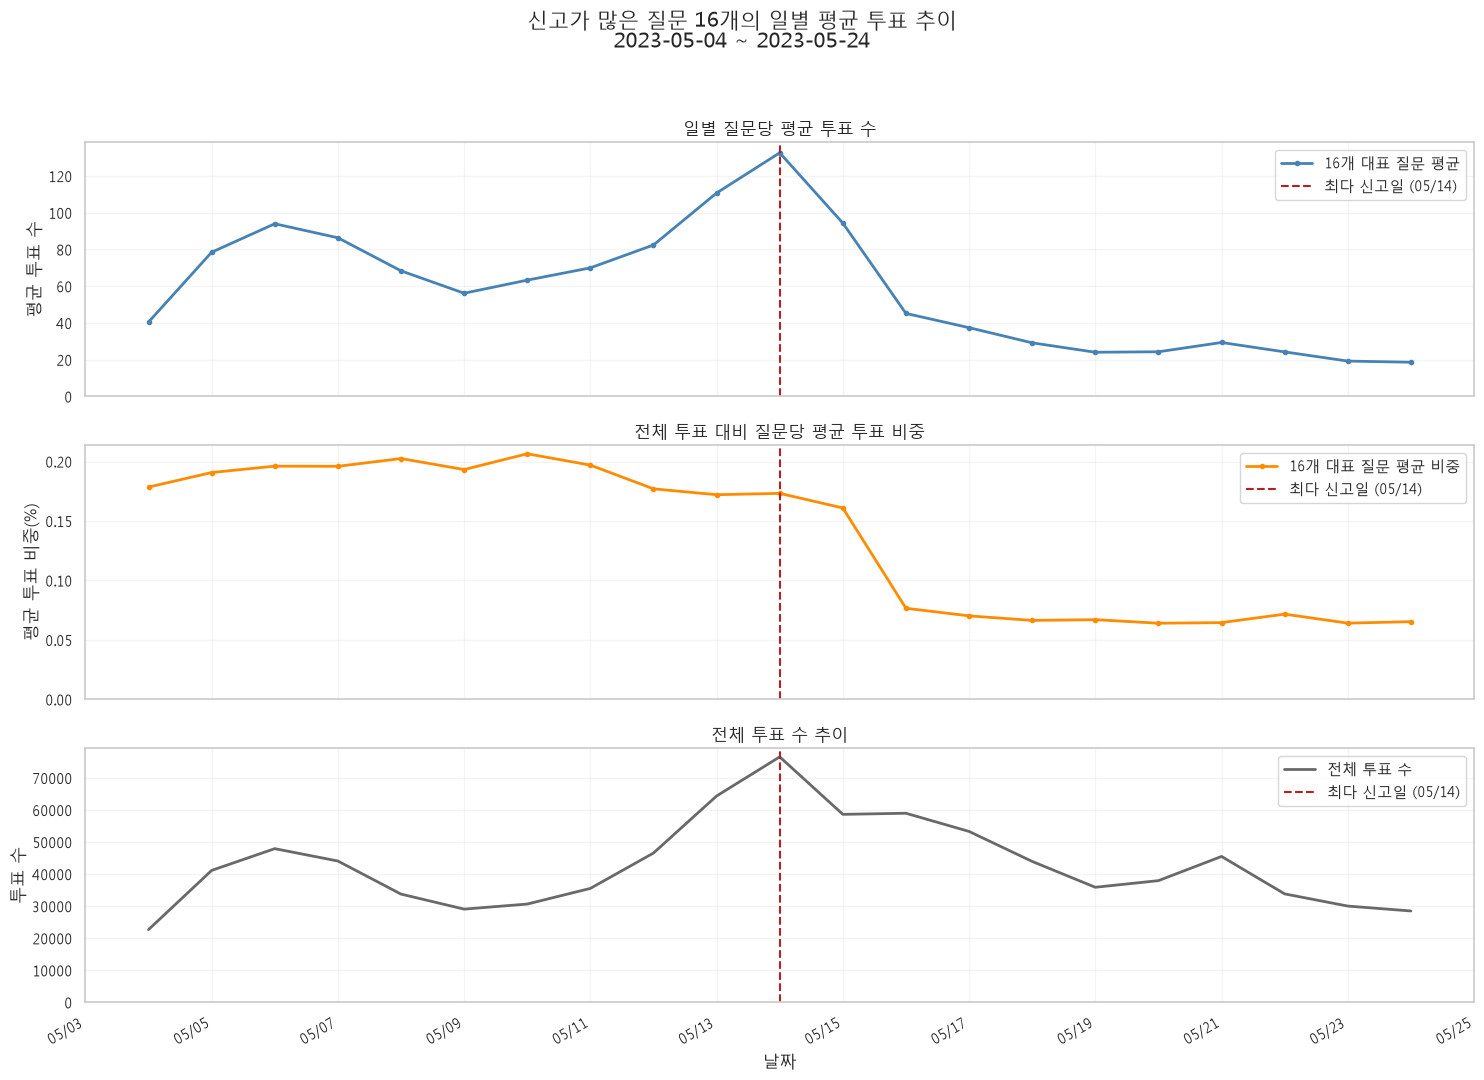

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 그래프만 기준일 이후 10일까지 제한
graph_start = reference_date - pd.Timedelta(days=10)
graph_end = reference_date + pd.Timedelta(days=10)

df_plot = (
    df_daily_question_average.loc[
        df_daily_question_average["날짜"].between(
            graph_start, graph_end
        )
    ]
    .sort_values("날짜")
    .copy()
)

dates = df_plot["날짜"]
n_questions = len(question_ids)

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 11),
    sharex=True,
)

# 1. 질문당 평균 투표 수
axes[0].plot(
    dates,
    df_plot["질문당 평균 투표 수"],
    color="steelblue",
    marker="o",
    markersize=3,
    linewidth=2,
    label=f"{n_questions}개 대표 질문 평균",
)
axes[0].set_title("일별 질문당 평균 투표 수")
axes[0].set_ylabel("평균 투표 수")

# 2. 질문별 투표 비중의 일별 평균
axes[1].plot(
    dates,
    df_plot["질문당 평균 투표 비중(%)"],
    color="darkorange",
    marker="o",
    markersize=3,
    linewidth=2,
    label=f"{n_questions}개 대표 질문 평균 비중",
)
axes[1].set_title("전체 투표 대비 질문당 평균 투표 비중")
axes[1].set_ylabel("평균 투표 비중(%)")

# 3. 같은 기간 전체 투표 수
axes[2].plot(
    dates,
    df_plot["전체 투표 수"],
    color="dimgray",
    linewidth=2,
    label="전체 투표 수",
)
axes[2].set_title("전체 투표 수 추이")
axes[2].set_ylabel("투표 수")
axes[2].set_xlabel("날짜")
axes[2].ticklabel_format(
    axis="y", style="plain", useOffset=False
)

# 공통 기준일 표시
for ax in axes:
    ax.axvline(
        reference_date,
        color="firebrick",
        linestyle="--",
        linewidth=1.5,
        label=f"최다 신고일 ({reference_date:%m/%d})",
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

axes[2].xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)
axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter("%m/%d")
)

fig.suptitle(
    f"신고가 많은 질문 {n_questions}개의 일별 평균 투표 추이\n"
    f"{dates.min():%Y-%m-%d} ~ {dates.max():%Y-%m-%d}",
    fontsize=15,
)

fig.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 5월 14일 전후 신고 상위 10개 질문의 투표·신고 비율


In [24]:
import pandas as pd

top10_rate_mapper = QuestionIdMapper()

top10_rate_reference = pd.Timestamp("2023-05-14")
top10_rate_start = pd.Timestamp("2023-05-04")
top10_rate_end = pd.Timestamp("2023-05-25")  # 미포함

top10_rate_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

if (
    pd.Timestamp(params["start_at"]) > top10_rate_start
    or pd.Timestamp(params["end_at"]) < top10_rate_end
):
    raise ValueError("비교 기간 전체가 조회 범위에 포함되지 않습니다.")

# 1. 남녀 합산 분석 대상 — 공통 유저 제외 조건 유지
df_top10_rate_users = (
    df_user.loc[
        df_user["gender"].isin(["F", "M"])
        & ~df_user["id"].isin(excluded_reporter_ids),
        ["id"],
    ]
    .rename(columns={"id": "user_id"})
)

# 2. 비교 기간의 지정 사유 신고
df_top10_rate_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(top10_rate_reasons),
        ["id", "user_id", "대표 질문 ID", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_top10_rate_reports["시각"] = pd.to_datetime(
    df_top10_rate_reports["created_at"],
    errors="raise",
)

df_top10_rate_reports["대표 질문 ID"] = pd.to_numeric(
    df_top10_rate_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_top10_rate_reports = (
    df_top10_rate_reports.loc[
        df_top10_rate_reports["시각"].ge(top10_rate_start)
        & df_top10_rate_reports["시각"].lt(top10_rate_end)
    ]
    .dropna(subset=["대표 질문 ID"])
    .merge(
        df_top10_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

# 3. 비교 기간 전체의 신고 합계 기준 Top 10 선정
df_top10_rate_ranking = (
    df_top10_rate_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .reset_index(name="비교 기간 신고 합계")
    .sort_values(
        ["비교 기간 신고 합계", "대표 질문 ID"],
        ascending=[False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

if df_top10_rate_ranking.empty:
    raise ValueError("비교 기간에 해당하는 신고가 없습니다.")

df_top10_rate_ranking.insert(
    0, "순위", range(1, len(df_top10_rate_ranking) + 1)
)

top10_rate_ids = df_top10_rate_ranking["대표 질문 ID"].tolist()

df_top10_rate_reports = (
    df_top10_rate_reports.loc[
        df_top10_rate_reports["대표 질문 ID"].isin(top10_rate_ids)
    ]
    .copy()
)

# 4. 선정 질문의 투표 기록
df_top10_rate_votes = (
    df_userquestionrecord[
        ["id", "user_id", "question_id", "created_at"]
    ]
    .drop_duplicates("id")
    .copy()
)

df_top10_rate_votes["시각"] = pd.to_datetime(
    df_top10_rate_votes["created_at"],
    errors="raise",
)

df_top10_rate_votes["대표 질문 ID"] = (
    top10_rate_mapper.transform(
        df_top10_rate_votes["question_id"]
    )
)

df_top10_rate_votes = (
    df_top10_rate_votes.loc[
        df_top10_rate_votes["시각"].ge(top10_rate_start)
        & df_top10_rate_votes["시각"].lt(top10_rate_end)
        & df_top10_rate_votes["대표 질문 ID"].isin(top10_rate_ids)
    ]
    .merge(
        df_top10_rate_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

# 5. 기준일 전후 구분
def classify_top10_rate_period(series):
    dates = series.dt.normalize()
    periods = pd.Series("기준일", index=series.index)

    periods.loc[dates.lt(top10_rate_reference)] = "이전 10일"
    periods.loc[dates.gt(top10_rate_reference)] = "이후 10일"

    return periods


df_top10_rate_reports["구간"] = classify_top10_rate_period(
    df_top10_rate_reports["시각"]
)

df_top10_rate_votes["구간"] = classify_top10_rate_period(
    df_top10_rate_votes["시각"]
)

# 6. 질문 × 구간별 신고·투표 건수
top10_rate_period_order = ["이전 10일", "기준일", "이후 10일"]

top10_rate_grid = pd.MultiIndex.from_product(
    [top10_rate_ids, top10_rate_period_order],
    names=["대표 질문 ID", "구간"],
)

df_top10_rate_detail = (
    pd.concat(
        [
            df_top10_rate_reports
            .groupby(["대표 질문 ID", "구간"])["id"]
            .nunique()
            .rename("신고 건수"),

            df_top10_rate_votes
            .groupby(["대표 질문 ID", "구간"])["id"]
            .nunique()
            .rename("투표 건수"),
        ],
        axis=1,
    )
    .reindex(top10_rate_grid)
    .fillna(0)
    .astype(int)
    .reset_index()
)

df_top10_rate_detail["투표 대비 신고 비율(%)"] = (
    df_top10_rate_detail["신고 건수"]
    .div(
        df_top10_rate_detail["투표 건수"].where(
            df_top10_rate_detail["투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 7. 질문별 전후 결과를 한 행에 표시
df_top10_rate_comparison = (
    df_top10_rate_ranking
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "대표 질문 ID",
            "question_text": "질문명",
        }),
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

for period in ["이전 10일", "이후 10일"]:
    period_result = (
        df_top10_rate_detail.loc[
            df_top10_rate_detail["구간"].eq(period),
            [
                "대표 질문 ID",
                "신고 건수",
                "투표 건수",
                "투표 대비 신고 비율(%)",
            ],
        ]
        .rename(columns={
            "신고 건수": f"{period} 신고 건수",
            "투표 건수": f"{period} 투표 건수",
            "투표 대비 신고 비율(%)": f"{period} 신고 비율(%)",
        })
    )

    df_top10_rate_comparison = (
        df_top10_rate_comparison
        .merge(
            period_result,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
    )

df_top10_rate_comparison["신고 비율 증감(%p)"] = (
    df_top10_rate_comparison["이후 10일 신고 비율(%)"]
    - df_top10_rate_comparison["이전 10일 신고 비율(%)"]
)

print("선정 기준: 2023-05-04 ~ 2023-05-24 신고 합계 Top 10")
print("이전 10일: 2023-05-04 ~ 2023-05-13")
print("이후 10일: 2023-05-15 ~ 2023-05-24")
print("기준일 5월 14일은 전후 비교에서 제외")

display(
    df_top10_rate_comparison[[
        "순위",
        "대표 질문 ID",
        "질문명",
        "비교 기간 신고 합계",
        "이전 10일 신고 건수",
        "이전 10일 투표 건수",
        "이전 10일 신고 비율(%)",
        "이후 10일 신고 건수",
        "이후 10일 투표 건수",
        "이후 10일 신고 비율(%)",
        "신고 비율 증감(%p)",
    ]].round(3)
)

# 8. 선정 질문 전체의 합산 비교
df_top10_rate_total = (
    df_top10_rate_detail
    .groupby("구간")[["신고 건수", "투표 건수"]]
    .sum()
    .reindex(top10_rate_period_order)
)

df_top10_rate_total["투표 대비 신고 비율(%)"] = (
    df_top10_rate_total["신고 건수"]
    .div(
        df_top10_rate_total["투표 건수"].where(
            df_top10_rate_total["투표 건수"].gt(0)
        )
    )
    .mul(100)
)

print("\n[선정 질문 합산]")
display(df_top10_rate_total.reset_index().round(3))

선정 기준: 2023-05-04 ~ 2023-05-24 신고 합계 Top 10
이전 10일: 2023-05-04 ~ 2023-05-13
이후 10일: 2023-05-15 ~ 2023-05-24
기준일 5월 14일은 전후 비교에서 제외


,순위,대표 질문 ID,질문명,비교 기간 신고 합계,이전 10일 신고 건수,이전 10일 투표 건수,이전 10일 신고 비율(%),이후 10일 신고 건수,이후 10일 투표 건수,이후 10일 신고 비율(%),신고 비율 증감(%p)
0,1,111,마스크가 잘 어울리는 사람은?,515,316,607,52.059,135,284,47.535,-4.524
1,2,410,발냄새가 호두과자 냄새일 것 같은 사람은?,481,286,799,35.795,148,307,48.208,12.414
2,3,398,등빨이 가장 좋은 사람은?,400,234,755,30.993,123,318,38.679,7.686
3,4,424,어깨가 가장 넓은 사람은?,288,165,779,21.181,91,317,28.707,7.526
4,5,305,먹방을 가장 잘할 것 같은 사람은?,269,163,873,18.671,74,338,21.893,3.222
5,6,564,설레면 콧구멍이 커지는 친구는?,194,66,173,38.150,92,327,28.135,-10.016
6,7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,193,112,855,13.099,66,346,19.075,5.976
7,8,144,발냄새가 가장 향긋할 것 같은 사람은?,174,104,717,14.505,57,301,18.937,4.432
8,9,479,치킨 중독인 것 같은 사람은?,156,94,793,11.854,46,295,15.593,3.740
9,10,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,154,86,826,10.412,59,371,15.903,5.491



[선정 질문 합산]


,구간,신고 건수,투표 건수,투표 대비 신고 비율(%)
0,이전 10일,1626,7177,22.656
1,기준일,307,1298,23.652
2,이후 10일,891,3204,27.809


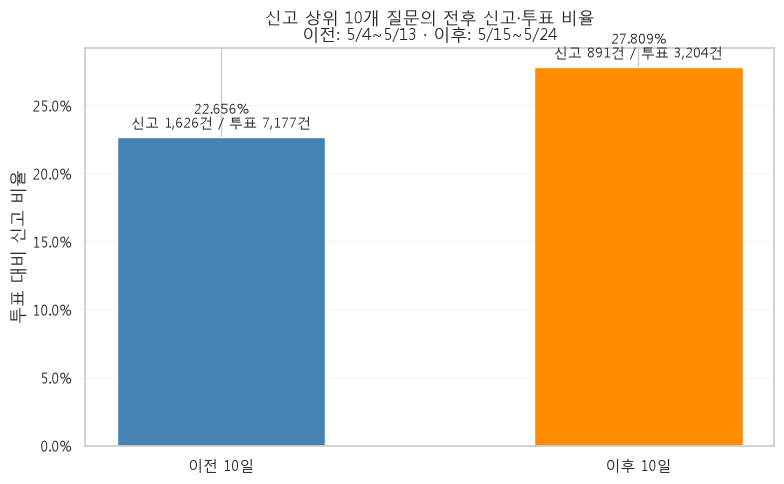

,구간,신고 건수,투표 건수,투표 대비 신고 비율(%)
0,이전 10일,1626,7177,22.656
1,이후 10일,891,3204,27.809


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 앞선 집계 셀에서 계산한 구간별 합계 사용
df_top10_before_after_plot = (
    df_top10_rate_total
    .reindex(["이전 10일", "이후 10일"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    df_top10_before_after_plot["구간"],
    df_top10_before_after_plot["투표 대비 신고 비율(%)"],
    color=["steelblue", "darkorange"],
    width=0.5,
)

for bar, (_, row) in zip(
    bars,
    df_top10_before_after_plot.iterrows(),
):
    if pd.isna(row["투표 대비 신고 비율(%)"]):
        continue

    ax.annotate(
        f"{row['투표 대비 신고 비율(%)']:.3f}%\n"
        f"신고 {int(row['신고 건수']):,}건 / "
        f"투표 {int(row['투표 건수']):,}건",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

ax.set_title(
    f"신고 상위 {len(top10_rate_ids)}개 질문의 전후 신고·투표 비율\n"
    "이전: 5/4~5/13 · 이후: 5/15~5/24"
)
ax.set_xlabel("")
ax.set_ylabel("투표 대비 신고 비율")
ax.set_ylim(bottom=0)
ax.margins(y=0.3)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

display(df_top10_before_after_plot.round(3))

### 최다 신고일 전후 일별 질문 수 변화


,날짜,신규 질문 수,누적 질문 수
0,2023-05-04,1,460
1,2023-05-05,0,460
2,2023-05-06,0,460
3,2023-05-07,0,460
4,2023-05-08,0,460
5,2023-05-09,0,460
6,2023-05-10,0,460
7,2023-05-11,89,549
8,2023-05-12,0,549
9,2023-05-13,0,549


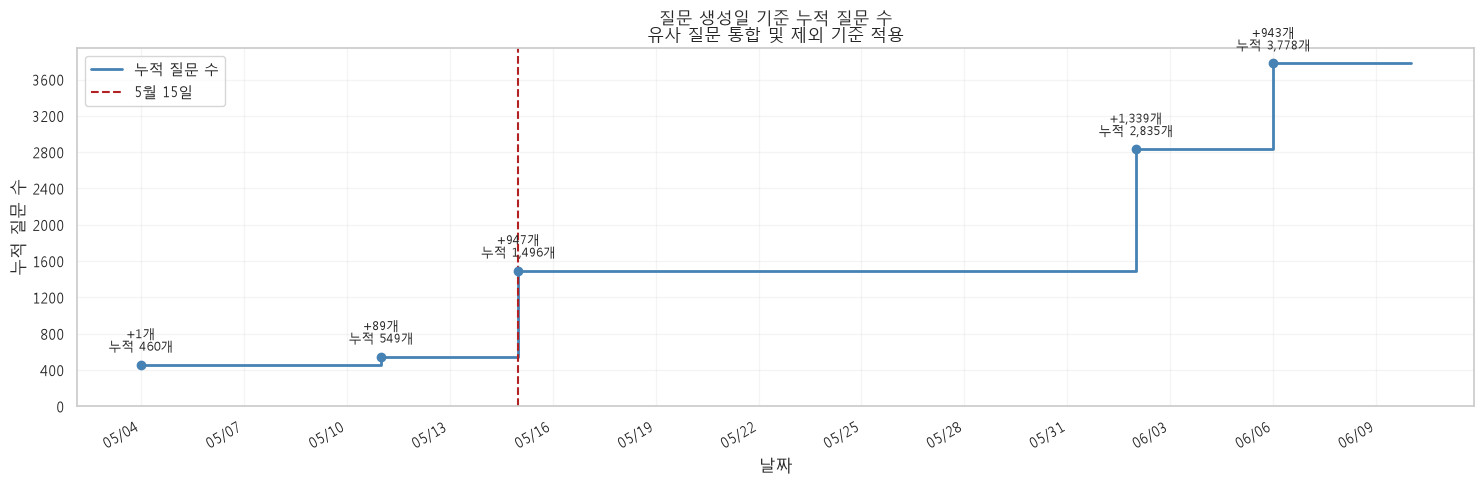

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

mapper = QuestionIdMapper()

# 표시 기간
creation_plot_start = pd.Timestamp("2023-05-04")
creation_plot_end = pd.Timestamp("2023-06-10")

# 1. 전체 원본 질문에 대표 질문 ID 적용
df_question_creation = df_question[[
    "id", "created_at"
]].copy()

df_question_creation["대표 질문 ID"] = mapper.transform(
    df_question_creation["id"]
)

df_question_creation["created_at"] = pd.to_datetime(
    df_question_creation["created_at"]
)

df_question_creation = df_question_creation.dropna(
    subset=["대표 질문 ID", "created_at"]
)

# 2. 대표 질문별 최초 생성일
df_representative_creation = (
    df_question_creation
    .groupby("대표 질문 ID")["created_at"]
    .min()
    .dt.normalize()
    .rename("최초 생성일")
    .reset_index()
)

if df_representative_creation.empty:
    raise ValueError("생성일을 확인할 수 있는 질문이 없습니다.")

# 3. 최초 생성일부터 누적 계산
creation_all_dates = pd.date_range(
    min(
        df_representative_creation["최초 생성일"].min(),
        creation_plot_start,
    ),
    creation_plot_end,
    freq="D",
)

df_cumulative_questions = (
    df_representative_creation
    .groupby("최초 생성일")["대표 질문 ID"]
    .nunique()
    .reindex(creation_all_dates, fill_value=0)
    .rename_axis("날짜")
    .reset_index(name="신규 질문 수")
)

df_cumulative_questions["누적 질문 수"] = (
    df_cumulative_questions["신규 질문 수"].cumsum()
)

# 표시 기간만 선택 — 이전 질문은 누적에 포함된 상태
df_cumulative_questions = (
    df_cumulative_questions.loc[
        df_cumulative_questions["날짜"].between(
            creation_plot_start,
            creation_plot_end,
        )
    ]
    .reset_index(drop=True)
)

display(df_cumulative_questions)

# 4. 그래프
fig, ax = plt.subplots(figsize=(15, 5))

ax.step(
    df_cumulative_questions["날짜"],
    df_cumulative_questions["누적 질문 수"],
    where="post",
    color="steelblue",
    linewidth=2,
    label="누적 질문 수",
)

# 신규 대표 질문이 추가된 날 표시
df_creation_addition_days = df_cumulative_questions.loc[
    df_cumulative_questions["신규 질문 수"].gt(0)
]

ax.scatter(
    df_creation_addition_days["날짜"],
    df_creation_addition_days["누적 질문 수"],
    color="steelblue",
    zorder=3,
)

for _, creation_row in df_creation_addition_days.iterrows():
    ax.annotate(
        f"+{creation_row['신규 질문 수']:,}개\n"
        f"누적 {creation_row['누적 질문 수']:,}개",
        xy=(
            creation_row["날짜"],
            creation_row["누적 질문 수"],
        ),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.axvline(
    pd.Timestamp("2023-05-15"),
    color="firebrick",
    linestyle="--",
    label="5월 15일",
)

ax.set_title(
    "질문 생성일 기준 누적 질문 수\n"
    "유사 질문 통합 및 제외 기준 적용"
)
ax.set_xlabel("날짜")
ax.set_ylabel("누적 질문 수")
ax.set_ylim(bottom=0)
ax.margins(y=0.2)

ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

ax.grid(alpha=0.2)
ax.legend()
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

### 질문 추가 전후 기존·신규 질문의 신고 추이


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\584355324.py:27: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  question_change_end + pd.Timedelta(days=1)


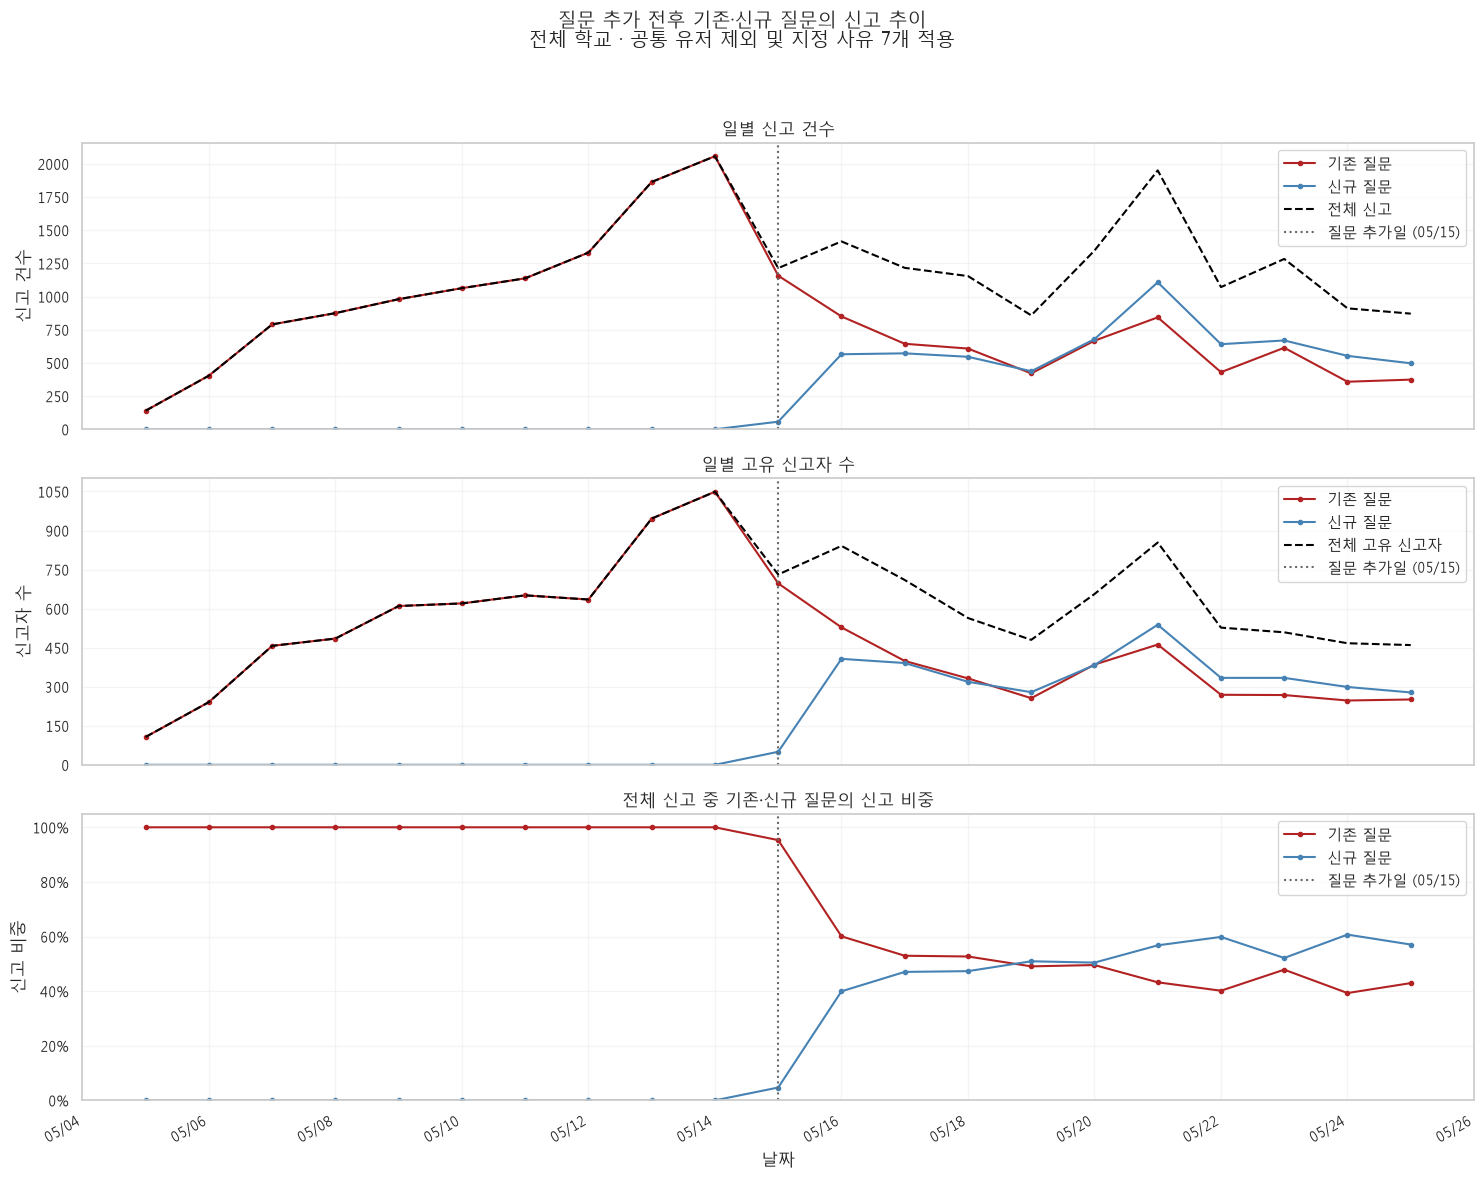

일별 신고 현황


,날짜,기존 질문 신고 건수,기존 질문 신고자 수,신규 질문 신고 건수,신규 질문 신고자 수,분류 확인 불가 신고 건수,분류 확인 불가 신고자 수,전체 신고 건수,전체 신고자 수,기존 질문 신고 비중(%),신규 질문 신고 비중(%)
0,2023-05-05,140,107,0,0,0,0,140,107,100.00,0.00
1,2023-05-06,404,241,0,0,0,0,404,241,100.00,0.00
2,2023-05-07,790,457,0,0,0,0,790,457,100.00,0.00
3,2023-05-08,875,485,0,0,0,0,875,485,100.00,0.00
4,2023-05-09,980,610,0,0,0,0,980,610,100.00,0.00
5,2023-05-10,1063,620,0,0,0,0,1063,620,100.00,0.00
6,2023-05-11,1137,651,0,0,0,0,1137,651,100.00,0.00
7,2023-05-12,1331,635,0,0,0,0,1331,635,100.00,0.00
8,2023-05-13,1863,946,0,0,0,0,1863,946,100.00,0.00
9,2023-05-14,2057,1049,0,0,0,0,2057,1049,100.00,0.00


추가 전후 요약


,비교 구간,질문 구분,신고 건수,고유 신고자 수,신고된 질문 수
0,추가 전,기존 질문,10640,4161,548
1,추가 전,신규 질문,0,0,0
2,추가 전,분류 확인 불가,0,0,0
3,추가 당일,기존 질문,1157,697,390
4,추가 당일,신규 질문,57,50,52
5,추가 당일,분류 확인 불가,0,0,0
6,추가 후,기존 질문,5809,2728,545
7,추가 후,신규 질문,6266,2794,934
8,추가 후,분류 확인 불가,0,0,0


In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator, PercentFormatter

question_change_mapper = QuestionIdMapper()

question_change_date = pd.Timestamp("2023-05-15")

# 기본 비교 기간: 추가일 전후 10일
# 필요하면 아래 날짜를 변경하시면 됩니다.
question_change_start = pd.Timestamp("2023-05-05")
question_change_end = pd.Timestamp("2023-05-25")  # 포함

question_change_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 조회 범위를 벗어난 날짜를 0건으로 처리하지 않도록 확인
question_change_end_exclusive = (
    question_change_end + pd.Timedelta(days=1)
)

if (
    pd.Timestamp(params["start_at"]) > question_change_start
    or pd.Timestamp(params["end_at"]) < question_change_end_exclusive
):
    raise ValueError(
        "비교 기간 전체가 원본 조회 범위에 포함되는지 확인해 주세요."
    )


# 1. 대표 질문 묶음의 최초 생성일
df_question_change_creation = df_question[
    ["id", "created_at"]
].copy()

df_question_change_creation["대표 질문 ID"] = (
    question_change_mapper.transform(
        df_question_change_creation["id"]
    )
)

df_question_change_creation["질문 생성 시각"] = pd.to_datetime(
    df_question_change_creation["created_at"],
    errors="raise",
)

df_question_change_creation = (
    df_question_change_creation
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID", as_index=False)
    .agg(
        최초_생성_시각=("질문 생성 시각", "min"),
        생성일_결측_있음=(
            "질문 생성 시각", lambda s: s.isna().any()
        ),
    )
    .rename(columns={"최초_생성_시각": "최초 생성 시각"})
)

df_question_change_creation["질문 구분"] = "분류 확인 불가"

question_change_known_creation = (
    df_question_change_creation["최초 생성 시각"].notna()
    & ~df_question_change_creation["생성일_결측_있음"]
)

df_question_change_creation.loc[
    question_change_known_creation
    & df_question_change_creation["최초 생성 시각"].lt(
        question_change_date
    ),
    "질문 구분",
] = "기존 질문"

df_question_change_creation.loc[
    question_change_known_creation
    & df_question_change_creation["최초 생성 시각"].ge(
        question_change_date
    ),
    "질문 구분",
] = "신규 질문"


# 2. 전체 학교 범위의 지정 사유 신고
df_question_change_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(question_change_reasons),
        ["id", "user_id", "대표 질문 ID", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_question_change_reports["신고 시각"] = pd.to_datetime(
    df_question_change_reports["created_at"],
    errors="raise",
)

df_question_change_reports["날짜"] = (
    df_question_change_reports["신고 시각"].dt.normalize()
)

df_question_change_reports = (
    df_question_change_reports.loc[
        df_question_change_reports["신고 시각"].ge(
            question_change_start
        )
        & df_question_change_reports["신고 시각"].lt(
            question_change_end_exclusive
        )
    ]
    .merge(
        df_question_change_creation[[
            "대표 질문 ID",
            "최초 생성 시각",
            "질문 구분",
        ]],
        on="대표 질문 ID",
        how="left",
        validate="many_to_one",
    )
)

df_question_change_reports["질문 구분"] = (
    df_question_change_reports["질문 구분"]
    .fillna("분류 확인 불가")
)

# 生成時刻より前の 신고가 있으면 연결 데이터 확인
question_change_invalid_time = (
    df_question_change_reports["최초 생성 시각"].notna()
    & df_question_change_reports["신고 시각"].lt(
        df_question_change_reports["최초 생성 시각"]
    )
)

if question_change_invalid_time.any():
    raise ValueError(
        "질문 최초 생성 시각보다 이른 신고가 있습니다. "
        "날짜·시간대 또는 질문 매핑을 확인해 주세요."
    )


# 3. 날짜별 신고 건수
question_change_dates = pd.date_range(
    question_change_start,
    question_change_end,
    freq="D",
)

question_change_types = [
    "기존 질문",
    "신규 질문",
    "분류 확인 불가",
]

df_question_change_daily_counts = (
    df_question_change_reports
    .groupby(["날짜", "질문 구분"])["id"]
    .nunique()
    .unstack("질문 구분", fill_value=0)
    .reindex(
        index=question_change_dates,
        columns=question_change_types,
        fill_value=0,
    )
    .rename_axis(index="날짜", columns=None)
)

# 날짜별 유형별 고유 신고자 수
df_question_change_daily_users = (
    df_question_change_reports
    .groupby(["날짜", "질문 구분"])["user_id"]
    .nunique()
    .unstack("질문 구분", fill_value=0)
    .reindex(
        index=question_change_dates,
        columns=question_change_types,
        fill_value=0,
    )
    .rename_axis(index="날짜", columns=None)
)

# 날짜별 전체 고유 신고자 수
# 기존·신규 모두 신고한 유저는 한 번만 계산
question_change_total_users = (
    df_question_change_reports
    .groupby("날짜")["user_id"]
    .nunique()
    .reindex(question_change_dates, fill_value=0)
)


# 4. 일별 집계표
df_question_change_daily = pd.DataFrame(
    index=question_change_dates
)

for question_type in question_change_types:
    df_question_change_daily[f"{question_type} 신고 건수"] = (
        df_question_change_daily_counts[question_type]
    )
    df_question_change_daily[f"{question_type} 신고자 수"] = (
        df_question_change_daily_users[question_type]
    )

df_question_change_daily["전체 신고 건수"] = (
    df_question_change_daily_counts.sum(axis=1)
)

df_question_change_daily["전체 신고자 수"] = (
    question_change_total_users
)

for question_type in ["기존 질문", "신규 질문"]:
    df_question_change_daily[f"{question_type} 신고 비중(%)"] = (
        df_question_change_daily[f"{question_type} 신고 건수"]
        .div(
            df_question_change_daily["전체 신고 건수"].where(
                df_question_change_daily["전체 신고 건수"].gt(0)
            )
        )
        .mul(100)
    )

df_question_change_daily = (
    df_question_change_daily
    .rename_axis("날짜")
    .reset_index()
)


# 5. 추가 전후 요약 — 기간 전체에서 고유 신고자 중복 제거
df_question_change_reports["비교 구간"] = "추가 당일"

df_question_change_reports.loc[
    df_question_change_reports["날짜"].lt(question_change_date),
    "비교 구간",
] = "추가 전"

df_question_change_reports.loc[
    df_question_change_reports["날짜"].gt(question_change_date),
    "비교 구간",
] = "추가 후"

df_question_change_period_summary = (
    df_question_change_reports
    .groupby(["비교 구간", "질문 구분"])
    .agg(
        신고_건수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
        신고된_질문_수=("대표 질문 ID", "nunique"),
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                ["추가 전", "추가 당일", "추가 후"],
                question_change_types,
            ],
            names=["비교 구간", "질문 구분"],
        ),
        fill_value=0,
    )
    .reset_index()
    .rename(columns={
        "신고_건수": "신고 건수",
        "고유_신고자_수": "고유 신고자 수",
        "신고된_질문_수": "신고된 질문 수",
    })
)


# 6. 그래프
fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 12),
    sharex=True,
)

question_change_colors = {
    "기존 질문": "firebrick",
    "신규 질문": "steelblue",
    "분류 확인 불가": "gray",
}

for question_type in question_change_types:
    # 기록이 없는 확인 불가 유형은 그래프에서 생략
    if (
        question_type == "분류 확인 불가"
        and df_question_change_daily[
            f"{question_type} 신고 건수"
        ].sum() == 0
    ):
        continue

    axes[0].plot(
        df_question_change_daily["날짜"],
        df_question_change_daily[f"{question_type} 신고 건수"],
        marker="o",
        markersize=3,
        color=question_change_colors[question_type],
        label=question_type,
    )

    axes[1].plot(
        df_question_change_daily["날짜"],
        df_question_change_daily[f"{question_type} 신고자 수"],
        marker="o",
        markersize=3,
        color=question_change_colors[question_type],
        label=question_type,
    )

axes[0].plot(
    df_question_change_daily["날짜"],
    df_question_change_daily["전체 신고 건수"],
    color="black",
    linestyle="--",
    label="전체 신고",
)

axes[0].set_title("일별 신고 건수")
axes[0].set_ylabel("신고 건수")

axes[1].plot(
    df_question_change_daily["날짜"],
    df_question_change_daily["전체 신고자 수"],
    color="black",
    linestyle="--",
    label="전체 고유 신고자",
)

axes[1].set_title("일별 고유 신고자 수")
axes[1].set_ylabel("신고자 수")

for question_type in ["기존 질문", "신규 질문"]:
    axes[2].plot(
        df_question_change_daily["날짜"],
        df_question_change_daily[f"{question_type} 신고 비중(%)"],
        marker="o",
        markersize=3,
        color=question_change_colors[question_type],
        label=question_type,
    )

axes[2].set_title("전체 신고 중 기존·신규 질문의 신고 비중")
axes[2].set_ylabel("신고 비중")
axes[2].set_xlabel("날짜")
axes[2].set_ylim(0, 105)
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=100))

for ax in axes:
    ax.axvline(
        question_change_date,
        color="dimgray",
        linestyle=":",
        linewidth=1.5,
        label="질문 추가일 (05/15)",
    )
    ax.grid(alpha=0.2)
    ax.legend(loc="best")

for ax in axes[:2]:
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

axes[2].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

fig.suptitle(
    "질문 추가 전후 기존·신규 질문의 신고 추이\n"
    "전체 학교 · 공통 유저 제외 및 지정 사유 7개 적용",
    fontsize=14,
)

fig.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("일별 신고 현황")
display(df_question_change_daily.round(2))

print("추가 전후 요약")
display(df_question_change_period_summary)

## 신고자의 서비스 이용 특성


### 5/14~6/13 투표자의 재투표율 및 재투표일 수


In [28]:
import numpy as np
import pandas as pd

# 기준 투표자 선정 기간
trim_return_start = pd.Timestamp("2023-05-14")
trim_return_end = pd.Timestamp("2023-06-14")  # 6월 13일까지 포함
trim_return_ratio = 0.10  # 양쪽 각각 10% 절사

# 1. 전체 투표 기록
# 이후 재투표 확인을 위해 6월 13일 이후 기록도 유지
df_trim_return_votes = (
    df_userquestionrecord[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_trim_return_votes["투표 시각"] = pd.to_datetime(
    df_trim_return_votes["created_at"],
    errors="raise",
)

df_trim_return_votes["투표일"] = (
    df_trim_return_votes["투표 시각"].dt.normalize()
)

# 2. 5/14~6/13에 투표한 유저별 기간 내 첫 투표일
df_trim_return_cohort = (
    df_trim_return_votes.loc[
        df_trim_return_votes["투표 시각"].ge(trim_return_start)
        & df_trim_return_votes["투표 시각"].lt(trim_return_end)
    ]
    .groupby("user_id")["투표일"]
    .min()
    .reset_index(name="기준일")
)

if df_trim_return_cohort.empty:
    raise ValueError("선정 기간에 투표한 유저가 없습니다.")

# 모든 유저의 이후 30일이 조회 범위에 포함되는지 확인
if (
    df_trim_return_cohort["기준일"]
    + pd.Timedelta(days=31)
).gt(pd.Timestamp(params["end_at"])).any():
    raise ValueError("일부 유저의 기준일 이후 30일을 조회할 수 없습니다.")

# 3. 전체 조회 기간의 신고 여부로 집단 고정
# 원본 신고 사용: 신고 사유·공통 유저 제외 조건 미적용
df_trim_return_reports = (
    df_questionreport[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_trim_return_reports["신고 시각"] = pd.to_datetime(
    df_trim_return_reports["created_at"],
    errors="raise",
)

trim_return_reporter_ids = set(
    df_trim_return_reports.loc[
        df_trim_return_reports["신고 시각"].ge(
            pd.Timestamp(params["start_at"])
        )
        & df_trim_return_reports["신고 시각"].lt(
            pd.Timestamp(params["end_at"])
        ),
        "user_id",
    ]
)

df_trim_return_cohort["집단"] = (
    df_trim_return_cohort["user_id"]
    .isin(trim_return_reporter_ids)
    .map({True: "신고자", False: "비신고자"})
)

# 4. 개인별 기준일 이후 투표 연결
df_trim_return_detail = (
    df_trim_return_cohort[["user_id", "기준일"]]
    .merge(
        df_trim_return_votes[["user_id", "투표일"]]
        .drop_duplicates(),
        on="user_id",
        how="inner",
        validate="one_to_many",
    )
)

df_trim_return_detail["경과일"] = (
    df_trim_return_detail["투표일"]
    - df_trim_return_detail["기준일"]
).dt.days

# 같은 날 제외, 이후 30일만 포함
df_trim_return_detail = (
    df_trim_return_detail.loc[
        df_trim_return_detail["경과일"].between(1, 30)
    ]
    .copy()
)

# 5. 개인별 1일·7일·30일 내 고유 재투표일 수
df_trim_return_users = df_trim_return_cohort.copy()

for days in [1, 7, 30]:
    day_counts = (
        df_trim_return_detail.loc[
            df_trim_return_detail["경과일"].between(1, days)
        ]
        .groupby("user_id")["투표일"]
        .nunique()
    )

    df_trim_return_users[f"{days}일 내 재투표일 수"] = (
        df_trim_return_users["user_id"]
        .map(day_counts)
        .fillna(0)
        .astype(int)
    )

# 6. 집단별 재투표율 및 양측 10% 절사평균
trim_return_rows = []

for group in ["신고자", "비신고자"]:
    group_users = df_trim_return_users.loc[
        df_trim_return_users["집단"].eq(group)
    ]

    for days in [1, 7, 30]:
        counts = group_users[f"{days}일 내 재투표일 수"]

        # 절사평균에서는 0일 제외
        positive_values = np.sort(
            counts.loc[counts.gt(0)].to_numpy()
        )

        trim_count = int(len(positive_values) * trim_return_ratio)

        trimmed_values = (
            positive_values[trim_count:-trim_count]
            if trim_count > 0
            else positive_values
        )

        trim_return_rows.append({
            "집단": group,
            "구간": f"{days}일 내",
            "전체 대상 유저 수": len(group_users),
            "재투표 유저 수": len(positive_values),
            "재투표율(%)": (
                counts.gt(0).mean() * 100
                if len(group_users) else float("nan")
            ),
            "재투표자 평균 재투표일 수": (
                positive_values.mean()
                if len(positive_values) else float("nan")
            ),
            "각 꼬리 절사 인원": trim_count,
            "절사평균 재투표일 수": (
                trimmed_values.mean()
                if len(trimmed_values) else float("nan")
            ),
        })

df_trim_return_summary = pd.DataFrame(trim_return_rows)

print("기준 투표자 선정: 2023-05-14 ~ 2023-06-13")
print("개인별 기준일: 선정 기간 내 첫 투표일")
print("후속 투표 확인: 각 기준일 다음 날부터 30일간")
print("최대 후속 관측일: 2023-07-13")

display(df_trim_return_summary.round(3))


기준 투표자 선정: 2023-05-14 ~ 2023-06-13
개인별 기준일: 선정 기간 내 첫 투표일
후속 투표 확인: 각 기준일 다음 날부터 30일간
최대 후속 관측일: 2023-07-13


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1801201596.py:44: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=31)


,집단,구간,전체 대상 유저 수,재투표 유저 수,재투표율(%),재투표자 평균 재투표일 수,각 꼬리 절사 인원,절사평균 재투표일 수
0,신고자,1일 내,150,126,84.000,1.000,12,1.000
1,신고자,7일 내,150,139,92.667,4.942,13,5.124
2,신고자,30일 내,150,139,92.667,9.266,13,8.823
3,비신고자,1일 내,4032,2838,70.387,1.000,283,1.000
4,비신고자,7일 내,4032,3459,85.789,4.460,345,4.575
5,비신고자,30일 내,4032,3612,89.583,7.519,361,6.900


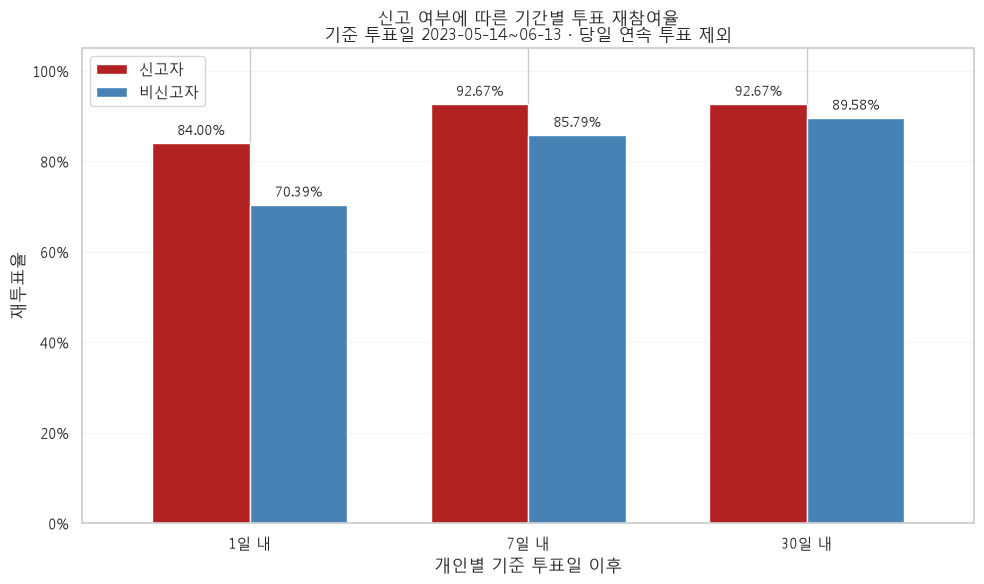

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 기존 집계 결과 사용
df_revote_rate_plot = (
    df_trim_return_summary
    .pivot(
        index="구간",
        columns="집단",
        values="재투표율(%)",
    )
    .reindex(
        index=["1일 내", "7일 내", "30일 내"],
        columns=["신고자", "비신고자"],
    )
)

ax = df_revote_rate_plot.plot.bar(
    figsize=(10, 6),
    color=["firebrick", "steelblue"],
    width=0.7,
    rot=0,
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4,
        fontsize=10,
    )

ax.set_title(
    "신고 여부에 따른 기간별 투표 재참여율\n"
    "기준 투표일 2023-05-14~06-13 · 당일 연속 투표 제외"
)
ax.set_xlabel("개인별 기준 투표일 이후")
ax.set_ylabel("재투표율")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="")

plt.tight_layout()
plt.show()

### 5/14~6/13 신고자·비신고자의 구매 기록


In [30]:
import pandas as pd

purchase_period_start = pd.Timestamp("2023-05-14")
purchase_period_end = pd.Timestamp("2023-06-14")  # 미포함

# 1. 기간 시작 전에 가입한 일반 유저
df_period_purchase_users = (
    df_user[["id", "created_at"]]
    .rename(columns={
        "id": "user_id",
        "created_at": "가입 시각",
    })
    .drop_duplicates("user_id")
    .copy()
)

df_period_purchase_users["가입 시각"] = pd.to_datetime(
    df_period_purchase_users["가입 시각"],
    errors="raise",
)

df_period_purchase_users = (
    df_period_purchase_users.loc[
        df_period_purchase_users["가입 시각"].lt(
            purchase_period_start
        )
    ]
    .copy()
)

# 2. 같은 기간의 질문 신고
# 원본 신고 전체 사용: 사유·공통 유저 제외 조건 미적용
df_period_purchase_reports = (
    df_questionreport[["id", "user_id", "created_at"]]
    .drop_duplicates("id")
    .copy()
)

df_period_purchase_reports["신고 시각"] = pd.to_datetime(
    df_period_purchase_reports["created_at"],
    errors="raise",
)

period_purchase_reporter_ids = set(
    df_period_purchase_reports.loc[
        df_period_purchase_reports["신고 시각"].ge(
            purchase_period_start
        )
        & df_period_purchase_reports["신고 시각"].lt(
            purchase_period_end
        ),
        "user_id",
    ].dropna()
)

df_period_purchase_users["집단"] = (
    df_period_purchase_users["user_id"]
    .isin(period_purchase_reporter_ids)
    .map({
        True: "기간 내 신고자",
        False: "기간 내 비신고자",
    })
)

# 3. 같은 기간의 구매 기록
df_period_purchase_records = (
    df_paymenthistory[["id", "user_id", "created_at"]]
    .drop_duplicates("id")
    .copy()
)

df_period_purchase_records["구매 시각"] = pd.to_datetime(
    df_period_purchase_records["created_at"],
    errors="raise",
)

df_period_purchase_records = (
    df_period_purchase_records.loc[
        df_period_purchase_records["구매 시각"].ge(
            purchase_period_start
        )
        & df_period_purchase_records["구매 시각"].lt(
            purchase_period_end
        )
    ]
    .copy()
)

period_purchase_counts = (
    df_period_purchase_records
    .groupby("user_id")["id"]
    .nunique()
    .rename("기간 내 구매 횟수")
    .reset_index()
)

# 구매하지 않은 유저도 유지
df_period_purchase_result = (
    df_period_purchase_users
    .merge(
        period_purchase_counts,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

df_period_purchase_result["기간 내 구매 횟수"] = (
    df_period_purchase_result["기간 내 구매 횟수"]
    .fillna(0)
    .astype(int)
)

# 4. 신고자·비신고자 비교
df_period_purchase_summary = (
    df_period_purchase_result
    .groupby("집단")
    .agg(
        유저_수=("user_id", "nunique"),
        구매_유저_수=(
            "기간 내 구매 횟수", lambda s: s.gt(0).sum()
        ),
        구매_기록_수=("기간 내 구매 횟수", "sum"),
        유저당_평균_구매_횟수=("기간 내 구매 횟수", "mean"),
        구매자당_평균_구매_횟수=(
            "기간 내 구매 횟수",
            lambda s: s.loc[s.gt(0)].mean(),
        ),
    )
    .reindex(["기간 내 신고자", "기간 내 비신고자"])
    .rename(columns={
        "유저_수": "유저 수",
        "구매_유저_수": "구매 유저 수",
        "구매_기록_수": "구매 기록 수",
        "유저당_평균_구매_횟수": "전체 유저당 평균 구매 횟수",
        "구매자당_평균_구매_횟수": "구매자당 평균 구매 횟수",
    })
)

df_period_purchase_summary["구매 기록 보유율(%)"] = (
    df_period_purchase_summary["구매 유저 수"]
    .div(
        df_period_purchase_summary["유저 수"].where(
            df_period_purchase_summary["유저 수"].gt(0)
        )
    )
    .mul(100)
)

print("분석 기간: 2023-05-14 ~ 2023-06-13")
print("대상: 5월 14일 이전 가입한 일반 유저")

display(
    df_period_purchase_summary.reset_index()[[
        "집단",
        "유저 수",
        "구매 유저 수",
        "구매 기록 보유율(%)",
        "구매 기록 수",
        "전체 유저당 평균 구매 횟수",
        "구매자당 평균 구매 횟수",
    ]].round(3)
)

분석 기간: 2023-05-14 ~ 2023-06-13
대상: 5월 14일 이전 가입한 일반 유저


,집단,유저 수,구매 유저 수,구매 기록 보유율(%),구매 기록 수,전체 유저당 평균 구매 횟수,구매자당 평균 구매 횟수
0,기간 내 신고자,6641,1015,15.284,1803,0.271,1.776
1,기간 내 비신고자,358020,24189,6.756,36789,0.103,1.521


## 개선 대상 질문 선정 및 제외 시뮬레이션


### 체취 질문의 신고 비율 및 제외 전후 비교


In [31]:
import pandas as pd

odor_threshold_mapper = QuestionIdMapper()
odor_report_threshold = 5.0

# 1. 최종 라벨링의 체취 질문
df_odor_threshold_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "대표 질문명", "라벨링"]]
    .copy()
)

df_odor_threshold_labels["대표 질문 ID"] = pd.to_numeric(
    df_odor_threshold_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_odor_threshold_labels["대표 질문 ID"].isna().any()
    or df_odor_threshold_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_odor_threshold_labels = (
    df_odor_threshold_labels.loc[
        df_odor_threshold_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("체취"),
        ["대표 질문 ID", "대표 질문명"],
    ]
    .copy()
)

# 2. 여학생 — 공통 유저 제외 조건 유지
odor_threshold_female_ids = set(
    df_user.loc[
        df_user["gender"].eq("F")
        & ~df_user["id"].isin(excluded_reporter_ids),
        "id",
    ]
)

# 3. 질문별 지정 사유 신고 건수
df_odor_threshold_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            odor_threshold_female_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_odor_threshold_reports["대표 질문 ID"] = pd.to_numeric(
    df_odor_threshold_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

odor_threshold_report_counts = (
    df_odor_threshold_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 신고 건수")
    .reset_index()
)

# 4. 질문별 여학생 직접 투표 건수
df_odor_threshold_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(
            odor_threshold_female_ids
        ),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_odor_threshold_votes["대표 질문 ID"] = (
    odor_threshold_mapper.transform(
        df_odor_threshold_votes["question_id"]
    )
)

odor_threshold_vote_counts = (
    df_odor_threshold_votes
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 투표 건수")
    .reset_index()
)

# 5. 체취 질문별 신고·투표 비율
df_odor_question_rates = (
    df_odor_threshold_labels
    .merge(
        odor_threshold_report_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .merge(
        odor_threshold_vote_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

odor_threshold_count_columns = [
    "여학생 신고 건수",
    "여학생 투표 건수",
]

df_odor_question_rates[odor_threshold_count_columns] = (
    df_odor_question_rates[odor_threshold_count_columns]
    .fillna(0)
    .astype(int)
)

# 투표 0건이면 계산 불가로 유지
df_odor_question_rates["투표 대비 신고 비율(%)"] = (
    df_odor_question_rates["여학생 신고 건수"]
    .div(
        df_odor_question_rates["여학생 투표 건수"].where(
            df_odor_question_rates["여학생 투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 6. 반올림 전 값으로 5% 이상 선정
df_odor_questions_above_5 = (
    df_odor_question_rates.loc[
        df_odor_question_rates["투표 대비 신고 비율(%)"]
        .ge(odor_report_threshold)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

df_odor_questions_above_5.insert(
    0, "순위", range(1, len(df_odor_questions_above_5) + 1)
)

print(f"체취 전체 질문: {len(df_odor_question_rates):,}개")
print(
    "투표 대비 신고 비율 5% 이상 질문:",
    f"{len(df_odor_questions_above_5):,}개",
)

display(df_odor_questions_above_5.round(3))

체취 전체 질문: 21개
투표 대비 신고 비율 5% 이상 질문: 10개


,순위,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,704,49.290
1,2,2559,발에서 블루베리 향 날 것 같은 사람은?,3,10,30.000
2,3,2074,입에서 향기가 날 것 같은 사람,2,8,25.000
3,4,2512,복숭아 향이 잘 어울리는 친구는?,3,13,23.077
4,5,2076,입냄새가 가장 좋을 것 같은 사람은?,2,9,22.222
5,6,144,발냄새가 가장 향긋할 것 같은 사람은?,130,654,19.878
6,7,1281,발에서 향기날것 같은 사람,31,175,17.714
7,8,362,땀냄새가 가장 좋을 것 같은 사람은?,92,555,16.577
8,9,1532,이 사람의 발냄새 만큼은 용서 된다,20,124,16.129
9,10,416,발가락에서 페브리즈향이 날 것 같은 사람은?,110,701,15.692


In [32]:
# 1. 신고·투표 비율이 5%를 초과하는 질문 중 상위 10개
df_odor_remove_over5_top10 = (
    df_odor_question_rates.loc[
        df_odor_question_rates["투표 대비 신고 비율(%)"].gt(5)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .copy()
)

odor_remove_over5_ids = set(
    df_odor_remove_over5_top10["대표 질문 ID"]
)

# 2. 제외 후 남은 체취 질문
df_odor_remaining_after_top10 = (
    df_odor_question_rates.loc[
        ~df_odor_question_rates["대표 질문 ID"].isin(
            odor_remove_over5_ids
        )
    ]
    .copy()
)

# 3. 제외 전후 카테고리 전체 비율
odor_top10_removal_rows = []

for label, source in [
    ("제외 전", df_odor_question_rates),
    ("5% 초과 상위 10개 제외 후", df_odor_remaining_after_top10),
]:
    report_total = source["여학생 신고 건수"].sum()
    vote_total = source["여학생 투표 건수"].sum()

    odor_top10_removal_rows.append({
        "구분": label,
        "체취 질문 수": len(source),
        "여학생 신고 건수": report_total,
        "여학생 투표 건수": vote_total,
        "투표 대비 신고 비율(%)": (
            report_total / vote_total * 100
            if vote_total else float("nan")
        ),
    })

df_odor_top10_removal_summary = pd.DataFrame(
    odor_top10_removal_rows
)

print(f"실제 제외 질문 수: {len(odor_remove_over5_ids):,}개")

print("\n[제외 질문]")
display(df_odor_remove_over5_top10.round(3))

print("\n[체취 카테고리 제외 전후 비교]")
display(df_odor_top10_removal_summary.round(3))

실제 제외 질문 수: 10개

[제외 질문]


,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
4,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,704,49.290
18,2559,발에서 블루베리 향 날 것 같은 사람은?,3,10,30.000
14,2074,입에서 향기가 날 것 같은 사람,2,8,25.000
16,2512,복숭아 향이 잘 어울리는 친구는?,3,13,23.077
15,2076,입냄새가 가장 좋을 것 같은 사람은?,2,9,22.222
0,144,발냄새가 가장 향긋할 것 같은 사람은?,130,654,19.878
6,1281,발에서 향기날것 같은 사람,31,175,17.714
2,362,땀냄새가 가장 좋을 것 같은 사람은?,92,555,16.577
7,1532,이 사람의 발냄새 만큼은 용서 된다,20,124,16.129
5,416,발가락에서 페브리즈향이 날 것 같은 사람은?,110,701,15.692



[체취 카테고리 제외 전후 비교]


,구분,체취 질문 수,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,제외 전,21,782,4591,17.033
1,5% 초과 상위 10개 제외 후,11,42,1638,2.564


### 여학생 유머 질문의 신고 비율 및 제외 전후 비교


In [33]:
import pandas as pd

female_humor_mapper = QuestionIdMapper()

# 1. 최종 라벨링의 유머 질문
df_female_humor_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "대표 질문명", "라벨링"]]
    .copy()
)

df_female_humor_labels["대표 질문 ID"] = pd.to_numeric(
    df_female_humor_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_female_humor_labels["대표 질문 ID"].isna().any()
    or df_female_humor_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_female_humor_labels = (
    df_female_humor_labels.loc[
        df_female_humor_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("유머"),
        ["대표 질문 ID", "대표 질문명"],
    ]
    .copy()
)

# 2. 여학생 — 공통 유저 제외 조건 유지
female_humor_user_ids = set(
    df_user.loc[
        df_user["gender"].eq("F")
        & ~df_user["id"].isin(excluded_reporter_ids),
        "id",
    ]
)

# 3. 질문별 지정 사유 신고 건수
df_female_humor_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            female_humor_user_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_female_humor_reports["대표 질문 ID"] = pd.to_numeric(
    df_female_humor_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

female_humor_report_counts = (
    df_female_humor_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 신고 건수")
    .reset_index()
)

# 4. 질문별 여학생 직접 투표 건수
df_female_humor_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(
            female_humor_user_ids
        ),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_female_humor_votes["대표 질문 ID"] = (
    female_humor_mapper.transform(
        df_female_humor_votes["question_id"]
    )
)

female_humor_vote_counts = (
    df_female_humor_votes
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("여학생 투표 건수")
    .reset_index()
)

# 5. 유머 질문 전체의 비율 계산
df_female_humor_question_rates = (
    df_female_humor_labels
    .merge(
        female_humor_report_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
    .merge(
        female_humor_vote_counts,
        on="대표 질문 ID",
        how="left",
        validate="one_to_one",
    )
)

female_humor_count_columns = [
    "여학생 신고 건수",
    "여학생 투표 건수",
]

df_female_humor_question_rates[female_humor_count_columns] = (
    df_female_humor_question_rates[female_humor_count_columns]
    .fillna(0)
    .astype(int)
)

# 투표가 0건이면 비율은 결측으로 유지
df_female_humor_question_rates["투표 대비 신고 비율(%)"] = (
    df_female_humor_question_rates["여학생 신고 건수"]
    .div(
        df_female_humor_question_rates["여학생 투표 건수"].where(
            df_female_humor_question_rates["여학생 투표 건수"].gt(0)
        )
    )
    .mul(100)
)

# 6. 투표 100건 이상·신고 비율 5% 이상
# 반올림 전 값으로 조건 적용
df_female_humor_above5 = (
    df_female_humor_question_rates.loc[
        df_female_humor_question_rates["여학생 투표 건수"].ge(100)
        & df_female_humor_question_rates["투표 대비 신고 비율(%)"]
        .ge(5)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

print(f"유머 전체 질문: {len(df_female_humor_question_rates):,}개")
print(
    "투표 100건 이상·신고 비율 5% 이상 질문:",
    f"{len(df_female_humor_above5):,}개",
)

display(df_female_humor_above5.round(3))

유머 전체 질문: 59개
투표 100건 이상·신고 비율 5% 이상 질문: 9개


,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,1471,두번째 발가락이 가장 길 것 같은 사람은?,45,168,26.786
1,1317,백태 없을 것 같은 사람은?,37,140,26.429
2,935,미래의 자녀가 마라탕 사장이 되길 바랄 것 같은 사람,26,196,13.265
3,1502,비행기 신발 벗고 탈 것 같은 사람은?,19,191,9.948
4,1131,팔꿈치에 혀 닿을 것 같은 친구,13,163,7.975
5,1524,얼굴을 가장 막 쓰는 사람은?,12,172,6.977
6,1351,입에 마시멜로우 제일 많이 들어갈 것 같은 사람,12,191,6.283
7,1181,사계절 내내 추위 많이타는 사람은?,10,160,6.250
8,520,맛있는 거 먹을 때 이 표정인 친구는?,42,760,5.526


In [34]:
# 1. 투표 100건 이상·신고 비율 5% 이상 질문 전체 선정
df_female_humor_remove_over5 = (
    df_female_humor_question_rates.loc[
        df_female_humor_question_rates["여학생 투표 건수"].ge(100)
        & df_female_humor_question_rates["투표 대비 신고 비율(%)"]
        .ge(5)
    ]
    .sort_values(
        ["투표 대비 신고 비율(%)", "여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, False, True],
    )
    .copy()
)

female_humor_remove_ids = set(
    df_female_humor_remove_over5["대표 질문 ID"]
)

# 2. 선정 질문의 신고·투표를 함께 제외
# 투표 100건 미만인 질문은 삭제하지 않고 유지
df_female_humor_remaining = (
    df_female_humor_question_rates.loc[
        ~df_female_humor_question_rates["대표 질문 ID"].isin(
            female_humor_remove_ids
        )
    ]
    .copy()
)

# 3. 제외 전후 카테고리 전체 비율
female_humor_removal_rows = []

for label, source in [
    ("제외 전", df_female_humor_question_rates),
    ("투표 100건 이상·신고 비율 5% 이상 질문 제외 후",
     df_female_humor_remaining),
]:
    report_total = source["여학생 신고 건수"].sum()
    vote_total = source["여학생 투표 건수"].sum()

    female_humor_removal_rows.append({
        "구분": label,
        "유머 질문 수": len(source),
        "여학생 신고 건수": report_total,
        "여학생 투표 건수": vote_total,
        "투표 대비 신고 비율(%)": (
            report_total / vote_total * 100
            if vote_total else float("nan")
        ),
    })

df_female_humor_removal_summary = pd.DataFrame(
    female_humor_removal_rows
)

print(f"제외 질문 수: {len(female_humor_remove_ids):,}개")

print("\n[제외 질문]")
display(df_female_humor_remove_over5.round(3))

print("\n[유머 카테고리 제외 전후 비교]")
display(df_female_humor_removal_summary.round(3))

제외 질문 수: 9개

[제외 질문]


,대표 질문 ID,대표 질문명,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
14,1471,두번째 발가락이 가장 길 것 같은 사람은?,45,168,26.786
11,1317,백태 없을 것 같은 사람은?,37,140,26.429
4,935,미래의 자녀가 마라탕 사장이 되길 바랄 것 같은 사람,26,196,13.265
15,1502,비행기 신발 벗고 탈 것 같은 사람은?,19,191,9.948
6,1131,팔꿈치에 혀 닿을 것 같은 친구,13,163,7.975
17,1524,얼굴을 가장 막 쓰는 사람은?,12,172,6.977
13,1351,입에 마시멜로우 제일 많이 들어갈 것 같은 사람,12,191,6.283
7,1181,사계절 내내 추위 많이타는 사람은?,10,160,6.250
0,520,맛있는 거 먹을 때 이 표정인 친구는?,42,760,5.526



[유머 카테고리 제외 전후 비교]


,구분,유머 질문 수,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,제외 전,59,331,5410,6.118
1,투표 100건 이상·신고 비율 5% 이상 질문 제외 후,50,115,3269,3.518


# 부록


### 전처리한 질문 CSV 파일로 내보내기


In [37]:
from pathlib import Path

save_path = Path.cwd() / "대표질문_통합목록.csv"

if save_path.exists():
    print(f"파일이 이미 있어 실행을 건너뜁니다: {save_path.resolve()}")

else:
    mapper = QuestionIdMapper()

    df_question_export = df_question[
        ["id", "question_text"]
    ].copy()

    df_question_export["대표 질문 ID"] = mapper.transform(
        df_question_export["id"]
    )

    # 제외 대상 질문 제거
    df_question_export = df_question_export.dropna(
        subset=["대표 질문 ID"]
    )

    # 같은 묶음에 포함된 원본 ID 보관
    df_question_export = (
        df_question_export
        .groupby("대표 질문 ID")
        .agg(
            원본_질문_ID=("id", lambda s: ", ".join(
                map(str, sorted(s))
            )),
            통합_질문_수=("id", "size"),
        )
        .reset_index()
        .merge(
            df_question[["id", "question_text"]].rename(columns={
                "id": "대표 질문 ID",
                "question_text": "대표 질문명",
            }),
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
        .rename(columns={
            "원본_질문_ID": "원본 질문 ID 목록",
            "통합_질문_수": "통합된 원본 질문 수",
        })
        .sort_values("대표 질문 ID")
        .reset_index(drop=True)
    )

    df_question_export["대표 질문 ID"] = (
        df_question_export["대표 질문 ID"].astype("int64")
    )

    df_question_export = df_question_export[[
        "대표 질문 ID",
        "대표 질문명",
        "원본 질문 ID 목록",
        "통합된 원본 질문 수",
    ]]

    df_question_export.to_csv(
        save_path,
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )

    print(f"통합 후 질문 수: {len(df_question_export):,}개")
    print(f"저장 위치: {save_path.resolve()}")

    display(df_question_export.head(10))

파일이 이미 있어 실행을 건너뜁니다: C:\Users\USER\Desktop\final_prj\codeit-sns-moderation\대표질문_통합목록.csv


### 성별 수신·신고 비율 및 투표자 성별 구성


In [39]:
import pandas as pd

gender_compare_mapper = QuestionIdMapper()

# 1. 기존 Top 10에 사용한 신고 데이터
df_gender_compare_reports = (
    df_gender_reports[[
        "id", "user_id", "대표 질문 ID", "created_at", "gender"
    ]]
    .rename(columns={"gender": "신고자 성별"})
    .drop_duplicates("id")
    .copy()
)

df_gender_compare_reports["created_at"] = pd.to_datetime(
    df_gender_compare_reports["created_at"]
)

# 2. 투표자·선택받은 유저의 성별 연결
df_gender_compare_users = df_user[["id", "gender"]].copy()

df_gender_compare_votes = (
    df_userquestionrecord[[
        "id",
        "user_id",
        "chosen_user_id",
        "question_id",
        "created_at",
    ]]
    .drop_duplicates("id")
    .copy()
)

df_gender_compare_votes["대표 질문 ID"] = (
    gender_compare_mapper.transform(
        df_gender_compare_votes["question_id"]
    )
)

df_gender_compare_votes["created_at"] = pd.to_datetime(
    df_gender_compare_votes["created_at"]
)

df_gender_compare_votes = (
    df_gender_compare_votes
    .dropna(subset=["대표 질문 ID", "chosen_user_id"])
    .merge(
        df_gender_compare_users.rename(columns={
            "id": "user_id",
            "gender": "투표자 성별",
        }),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_gender_compare_users.rename(columns={
            "id": "chosen_user_id",
            "gender": "수신자 성별",
        }),
        on="chosen_user_id",
        how="left",
        validate="many_to_one",
    )
)

# 3. 유저·대표 질문별 최초 지목 시각
df_gender_compare_first_received = (
    df_gender_compare_votes
    .groupby(["chosen_user_id", "대표 질문 ID"])["created_at"]
    .min()
    .reset_index()
    .rename(columns={
        "chosen_user_id": "user_id",
        "created_at": "최초 지목 시각",
    })
)

# 신고자 = 선택받은 유저, 같은 대표 질문으로 연결
df_gender_compare_linked_reports = (
    df_gender_compare_reports
    .merge(
        df_gender_compare_first_received,
        on=["user_id", "대표 질문 ID"],
        how="inner",
        validate="many_to_one",
    )
)

df_gender_compare_linked_reports = (
    df_gender_compare_linked_reports.loc[
        df_gender_compare_linked_reports["created_at"].gt(
            df_gender_compare_linked_reports["최초 지목 시각"]
        )
    ]
    .copy()
)

# 4. 질문별 성별 수신·연결 신고 건수
df_gender_compare_metrics = pd.DataFrame(
    index=pd.Index(
        df_gender_compare_votes["대표 질문 ID"].unique(),
        name="대표 질문 ID",
    )
)

for gender_compare_code, gender_compare_name in [
    ("F", "여학생"),
    ("M", "남학생"),
]:
    gender_compare_received_counts = (
        df_gender_compare_votes.loc[
            df_gender_compare_votes["수신자 성별"].eq(
                gender_compare_code
            )
        ]
        .groupby("대표 질문 ID")["id"]
        .nunique()
    )

    gender_compare_report_counts = (
        df_gender_compare_linked_reports.loc[
            df_gender_compare_linked_reports["신고자 성별"].eq(
                gender_compare_code
            )
        ]
        .groupby("대표 질문 ID")["id"]
        .nunique()
    )

    df_gender_compare_metrics[
        f"{gender_compare_name} 수신 건수"
    ] = gender_compare_received_counts

    df_gender_compare_metrics[
        f"{gender_compare_name} 연결 신고 건수"
    ] = gender_compare_report_counts

df_gender_compare_metrics = (
    df_gender_compare_metrics.fillna(0).astype("int64")
)

for gender_compare_name in ["여학생", "남학생"]:
    gender_compare_denominator = df_gender_compare_metrics[
        f"{gender_compare_name} 수신 건수"
    ]

    df_gender_compare_metrics[
        f"{gender_compare_name} 신고·수신 비율(%)"
    ] = (
        df_gender_compare_metrics[
            f"{gender_compare_name} 연결 신고 건수"
        ]
        .div(
            gender_compare_denominator.where(
                gender_compare_denominator.gt(0)
            )
        )
        .mul(100)
    )

df_gender_compare_metrics = (
    df_gender_compare_metrics.reset_index()
)

# 5. 제외 조건 적용 후 성별 Top 50에서 상위 10개 가져오기
gender_top10_comparisons = {}

for gender_compare_code, gender_compare_name in [
    ("F", "여학생"),
    ("M", "남학생"),
]:
    df_gender_compare_ranking = (
        df_gender_question_top50[[
            f"{gender_compare_name} 대표 질문 ID",
            f"{gender_compare_name} 질문명",
            f"{gender_compare_name} 신고 수",
        ]]
        .rename(columns={
            f"{gender_compare_name} 대표 질문 ID": "대표 질문 ID",
            f"{gender_compare_name} 질문명": "질문명",
            f"{gender_compare_name} 신고 수": "순위 기준 신고 건수",
        })
        .dropna(subset=["대표 질문 ID"])
        .head(10)
        .copy()
        .reset_index(drop=True)
    )

    df_gender_compare_ranking["대표 질문 ID"] = pd.to_numeric(
        df_gender_compare_ranking["대표 질문 ID"],
        errors="raise",
    ).astype("Int64")

    df_gender_compare_ranking.insert(
        0,
        "순위",
        range(1, len(df_gender_compare_ranking) + 1),
    )

    # 해당 성별이 선택받은 투표의 투표자 구성
    df_gender_compare_received_subset = (
        df_gender_compare_votes.loc[
            df_gender_compare_votes["수신자 성별"].eq(
                gender_compare_code
            )
        ]
    )

    df_gender_compare_sender_counts = (
        df_gender_compare_received_subset
        .groupby("대표 질문 ID")
        .agg(
            여학생_투표_건수=(
                "투표자 성별", lambda s: s.eq("F").sum()
            ),
            남학생_투표_건수=(
                "투표자 성별", lambda s: s.eq("M").sum()
            ),
            기타_확인불가_투표_건수=(
                "투표자 성별",
                lambda s: (~s.isin(["F", "M"])).sum(),
            ),
        )
        .reset_index()
        .rename(columns={
            "여학생_투표_건수": "보낸 사람 중 여학생(건)",
            "남학생_투표_건수": "보낸 사람 중 남학생(건)",
            "기타_확인불가_투표_건수":
                "투표자 성별 기타·확인 불가(건)",
        })
    )

    df_gender_compare_output = (
        df_gender_compare_ranking
        .merge(
            df_gender_compare_metrics,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
        .merge(
            df_gender_compare_sender_counts,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
    )

    gender_compare_count_columns = [
        "여학생 수신 건수",
        "여학생 연결 신고 건수",
        "남학생 수신 건수",
        "남학생 연결 신고 건수",
        "보낸 사람 중 여학생(건)",
        "보낸 사람 중 남학생(건)",
        "투표자 성별 기타·확인 불가(건)",
    ]

    df_gender_compare_output[gender_compare_count_columns] = (
        df_gender_compare_output[gender_compare_count_columns]
        .fillna(0)
        .astype("int64")
    )

    # 성별 확인 가능한 투표끼리 구성비 계산
    gender_compare_sender_total = (
        df_gender_compare_output["보낸 사람 중 여학생(건)"]
        + df_gender_compare_output["보낸 사람 중 남학생(건)"]
    )

    for gender_compare_sender_name in ["여학생", "남학생"]:
        df_gender_compare_output[
            f"보낸 사람 중 {gender_compare_sender_name}(%)"
        ] = (
            df_gender_compare_output[
                f"보낸 사람 중 {gender_compare_sender_name}(건)"
            ]
            .div(
                gender_compare_sender_total.where(
                    gender_compare_sender_total.gt(0)
                )
            )
            .mul(100)
        )

    gender_top10_comparisons[gender_compare_name] = (
        df_gender_compare_output.copy()
    )

    print(
        f"\n[{gender_compare_name} 신고 Top 10]"
        f" 투표자 구성비는 {gender_compare_name}이 "
        "선택받은 투표 기준"
    )

    display(
        df_gender_compare_output[[
            "순위",
            "대표 질문 ID",
            "질문명",
            "순위 기준 신고 건수",
            "여학생 수신 건수",
            "여학생 연결 신고 건수",
            "여학생 신고·수신 비율(%)",
            "남학생 수신 건수",
            "남학생 연결 신고 건수",
            "남학생 신고·수신 비율(%)",
            "보낸 사람 중 여학생(건)",
            "보낸 사람 중 남학생(건)",
            "보낸 사람 중 여학생(%)",
            "보낸 사람 중 남학생(%)",
            "투표자 성별 기타·확인 불가(건)",
        ]].round(2)
    )


[여학생 신고 Top 10] 투표자 구성비는 여학생이 선택받은 투표 기준


,순위,대표 질문 ID,질문명,순위 기준 신고 건수,여학생 수신 건수,여학생 연결 신고 건수,여학생 신고·수신 비율(%),남학생 수신 건수,남학생 연결 신고 건수,남학생 신고·수신 비율(%),보낸 사람 중 여학생(건),보낸 사람 중 남학생(건),보낸 사람 중 여학생(%),보낸 사람 중 남학생(%),투표자 성별 기타·확인 불가(건)
0,1,111,마스크가 잘 어울리는 사람은?,434,502,0,0.00,611,2,0.33,309,193,61.55,38.45,0
1,2,398,등빨이 가장 좋은 사람은?,430,454,4,0.88,879,0,0.00,311,143,68.50,31.50,0
2,3,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,622,5,0.80,735,3,0.41,449,173,72.19,27.81,0
3,4,424,어깨가 가장 넓은 사람은?,321,411,1,0.24,944,2,0.21,258,153,62.77,37.23,0
4,5,305,먹방을 가장 잘할 것 같은 사람은?,257,679,2,0.29,823,0,0.00,452,227,66.57,33.43,0
5,6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,163,607,2,0.33,870,0,0.00,398,209,65.57,34.43,0
6,7,564,설레면 콧구멍이 커지는 친구는?,159,346,1,0.29,374,2,0.53,244,102,70.52,29.48,0
7,8,479,치킨 중독인 것 같은 사람은?,153,523,0,0.00,815,0,0.00,343,180,65.58,34.42,0
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,142,638,0,0.00,854,0,0.00,436,202,68.34,31.66,0
9,10,201,화장을 제일 잘하는 사람?,131,1272,0,0.00,546,0,0.00,845,427,66.43,33.57,0



[남학생 신고 Top 10] 투표자 구성비는 남학생이 선택받은 투표 기준


,순위,대표 질문 ID,질문명,순위 기준 신고 건수,여학생 수신 건수,여학생 연결 신고 건수,여학생 신고·수신 비율(%),남학생 수신 건수,남학생 연결 신고 건수,남학생 신고·수신 비율(%),보낸 사람 중 여학생(건),보낸 사람 중 남학생(건),보낸 사람 중 여학생(%),보낸 사람 중 남학생(%),투표자 성별 기타·확인 불가(건)
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,199,622,5,0.80,735,3,0.41,269,466,36.60,63.40,0
1,2,111,마스크가 잘 어울리는 사람은?,140,502,0,0.00,611,2,0.33,227,384,37.15,62.85,0
2,3,460,농부가 될 가능성이 가장 높은 사람은?,66,579,2,0.35,962,0,0.00,411,551,42.72,57.28,0
3,4,516,매일 공유킥보드 타고 다니는 친구는?,65,393,0,0.00,799,0,0.00,313,486,39.17,60.83,0
4,5,465,어부가 될 가능성이 가장 높은 사람은?,63,492,0,0.00,952,1,0.11,439,513,46.11,53.89,0
5,6,476,거의 움직이지 않는 친구는?,63,714,2,0.28,589,3,0.51,215,374,36.50,63.50,0
6,7,144,발냄새가 가장 향긋할 것 같은 사람은?,62,685,0,0.00,563,0,0.00,93,470,16.52,83.48,0
7,8,564,설레면 콧구멍이 커지는 친구는?,58,346,1,0.29,374,2,0.53,104,270,27.81,72.19,0
8,9,305,먹방을 가장 잘할 것 같은 사람은?,51,679,2,0.29,823,0,0.00,359,464,43.62,56.38,0
9,10,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,50,607,2,0.33,870,0,0.00,395,475,45.40,54.60,0


### 학급별 수신·신고 비율 및 투표자 성별 구성


In [40]:
import pandas as pd

school_compare_mapper = QuestionIdMapper()

# 1. 유저별 학교급 연결
df_school_compare_users = (
    df_user[["id", "group_id"]]
    .rename(columns={"id": "user_id"})
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
    [["user_id", "school_type"]]
)

# 2. 기존 Top 10 분석에 사용한 신고 데이터
df_school_compare_reports = (
    df_school_reports_check[[
        "id",
        "user_id",
        "대표 질문 ID",
        "created_at",
        "school_type",
    ]]
    .rename(columns={"school_type": "신고자 학교급"})
    .drop_duplicates("id")
    .copy()
)

df_school_compare_reports["created_at"] = pd.to_datetime(
    df_school_compare_reports["created_at"]
)

# 3. 투표자·선택받은 유저의 학교급 연결
df_school_compare_votes = (
    df_userquestionrecord[[
        "id",
        "user_id",
        "chosen_user_id",
        "question_id",
        "created_at",
    ]]
    .drop_duplicates("id")
    .copy()
)

df_school_compare_votes["대표 질문 ID"] = (
    school_compare_mapper.transform(
        df_school_compare_votes["question_id"]
    )
)

df_school_compare_votes["created_at"] = pd.to_datetime(
    df_school_compare_votes["created_at"]
)

df_school_compare_votes = (
    df_school_compare_votes
    .dropna(subset=["대표 질문 ID", "chosen_user_id"])
    .merge(
        df_school_compare_users.rename(columns={
            "school_type": "투표자 학교급",
        }),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school_compare_users.rename(columns={
            "user_id": "chosen_user_id",
            "school_type": "수신자 학교급",
        }),
        on="chosen_user_id",
        how="left",
        validate="many_to_one",
    )
)

# 4. 유저·대표 질문별 최초 지목 시각
df_school_compare_first_received = (
    df_school_compare_votes
    .groupby(["chosen_user_id", "대표 질문 ID"])["created_at"]
    .min()
    .reset_index()
    .rename(columns={
        "chosen_user_id": "user_id",
        "created_at": "최초 지목 시각",
    })
)

# 신고자 = 선택받은 유저, 같은 대표 질문으로 연결
df_school_compare_linked_reports = (
    df_school_compare_reports
    .merge(
        df_school_compare_first_received,
        on=["user_id", "대표 질문 ID"],
        how="inner",
        validate="many_to_one",
    )
)

# 지목 이후 신고만 포함
df_school_compare_linked_reports = (
    df_school_compare_linked_reports.loc[
        df_school_compare_linked_reports["created_at"].gt(
            df_school_compare_linked_reports["최초 지목 시각"]
        )
    ]
    .copy()
)

# 5. 대표 질문별 학교급 수신·연결 신고 건수
df_school_compare_metrics = pd.DataFrame(
    index=pd.Index(
        df_school_compare_votes["대표 질문 ID"].unique(),
        name="대표 질문 ID",
    )
)

for school_compare_type, school_compare_name in [
    ("M", "중학교"),
    ("H", "고등학교"),
]:
    school_compare_received_counts = (
        df_school_compare_votes.loc[
            df_school_compare_votes["수신자 학교급"].eq(
                school_compare_type
            )
        ]
        .groupby("대표 질문 ID")["id"]
        .nunique()
    )

    school_compare_report_counts = (
        df_school_compare_linked_reports.loc[
            df_school_compare_linked_reports["신고자 학교급"].eq(
                school_compare_type
            )
        ]
        .groupby("대표 질문 ID")["id"]
        .nunique()
    )

    df_school_compare_metrics[
        f"{school_compare_name} 수신 건수"
    ] = school_compare_received_counts

    df_school_compare_metrics[
        f"{school_compare_name} 연결 신고 건수"
    ] = school_compare_report_counts

df_school_compare_metrics = (
    df_school_compare_metrics.fillna(0).astype("int64")
)

for school_compare_name in ["중학교", "고등학교"]:
    school_compare_denominator = df_school_compare_metrics[
        f"{school_compare_name} 수신 건수"
    ]

    df_school_compare_metrics[
        f"{school_compare_name} 신고·수신 비율(%)"
    ] = (
        df_school_compare_metrics[
            f"{school_compare_name} 연결 신고 건수"
        ]
        .div(
            school_compare_denominator.where(
                school_compare_denominator.gt(0)
            )
        )
        .mul(100)
    )

df_school_compare_metrics = (
    df_school_compare_metrics.reset_index()
)

# 6. 제외 조건 적용 후 학교급 Top 50에서 상위 10개 가져오기
school_top10_comparisons = {}

for school_compare_type, school_compare_name in [
    ("M", "중학교"),
    ("H", "고등학교"),
]:
    df_school_compare_ranking = (
        df_school_question_top50[[
            f"{school_compare_name} 대표 질문 ID",
            f"{school_compare_name} 질문명",
            f"{school_compare_name} 신고 수",
        ]]
        .rename(columns={
            f"{school_compare_name} 대표 질문 ID": "대표 질문 ID",
            f"{school_compare_name} 질문명": "질문명",
            f"{school_compare_name} 신고 수": "순위 기준 신고 건수",
        })
        .dropna(subset=["대표 질문 ID"])
        .head(10)
        .copy()
        .reset_index(drop=True)
    )

    df_school_compare_ranking["대표 질문 ID"] = pd.to_numeric(
        df_school_compare_ranking["대표 질문 ID"],
        errors="raise",
    ).astype("Int64")

    df_school_compare_ranking.insert(
        0,
        "순위",
        range(1, len(df_school_compare_ranking) + 1),
    )

    # 해당 학교급이 선택받은 투표의 투표자 구성
    df_school_compare_received_subset = (
        df_school_compare_votes.loc[
            df_school_compare_votes["수신자 학교급"].eq(
                school_compare_type
            )
        ]
    )

    df_school_compare_sender_counts = (
        df_school_compare_received_subset
        .groupby("대표 질문 ID")
        .agg(
            중학생_투표_건수=(
                "투표자 학교급", lambda s: s.eq("M").sum()
            ),
            고등학생_투표_건수=(
                "투표자 학교급", lambda s: s.eq("H").sum()
            ),
            기타_확인불가_투표_건수=(
                "투표자 학교급",
                lambda s: (~s.isin(["M", "H"])).sum(),
            ),
        )
        .reset_index()
        .rename(columns={
            "중학생_투표_건수": "보낸 사람 중 중학생(건)",
            "고등학생_투표_건수": "보낸 사람 중 고등학생(건)",
            "기타_확인불가_투표_건수":
                "투표자 학교급 기타·확인 불가(건)",
        })
    )

    df_school_compare_output = (
        df_school_compare_ranking
        .merge(
            df_school_compare_metrics,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
        .merge(
            df_school_compare_sender_counts,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
        )
    )

    # 연결되는 투표가 없으면 건수만 0으로 처리
    school_compare_count_columns = [
        "중학교 수신 건수",
        "중학교 연결 신고 건수",
        "고등학교 수신 건수",
        "고등학교 연결 신고 건수",
        "보낸 사람 중 중학생(건)",
        "보낸 사람 중 고등학생(건)",
        "투표자 학교급 기타·확인 불가(건)",
    ]

    df_school_compare_output[school_compare_count_columns] = (
        df_school_compare_output[school_compare_count_columns]
        .fillna(0)
        .astype("int64")
    )

    school_compare_sender_total = (
        df_school_compare_output["보낸 사람 중 중학생(건)"]
        + df_school_compare_output["보낸 사람 중 고등학생(건)"]
    )

    for school_compare_sender_name in ["중학생", "고등학생"]:
        df_school_compare_output[
            f"보낸 사람 중 {school_compare_sender_name}(%)"
        ] = (
            df_school_compare_output[
                f"보낸 사람 중 {school_compare_sender_name}(건)"
            ]
            .div(
                school_compare_sender_total.where(
                    school_compare_sender_total.gt(0)
                )
            )
            .mul(100)
        )

    school_top10_comparisons[school_compare_name] = (
        df_school_compare_output.copy()
    )

    print(
        f"\n[{school_compare_name} 신고 Top 10]"
        f" 투표자 구성비는 {school_compare_name} 유저가 "
        "선택받은 투표 기준"
    )

    display(
        df_school_compare_output[[
            "순위",
            "대표 질문 ID",
            "질문명",
            "순위 기준 신고 건수",
            "중학교 수신 건수",
            "중학교 연결 신고 건수",
            "중학교 신고·수신 비율(%)",
            "고등학교 수신 건수",
            "고등학교 연결 신고 건수",
            "고등학교 신고·수신 비율(%)",
            "보낸 사람 중 중학생(건)",
            "보낸 사람 중 고등학생(건)",
            "보낸 사람 중 중학생(%)",
            "보낸 사람 중 고등학생(%)",
            "투표자 학교급 기타·확인 불가(건)",
        ]].round(2)
    )


[중학교 신고 Top 10] 투표자 구성비는 중학교 유저가 선택받은 투표 기준


,순위,대표 질문 ID,질문명,순위 기준 신고 건수,중학교 수신 건수,중학교 연결 신고 건수,중학교 신고·수신 비율(%),고등학교 수신 건수,고등학교 연결 신고 건수,고등학교 신고·수신 비율(%),보낸 사람 중 중학생(건),보낸 사람 중 고등학생(건),보낸 사람 중 중학생(%),보낸 사람 중 고등학생(%),투표자 학교급 기타·확인 불가(건)
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,282,302,0,0.00,1055,8,0.76,295,7,97.68,2.32,0
1,2,111,마스크가 잘 어울리는 사람은?,270,260,0,0.00,853,2,0.23,255,5,98.08,1.92,0
2,3,398,등빨이 가장 좋은 사람은?,228,273,1,0.37,1060,3,0.28,270,3,98.90,1.10,0
3,4,424,어깨가 가장 넓은 사람은?,180,305,1,0.33,1050,2,0.19,296,9,97.05,2.95,0
4,5,305,먹방을 가장 잘할 것 같은 사람은?,165,312,2,0.64,1190,0,0.00,302,10,96.79,3.21,0
5,6,479,치킨 중독인 것 같은 사람은?,115,270,0,0.00,1068,0,0.00,259,11,95.93,4.07,0
6,7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,115,305,0,0.00,1172,2,0.17,302,3,99.02,0.98,0
7,8,564,설레면 콧구멍이 커지는 친구는?,115,194,2,1.03,526,1,0.19,192,2,98.97,1.03,0
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,104,326,0,0.00,1166,0,0.00,318,8,97.55,2.45,0
9,10,476,거의 움직이지 않는 친구는?,99,317,0,0.00,986,5,0.51,306,11,96.53,3.47,0



[고등학교 신고 Top 10] 투표자 구성비는 고등학교 유저가 선택받은 투표 기준


,순위,대표 질문 ID,질문명,순위 기준 신고 건수,중학교 수신 건수,중학교 연결 신고 건수,중학교 신고·수신 비율(%),고등학교 수신 건수,고등학교 연결 신고 건수,고등학교 신고·수신 비율(%),보낸 사람 중 중학생(건),보낸 사람 중 고등학생(건),보낸 사람 중 중학생(%),보낸 사람 중 고등학생(%),투표자 학교급 기타·확인 불가(건)
0,1,111,마스크가 잘 어울리는 사람은?,304,260,0,0.00,853,2,0.23,0,853,0.00,100.00,0
1,2,410,발냄새가 호두과자 냄새일 것 같은 사람은?,264,302,0,0.00,1055,8,0.76,1,1054,0.09,99.91,0
2,3,398,등빨이 가장 좋은 사람은?,218,273,1,0.37,1060,3,0.28,1,1059,0.09,99.91,0
3,4,424,어깨가 가장 넓은 사람은?,161,305,1,0.33,1050,2,0.19,0,1050,0.00,100.00,0
4,5,305,먹방을 가장 잘할 것 같은 사람은?,143,312,2,0.64,1190,0,0.00,1,1189,0.08,99.92,0
5,6,564,설레면 콧구멍이 커지는 친구는?,102,194,2,1.03,526,1,0.19,1,525,0.19,99.81,0
6,7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,98,305,0,0.00,1172,2,0.17,0,1172,0.00,100.00,0
7,8,144,발냄새가 가장 향긋할 것 같은 사람은?,96,252,0,0.00,996,0,0.00,0,996,0.00,100.00,0
8,9,201,화장을 제일 잘하는 사람?,86,410,0,0.00,1408,0,0.00,2,1406,0.14,99.86,0
9,10,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,84,258,0,0.00,938,0,0.00,0,938,0.00,100.00,0


### (부록행) 질문 신고자의 차단·숨김 실행 현황


In [41]:
import json
import pandas as pd

user_base = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0)
].copy()

if user_base["id"].isna().any() or user_base["id"].duplicated().any():
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hidden_users(value):
    if isinstance(value, str):
        value = json.loads(value)
    elif isinstance(value, list):
        pass
    elif pd.isna(value):
        return pd.NA
    else:
        raise ValueError("숨김 목록 형식을 확인해 주세요.")

    if value is None:
        return pd.NA

    if not isinstance(value, list):
        raise ValueError("숨김 목록이 리스트 형식이 아닙니다.")

    return len(value) > 0


# 차단한 사람: 차단 기록의 user_id
blocker_ids = set(df_blockrecord["user_id"].dropna())

df_user_action_flags = user_base[["id"]].copy()

df_user_action_flags["차단 실행"] = (
    df_user_action_flags["id"].isin(blocker_ids)
)

# 숨김한 사람: 본인의 숨김 목록에 대상이 한 명 이상 있음
df_user_action_flags["숨김 실행"] = (
    user_base["hide_user_id_list"]
    .apply(has_hidden_users)
    .astype("boolean")
)

total_users = len(df_user_action_flags)

df_user_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(
            df_user_action_flags[column].fillna(False).sum()
        ),
        "전체 일반 유저 수": total_users,
        "전체 대비 비율(%)": (
            df_user_action_flags[column].fillna(False).sum()
            / total_users * 100
            if total_users else float("nan")
        ),
    }
    for label, column in [
        ("차단한 유저", "차단 실행"),
        ("숨김한 유저", "숨김 실행"),
    ]
])

print(
    "숨김 목록 확인 불가:",
    f"{df_user_action_flags['숨김 실행'].isna().sum():,}명",
)

df_user_action_ratio.round(2)

숨김 목록 확인 불가: 0명


,구분,고유 유저 수,전체 일반 유저 수,전체 대비 비율(%)
0,차단한 유저,12551,677081,1.85
1,숨김한 유저,78733,677081,11.63


In [42]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_reporter_actions = (
    df_questionreport_clean.loc[~positive_mask, ["user_id"]]
    .dropna(subset=["user_id"])
    .drop_duplicates()
    .merge(
        df_user_action_flags.rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

# 일반 유저 정보에 연결되지 않는 신고자를 자동 제외하지 않음
unmatched = df_reporter_actions["_merge"].ne("both")

if unmatched.any():
    raise ValueError(
        f"일반 유저 정보에 연결되지 않는 신고자가 "
        f"{unmatched.sum():,}명 있습니다. 분석 대상 범위를 확인해 주세요."
    )

block = df_reporter_actions["차단 실행"].astype("boolean")
hide = df_reporter_actions["숨김 실행"].astype("boolean")

total_reporters = len(df_reporter_actions)

conditions = [
    ("차단한 질문 신고자", block),
    ("숨김한 질문 신고자", hide),
    ("차단·숨김 모두 한 질문 신고자", block & hide),
    ("차단 또는 숨김한 질문 신고자", block | hide),
]

df_reporter_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(mask.fillna(False).sum()),
        "전체 질문 신고자 수": total_reporters,
        "확인 불가 유저 수": int(mask.isna().sum()),
        "질문 신고자 대비 비율(%)": (
            mask.fillna(False).sum() / total_reporters * 100
            if total_reporters else float("nan")
        ),
    }
    for label, mask in conditions
])

df_reporter_action_ratio.round(2)

,구분,고유 유저 수,전체 질문 신고자 수,확인 불가 유저 수,질문 신고자 대비 비율(%)
0,차단한 질문 신고자,1087,20544,0,5.29
1,숨김한 질문 신고자,4529,20544,0,22.05
2,차단·숨김 모두 한 질문 신고자,488,20544,0,2.38
3,차단 또는 숨김한 질문 신고자,5128,20544,0,24.96


### 성별


In [43]:
import json
import pandas as pd

# 전체 일반 유저
df_action_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "gender", "hide_user_id_list"],
].copy()

if (
    df_action_users["id"].isna().any()
    or df_action_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_action_users["성별"] = (
    df_action_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

# 기능별 실행 여부
df_action_users["유저 신고"] = df_action_users["id"].isin(
    df_timelinereport["user_id"].dropna().unique()
)

df_action_users["차단"] = df_action_users["id"].isin(
    df_blockrecord["user_id"].dropna().unique()
)

df_action_users["숨김"] = (
    df_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def gender_ratio_table(feature):
    users = df_action_users.loc[
        df_action_users[feature].fillna(False)
    ]

    result = (
        users["성별"]
        .value_counts()
        .reindex(["여학생", "남학생", "확인 불가"], fill_value=0)
        .rename_axis("성별")
        .reset_index(name="고유 실행자 수")
    )

    result["성별 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_gender_ratio = gender_ratio_table("유저 신고")
df_blocker_gender_ratio = gender_ratio_table("차단")
df_hider_gender_ratio = gender_ratio_table("숨김")

print("유저 신고 실행자의 성별 비율")
display(df_reporter_gender_ratio)

print("차단 실행자의 성별 비율")
display(df_blocker_gender_ratio)

print("숨김 실행자의 성별 비율")
display(df_hider_gender_ratio)

유저 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,28,24.35
1,남학생,87,75.65
2,확인 불가,0,0.00


차단 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,7650,60.95
1,남학생,4901,39.05
2,확인 불가,0,0.00


숨김 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,44801,56.9
1,남학생,33932,43.1
2,확인 불가,0,0.0


In [44]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 지정 사유 7개에 해당하는 고유 질문 신고자
target_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .isin(target_reasons)
)

question_reporter_ids = (
    df_questionreport_clean.loc[target_mask, "user_id"]
    .dropna()
    .unique()
)

df_action_users["질문 신고"] = (
    df_action_users["id"].isin(question_reporter_ids)
)

df_question_reporter_gender_ratio = gender_ratio_table("질문 신고")

print("질문 신고 실행자의 성별 비율")
display(df_question_reporter_gender_ratio)

질문 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,12118,63.74
1,남학생,6895,36.26
2,확인 불가,0,0.00


### 학급


In [45]:
import json
import pandas as pd

# 일반 유저 → 학급 → 학교급 연결
df_school_action_users = (
    df_user.loc[
        df_user["is_superuser"].eq(0)
        & df_user["is_staff"].eq(0),
        ["id", "group_id", "hide_user_id_list"],
    ]
    .rename(columns={"id": "user_id"})
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

if (
    df_school_action_users["user_id"].isna().any()
    or df_school_action_users["user_id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_school_action_users["학교급"] = (
    df_school_action_users["school_type"]
    .map({"M": "중학교", "H": "고등학교"})
    .fillna("확인 불가")
)

# 실행자 기준
df_school_action_users["유저 신고"] = (
    df_school_action_users["user_id"].isin(
        df_timelinereport["user_id"].dropna().unique()
    )
)

df_school_action_users["차단"] = (
    df_school_action_users["user_id"].isin(
        df_blockrecord["user_id"].dropna().unique()
    )
)

df_school_action_users["숨김"] = (
    df_school_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def school_type_ratio_table(feature):
    users = df_school_action_users.loc[
        df_school_action_users[feature].fillna(False)
    ]

    result = (
        users["학교급"]
        .value_counts()
        .reindex(["중학교", "고등학교", "확인 불가"], fill_value=0)
        .rename_axis("학교급")
        .reset_index(name="고유 실행자 수")
    )

    result["학교급 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_school_ratio = school_type_ratio_table("유저 신고")
df_blocker_school_ratio = school_type_ratio_table("차단")
df_hider_school_ratio = school_type_ratio_table("숨김")

print("유저 신고 실행자의 학교급 비율")
display(df_reporter_school_ratio)

print("차단 실행자의 학교급 비율")
display(df_blocker_school_ratio)

print("숨김 실행자의 학교급 비율")
display(df_hider_school_ratio)

유저 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,19,16.52
1,고등학교,96,83.48
2,확인 불가,0,0.00


차단 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,5473,43.61
1,고등학교,7077,56.39
2,확인 불가,1,0.01


숨김 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,35026,44.49
1,고등학교,43706,55.51
2,확인 불가,1,0.00


In [46]:
target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 지정 사유 7개에 해당하는 고유 질문 신고자
target_mask = (
    df_questionreport_clean["reason"]
    .astype("string")
    .str.strip()
    .isin(target_reasons)
)

question_reporter_ids = (
    df_questionreport_clean.loc[target_mask, "user_id"]
    .dropna()
    .unique()
)

df_school_action_users["질문 신고"] = (
    df_school_action_users["user_id"].isin(question_reporter_ids)
)

df_question_reporter_school_ratio = (
    school_type_ratio_table("질문 신고")
)

print("질문 신고 실행자의 학교급 비율")
display(df_question_reporter_school_ratio)

질문 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,8839,46.49
1,고등학교,10173,53.51
2,확인 불가,1,0.01


### 투표 실행 횟수


In [47]:
import json
import pandas as pd

df_action_vote_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "hide_user_id_list"],
].copy()

if (
    df_action_vote_users["id"].isna().any()
    or df_action_vote_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


blocker_ids = set(df_blockrecord["user_id"].dropna())

df_action_vote_users["차단 실행"] = (
    df_action_vote_users["id"].isin(blocker_ids)
)
df_action_vote_users["숨김 실행"] = (
    df_action_vote_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)

df_action_vote_users["그룹"] = "확인 불가"

known_hide = df_action_vote_users["숨김 실행"].notna()
block = df_action_vote_users["차단 실행"]
hide = df_action_vote_users["숨김 실행"].fillna(False)

df_action_vote_users.loc[
    known_hide & ~block & ~hide, "그룹"
] = "둘 다 없음"

df_action_vote_users.loc[
    known_hide & block & ~hide, "그룹"
] = "차단만 실행"

df_action_vote_users.loc[
    known_hide & ~block & hide, "그룹"
] = "숨김만 실행"

df_action_vote_users.loc[
    known_hide & block & hide, "그룹"
] = "차단·숨김 모두 실행"

In [48]:
# user_id: 투표를 실행한 사용자
vote_counts = (
    df_userquestionrecord
    .groupby("user_id")
    .size()
    .rename("투표 실행 횟수")
)

df_action_vote_users = (
    df_action_vote_users
    .drop(
        columns=[
            "투표 실행 횟수",
            "후보 선택 횟수",
            "질문 수신량",
        ],
        errors="ignore",
    )
    .merge(
        vote_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["투표 실행 횟수"] = (
    df_action_vote_users["투표 실행 횟수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_vote_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        투표_기록_있는_유저_수=(
            "투표 실행 횟수", lambda s: s.gt(0).sum()
        ),
        평균_투표_실행_횟수=("투표 실행 횟수", "mean"),
        최대_투표_실행_횟수=("투표 실행 횟수", "max"),
        관측된_투표_기록_없는_비율=(
            "투표 실행 횟수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "투표_기록_있는_유저_수": "관측된 투표 기록 있는 유저 수",
        "평균_투표_실행_횟수": "평균 투표 실행 횟수",
        "최대_투표_실행_횟수": "최대 투표 실행 횟수",
        "관측된_투표_기록_없는_비율": "관측된 투표 기록 없는 비율(%)",
    })
)

df_action_vote_summary.round(2)

,그룹,유저 수,관측된 투표 기록 있는 유저 수,평균 투표 실행 횟수,최대 투표 실행 횟수,관측된 투표 기록 없는 비율(%)
0,차단만 실행,7927.0,60.0,2.89,1171.0,99.24
1,숨김만 실행,74109.0,578.0,2.42,1679.0,99.22
2,차단·숨김 모두 실행,4624.0,36.0,2.72,901.0,99.22
3,둘 다 없음,590421.0,4139.0,1.55,2034.0,99.30


### 투표 받은 횟수


In [49]:
# chosen_user_id: 투표에서 선택받은 유저
received_counts = (
    df_userquestionrecord
    .groupby("chosen_user_id")
    .size()
    .rename("투표 받은 횟수")
)

df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["투표 받은 횟수"], errors="ignore")
    .merge(
        received_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["투표 받은 횟수"] = (
    df_action_vote_users["투표 받은 횟수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_received_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        수신_기록_있는_유저_수=(
            "투표 받은 횟수", lambda s: s.gt(0).sum()
        ),
        평균_투표_받은_횟수=("투표 받은 횟수", "mean"),
        최대_투표_받은_횟수=("투표 받은 횟수", "max"),
        수신_기록_없는_비율=(
            "투표 받은 횟수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "수신_기록_있는_유저_수": "투표 받은 기록 있는 유저 수",
        "평균_투표_받은_횟수": "평균 투표 받은 횟수",
        "최대_투표_받은_횟수": "최대 투표 받은 횟수",
        "수신_기록_없는_비율": "투표 받은 기록 없는 비율(%)",
    })
)

df_action_received_summary.round(2)

,그룹,유저 수,투표 받은 기록 있는 유저 수,평균 투표 받은 횟수,최대 투표 받은 횟수,투표 받은 기록 없는 비율(%)
0,차단만 실행,7927.0,182.0,2.27,572.0,97.70
1,숨김만 실행,74109.0,1873.0,2.05,948.0,97.47
2,차단·숨김 모두 실행,4624.0,104.0,2.37,1053.0,97.75
3,둘 다 없음,590421.0,13084.0,1.60,1239.0,97.78


### 출석일 수


In [50]:
import json
import pandas as pd

attendance_start = pd.Timestamp("2023-05-04")
attendance_end = pd.Timestamp("2024-05-06")  # 미포함


def parse_attendance_dates(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 출석 목록 펼치기
df_attendance_dates = (
    df_attendance[["user_id", "attendance_date_list"]]
    .assign(
        출석일=lambda df: df["attendance_date_list"].apply(
            parse_attendance_dates
        )
    )
    .explode("출석일")
    .dropna(subset=["출석일"])
    [["user_id", "출석일"]]
)

# 잘못된 날짜가 있으면 오류로 확인
df_attendance_dates["출석일"] = pd.to_datetime(
    df_attendance_dates["출석일"],
    errors="raise",
).dt.normalize()

# 분석 기간 적용 + 같은 유저의 같은 날짜 중복 제거
df_attendance_dates = (
    df_attendance_dates.loc[
        df_attendance_dates["출석일"].ge(attendance_start)
        & df_attendance_dates["출석일"].lt(attendance_end)
    ]
    .drop_duplicates(["user_id", "출석일"])
)

attendance_counts = (
    df_attendance_dates
    .groupby("user_id")
    .size()
    .rename("출석일 수")
)

# 기존 차단·숨김 실행자 그룹에 연결
df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["출석일 수"], errors="ignore")
    .merge(
        attendance_counts,
        left_on="id",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

df_action_vote_users["출석일 수"] = (
    df_action_vote_users["출석일 수"]
    .fillna(0)
    .astype("int64")
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_attendance_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        출석_기록_있는_유저_수=(
            "출석일 수", lambda s: s.gt(0).sum()
        ),
        평균_출석일_수=("출석일 수", "mean"),
        최대_출석일_수=("출석일 수", "max"),
        출석_기록_없는_비율=(
            "출석일 수", lambda s: s.eq(0).mean() * 100
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "출석_기록_있는_유저_수": "출석 기록 있는 유저 수",
        "평균_출석일_수": "평균 출석일 수",
        "최대_출석일_수": "최대 출석일 수",
        "출석_기록_없는_비율": "출석 기록 없는 비율(%)",
    })
)

df_action_attendance_summary.round(2)

,그룹,유저 수,출석 기록 있는 유저 수,평균 출석일 수,최대 출석일 수,출석 기록 없는 비율(%)
0,차단만 실행,7927.0,5253.0,5.23,213.0,33.73
1,숨김만 실행,74109.0,46679.0,5.06,274.0,37.01
2,차단·숨김 모두 실행,4624.0,3426.0,6.87,181.0,25.91
3,둘 다 없음,590421.0,273323.0,3.00,306.0,53.71


### 친구 수


In [51]:
import json
import pandas as pd


def count_unique_friends(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len({int(user_id) for user_id in value})

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("친구 목록 형식을 확인해 주세요.")


df_friend_counts = df_user[["id", "friend_id_list"]].copy()

df_friend_counts["친구 수"] = (
    df_friend_counts["friend_id_list"]
    .apply(count_unique_friends)
    .astype("Int64")
)

# 기존 실행자 그룹에 연결
df_action_vote_users = (
    df_action_vote_users
    .drop(columns=["친구 수"], errors="ignore")
    .merge(
        df_friend_counts[["id", "친구 수"]],
        on="id",
        how="left",
        validate="one_to_one",
    )
)

group_order = [
    "차단만 실행",
    "숨김만 실행",
    "차단·숨김 모두 실행",
    "둘 다 없음",
    "확인 불가",
]

df_action_friend_summary = (
    df_action_vote_users
    .groupby("그룹")
    .agg(
        유저_수=("id", "size"),
        친구_수_확인_가능=("친구 수", "count"),
        평균_친구_수=("친구 수", "mean"),
        최대_친구_수=("친구 수", "max"),
        친구_0명_유저_수=(
            "친구 수", lambda s: s.eq(0).sum()
        ),
    )
    .reindex(group_order)
    .dropna(subset=["유저_수"])
    .reset_index()
)

df_action_friend_summary["친구 0명 비율(%)"] = (
    df_action_friend_summary["친구_0명_유저_수"]
    .div(
        df_action_friend_summary["친구_수_확인_가능"].where(
            df_action_friend_summary["친구_수_확인_가능"] > 0
        )
    )
    .mul(100)
)

df_action_friend_summary = df_action_friend_summary.rename(columns={
    "유저_수": "유저 수",
    "친구_수_확인_가능": "친구 수 확인 가능 유저 수",
    "평균_친구_수": "평균 친구 수",
    "최대_친구_수": "최대 친구 수",
    "친구_0명_유저_수": "친구 0명 유저 수",
})

df_action_friend_summary.round(2)

,그룹,유저 수,친구 수 확인 가능 유저 수,평균 친구 수,최대 친구 수,친구 0명 유저 수,친구 0명 비율(%)
0,차단만 실행,7927.0,7927,60.66,438,2,0.03
1,숨김만 실행,74109.0,74109,67.5,1373,34,0.05
2,차단·숨김 모두 실행,4624.0,4624,67.27,778,3,0.06
3,둘 다 없음,590421.0,590421,51.34,1222,2832,0.48


### 신고가 많은 질문 16개의 일별 투표 비중과 신고 비중 간 상관관계


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1556258264.py:84: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date - pd.Timedelta(days=10),
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1556258264.py:85: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date + pd.Timedelta(days=10),


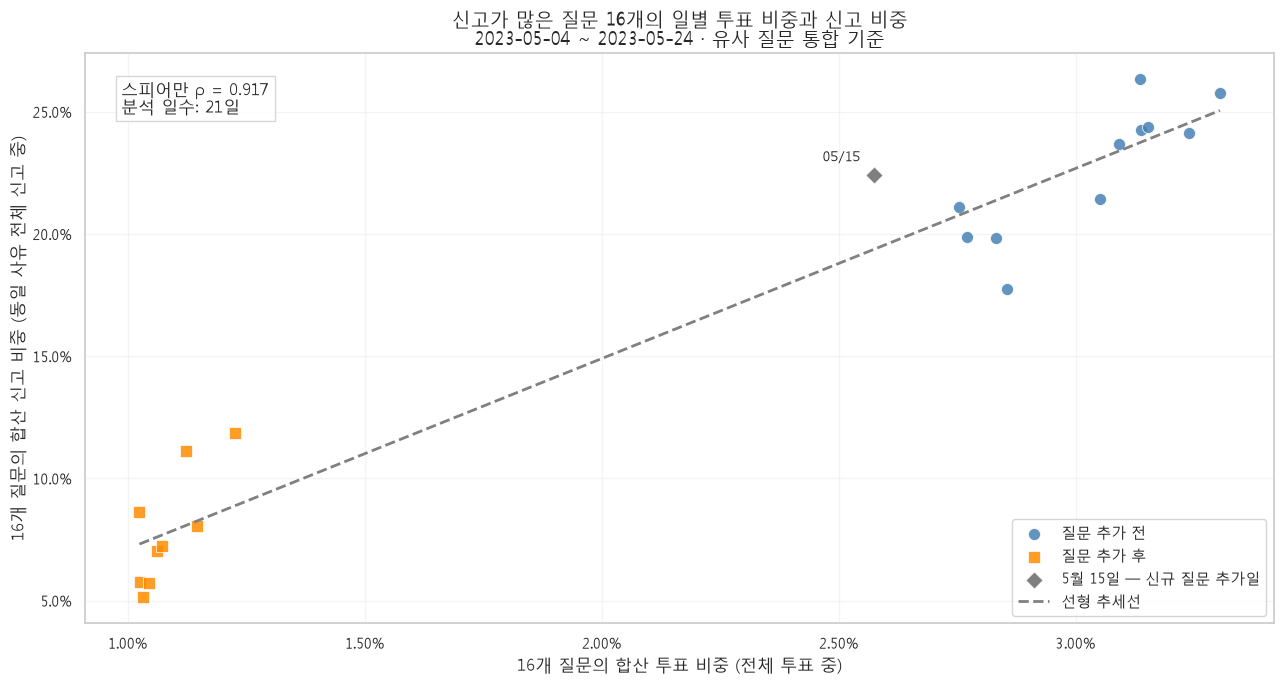

,날짜,16개 질문 합산 투표 수,전체 투표 수,선정 질문 신고 수,전체 신고 수,선정 질문 투표 비중(%),선정 질문 신고 비중(%)
0,2023-05-04,648,22692,19,107,2.856,17.757
1,2023-05-05,1256,41154,30,140,3.052,21.429
2,2023-05-06,1504,47940,98,404,3.137,24.257
3,2023-05-07,1382,44081,208,790,3.135,26.329
4,2023-05-08,1094,33767,211,875,3.240,24.114
5,2023-05-09,899,29078,232,980,3.092,23.673
6,2023-05-10,1013,30658,274,1063,3.304,25.776
7,2023-05-11,1120,35540,277,1137,3.151,24.362
8,2023-05-12,1319,46571,264,1331,2.832,19.835
9,2023-05-13,1772,64365,393,1863,2.753,21.095


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 앞선 집계 셀의 question_ids, target_reasons, reference_date 사용
n_questions = len(question_ids)
addition_date = pd.Timestamp("2023-05-15")

# 1. 공통 제외 조건 적용 후 지정 사유 7개의 신고만 포함
df_scatter_reports = df_questionreport_filtered.loc[
    df_questionreport_filtered["대표 질문 ID"].notna()
    & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons)
].drop_duplicates("id").copy()

df_scatter_reports["날짜"] = pd.to_datetime(
    df_scatter_reports["created_at"]
).dt.normalize()

# 전체 신고 수: clean 전체 질문의 동일 사유 기준
daily_all_reports = (
    df_scatter_reports.groupby("날짜")
    .size()
    .rename("전체 신고 수")
)

# 선정한 16개 질문의 신고 수
daily_selected_reports = (
    df_scatter_reports.loc[
        df_scatter_reports["대표 질문 ID"].isin(question_ids)
    ]
    .groupby("날짜")
    .size()
    .rename("선정 질문 신고 수")
)

# 2. 기존 투표 집계에 신고 수 연결
vote_sum_col = f"{n_questions}개 질문 합산 투표 수"

df_scatter = df_daily_question_average[[
    "날짜",
    vote_sum_col,
    "전체 투표 수",
]].copy()

df_scatter["날짜"] = pd.to_datetime(
    df_scatter["날짜"]
).dt.normalize()

df_scatter = (
    df_scatter
    .merge(
        daily_all_reports,
        left_on="날짜",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
    .merge(
        daily_selected_reports,
        left_on="날짜",
        right_index=True,
        how="left",
        validate="one_to_one",
    )
)

report_columns = ["전체 신고 수", "선정 질문 신고 수"]

df_scatter[report_columns] = (
    df_scatter[report_columns]
    .fillna(0)
    .astype("int64")
)

# 3. 최다 신고일 전후 10일
# 분모가 0인 날은 제외
df_scatter = (
    df_scatter.loc[
        df_scatter["날짜"].between(
            reference_date - pd.Timedelta(days=10),
            reference_date + pd.Timedelta(days=10),
        )
        & df_scatter["전체 투표 수"].gt(0)
        & df_scatter["전체 신고 수"].gt(0)
    ]
    .sort_values("날짜")
    .copy()
)

x_col = "선정 질문 투표 비중(%)"
y_col = "선정 질문 신고 비중(%)"

df_scatter[x_col] = (
    df_scatter[vote_sum_col]
    / df_scatter["전체 투표 수"]
    * 100
)

df_scatter[y_col] = (
    df_scatter["선정 질문 신고 수"]
    / df_scatter["전체 신고 수"]
    * 100
)

if len(df_scatter) < 2:
    raise ValueError("상관관계를 계산할 날짜가 부족합니다.")

# 4. 스피어만 상관계수
# 동점은 평균 순위로 처리
rho = (
    df_scatter[x_col].rank()
    .corr(df_scatter[y_col].rank())
)

# 5. 산점도
fig, ax = plt.subplots(figsize=(13, 7))

groups = [
    (
        df_scatter["날짜"].lt(addition_date),
        "질문 추가 전",
        "steelblue",
        "o",
    ),
    (
        df_scatter["날짜"].gt(addition_date),
        "질문 추가 후",
        "darkorange",
        "s",
    ),
    (
        df_scatter["날짜"].eq(addition_date),
        "5월 15일 — 신규 질문 추가일",
        "dimgray",
        "D",
    ),
]

for mask, label, color, marker in groups:
    subset = df_scatter.loc[mask]

    if subset.empty:
        continue

    ax.scatter(
        subset[x_col],
        subset[y_col],
        color=color,
        marker=marker,
        s=75,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.6,
        label=label,
    )

# 6. 선형 추세선 — 원래 비중 값에 적합
if df_scatter[x_col].nunique() >= 2:
    slope, intercept = np.polyfit(
        df_scatter[x_col],
        df_scatter[y_col],
        deg=1,
    )

    x_line = np.linspace(
        df_scatter[x_col].min(),
        df_scatter[x_col].max(),
        100,
    )

    ax.plot(
        x_line,
        slope * x_line + intercept,
        color="gray",
        linestyle="--",
        linewidth=2,
        label="선형 추세선",
    )

# 신규 질문 추가일 표시
for _, row in df_scatter.loc[
    df_scatter["날짜"].eq(addition_date)
].iterrows():
    ax.annotate(
        "05/15",
        xy=(row[x_col], row[y_col]),
        xytext=(-10, 10),
        textcoords="offset points",
        ha="right",
        fontsize=10,
    )

rho_text = f"{rho:.3f}" if pd.notna(rho) else "계산 불가"

ax.text(
    0.03,
    0.95,
    f"스피어만 ρ = {rho_text}\n"
    f"분석 일수: {len(df_scatter)}일",
    transform=ax.transAxes,
    va="top",
    fontsize=12,
    bbox=dict(
        facecolor="white",
        edgecolor="lightgray",
        alpha=0.9,
    ),
)

ax.set_title(
    f"신고가 많은 질문 {n_questions}개의 "
    "일별 투표 비중과 신고 비중\n"
    f"{df_scatter['날짜'].min():%Y-%m-%d}"
    f" ~ {df_scatter['날짜'].max():%Y-%m-%d}"
    " · 유사 질문 통합 기준",
    fontsize=14,
)

ax.set_xlabel(
    f"{n_questions}개 질문의 합산 투표 비중 (전체 투표 중)"
)
ax.set_ylabel(
    f"{n_questions}개 질문의 합산 신고 비중 "
    "(동일 사유 전체 신고 중)"
)

ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# 산점도에 사용한 일별 데이터
display(
    df_scatter[[
        "날짜",
        vote_sum_col,
        "전체 투표 수",
        "선정 질문 신고 수",
        "전체 신고 수",
        x_col,
        y_col,
    ]].round(3)
)

### 카테고리별 신고율


In [53]:
# 1. 최종 라벨 기준 질문별 데이터
df_category_questions = (
    df_question_reports[[
        "대표 질문 ID",
        "대표 질문명",
        "카테고리",
        "신고 수",
    ]]
    .copy()
)

# 2. 카테고리별 신고 현황
# 신고 없는 질문도 0건으로 평균에 포함
df_category_report_summary = (
    df_category_questions
    .groupby("카테고리")
    .agg(
        전체_질문_수=("대표 질문 ID", "nunique"),
        신고_있는_질문_수=(
            "신고 수", lambda s: s.gt(0).sum()
        ),
        신고_합계=("신고 수", "sum"),
        질문당_평균_신고_건수=("신고 수", "mean"),
    )
    .reset_index()
    .rename(columns={
        "전체_질문_수": "전체 질문 수",
        "신고_있는_질문_수": "신고 있는 질문 수",
        "신고_합계": "신고 합계",
        "질문당_평균_신고_건수": "질문당 평균 신고 건수",
    })
    .sort_values(
        ["질문당 평균 신고 건수", "신고 합계", "카테고리"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

display(df_category_report_summary.round(2))

,카테고리,전체 질문 수,신고 있는 질문 수,신고 합계,질문당 평균 신고 건수
0,체취,21,13,1162,55.33
1,신체 외형,346,260,5137,14.85
2,성격,352,245,4036,11.47
3,재능,336,226,3307,9.84
4,이성적 호감,317,236,3034,9.57
5,매력,225,148,1795,7.98
6,유머,59,46,449,7.61
7,성향,1037,715,7867,7.59
8,칭찬,62,43,432,6.97
9,호감,661,439,4014,6.07


### 카테고리 전체 유저로


In [54]:
import pandas as pd

# 1. 성별 전체 가입자 수
df_gender_registered_users = (
    df_user.loc[
        df_user["gender"].isin(["F", "M"]),
        ["id", "gender"],
    ]
    .drop_duplicates("id")
    .rename(columns={"id": "user_id"})
)

df_gender_registered_users["성별"] = (
    df_gender_registered_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
)

gender_registered_totals = (
    df_gender_registered_users
    .groupby("성별")["user_id"]
    .nunique()
    .rename("성별 전체 가입자 수")
    .reset_index()
)

# 2. 공통 제외 조건 및 지정 사유 적용 후 성별 연결
df_gender_category_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_gender_category_reports["대표 질문 ID"] = pd.to_numeric(
    df_gender_category_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_gender_category_reports = (
    df_gender_category_reports
    .merge(
        df_gender_registered_users[["user_id", "성별"]],
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_question_reports[["대표 질문 ID", "카테고리"]],
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 3. 성별·카테고리별 신고 현황
df_gender_category_summary = (
    df_gender_category_reports
    .groupby(["성별", "카테고리"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
        신고된_질문_수=("대표 질문 ID", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
        "신고된_질문_수": "신고된 질문 수",
    })
    .merge(
        gender_registered_totals,
        on="성별",
        how="left",
        validate="many_to_one",
    )
)

df_gender_category_summary["성별 전체 가입자 중 신고자 비율(%)"] = (
    df_gender_category_summary["고유 신고자 수"]
    / df_gender_category_summary["성별 전체 가입자 수"]
    * 100
)

# 4. 여학생 → 남학생 순서로 출력
for gender in ["여학생", "남학생"]:
    gender_category_result = (
        df_gender_category_summary.loc[
            df_gender_category_summary["성별"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "고유 신고자 수", "카테고리"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender}] 카테고리별 신고 현황")

    display(
        gender_category_result[[
            "카테고리",
            "성별 전체 가입자 수",
            "신고 수",
            "고유 신고자 수",
            "신고된 질문 수",
            "성별 전체 가입자 중 신고자 비율(%)",
        ]].round(3)
    )


[여학생] 카테고리별 신고 현황


,카테고리,성별 전체 가입자 수,신고 수,고유 신고자 수,신고된 질문 수,성별 전체 가입자 중 신고자 비율(%)
0,성향,396665,5788,2518,659,0.635
1,신체 외형,396665,3815,2183,238,0.550
2,성격,396665,2915,1480,233,0.373
3,호감,396665,2649,1253,393,0.316
4,재능,396665,2449,1331,216,0.336
5,이성적 호감,396665,1806,1127,215,0.284
6,매력,396665,1208,743,137,0.187
7,체취,396665,782,596,13,0.150
8,가정,396665,777,489,129,0.123
9,관계,396665,395,275,63,0.069



[남학생] 카테고리별 신고 현황


,카테고리,성별 전체 가입자 수,신고 수,고유 신고자 수,신고된 질문 수,성별 전체 가입자 중 신고자 비율(%)
0,성향,280416,2079,1149,417,0.410
1,호감,280416,1365,751,326,0.268
2,신체 외형,280416,1322,829,190,0.296
3,이성적 호감,280416,1228,826,178,0.295
4,성격,280416,1121,682,169,0.243
5,재능,280416,858,553,157,0.197
6,매력,280416,587,410,97,0.146
7,체취,280416,380,284,13,0.101
8,가정,280416,350,259,96,0.092
9,관계,280416,193,152,47,0.054


### 질문 신고 순위


In [55]:
import pandas as pd

target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]

# 1. 앞선 셀에서 정리한 질문명·최종 카테고리
df_top20_labels = (
    df_question_reports[[
        "대표 질문 ID",
        "대표 질문명",
        "카테고리",
    ]]
    .copy()
)

# 2. 공통 제외 조건 및 지정 사유 적용 후 신고자 성별 연결
df_gender_top20_source = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["대표 질문 ID"].notna()
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_gender_top20_source["대표 질문 ID"] = pd.to_numeric(
    df_gender_top20_source["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_gender_top20_source = (
    df_gender_top20_source
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
)

print(
    "신고자 성별 확인 불가:",
    f"{(~df_gender_top20_source['gender'].isin(['F', 'M'])).sum():,}건",
)

# 3. 성별·질문별 신고 건수
df_gender_question_counts = (
    df_gender_top20_source.loc[
        df_gender_top20_source["gender"].isin(["F", "M"])
    ]
    .groupby(["gender", "대표 질문 ID"])
    .agg(
        신고_수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
)

# 결과 보관
gender_top20_questions = {}
gender_top20_category_distribution = {}

# 4. 성별 Top 20 및 최종 카테고리 분포
for gender, label in [("F", "여학생"), ("M", "남학생")]:
    top20 = (
        df_gender_question_counts.loc[
            df_gender_question_counts["gender"].eq(gender)
        ]
        .sort_values(
            ["신고 수", "대표 질문 ID"],
            ascending=[False, True],
        )
        .head(20)
        .merge(
            df_top20_labels,
            on="대표 질문 ID",
            how="left",
            validate="one_to_one",
            indicator=True,
        )
        .reset_index(drop=True)
    )

    top20.insert(0, "순위", range(1, len(top20) + 1))
    total_questions = len(top20)

    # CSV 연결 실패와 CSV 내 미분류 구분
    top20.loc[
        top20["_merge"].eq("left_only"),
        "카테고리",
    ] = "라벨 연결 불가"

    distribution = (
        top20
        .groupby("카테고리")["대표 질문 ID"]
        .nunique()
        .reset_index(name="질문 수")
    )

    distribution["Top 20 내 비율(%)"] = (
        distribution["질문 수"] / total_questions * 100
        if total_questions else float("nan")
    )

    distribution = (
        distribution
        .sort_values(
            ["질문 수", "카테고리"],
            ascending=[False, True],
        )
        .reset_index(drop=True)
    )

    gender_top20_questions[label] = (
        top20.drop(columns="_merge").copy()
    )
    gender_top20_category_distribution[label] = distribution.copy()

    print(f"\n[{label}] 신고 질문 Top {total_questions}")
    display(top20[[
        "순위",
        "대표 질문 ID",
        "대표 질문명",
        "카테고리",
        "신고 수",
        "고유 신고자 수",
    ]])

    print(f"[{label}] Top {total_questions} 질문의 카테고리 분포")
    display(distribution.round(2))

신고자 성별 확인 불가: 0건

[여학생] 신고 질문 Top 20


,순위,대표 질문 ID,대표 질문명,카테고리,신고 수,고유 신고자 수
0,1,111,마스크가 잘 어울리는 사람은?,신체 외형,434,330
1,2,398,등빨이 가장 좋은 사람은?,신체 외형,430,354
2,3,410,발냄새가 호두과자 냄새일 것 같은 사람은?,체취,347,291
3,4,424,어깨가 가장 넓은 사람은?,신체 외형,321,266
4,5,305,먹방을 가장 잘할 것 같은 사람은?,재능,257,209
5,6,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,신체 외형,163,131
6,7,564,설레면 콧구멍이 커지는 친구는?,신체 외형,159,144
7,8,479,치킨 중독인 것 같은 사람은?,성향,153,125
8,9,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,재능,142,110
9,10,201,화장을 제일 잘하는 사람?,신체 외형,131,78


[여학생] Top 20 질문의 카테고리 분포


,카테고리,질문 수,Top 20 내 비율(%)
0,신체 외형,6,30.0
1,성향,4,20.0
2,체취,3,15.0
3,매력,2,10.0
4,성격,2,10.0
5,재능,2,10.0
6,이성적 호감,1,5.0



[남학생] 신고 질문 Top 20


,순위,대표 질문 ID,대표 질문명,카테고리,신고 수,고유 신고자 수
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,체취,199,162
1,2,111,마스크가 잘 어울리는 사람은?,신체 외형,140,90
2,3,460,농부가 될 가능성이 가장 높은 사람은?,성향,66,49
3,4,516,매일 공유킥보드 타고 다니는 친구는?,성향,65,50
4,5,465,어부가 될 가능성이 가장 높은 사람은?,성향,63,55
5,6,476,거의 움직이지 않는 친구는?,성향,63,44
6,7,144,발냄새가 가장 향긋할 것 같은 사람은?,체취,62,49
7,8,564,설레면 콧구멍이 커지는 친구는?,신체 외형,58,48
8,9,305,먹방을 가장 잘할 것 같은 사람은?,재능,51,38
9,10,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,신체 외형,50,46


[남학생] Top 20 질문의 카테고리 분포


,카테고리,질문 수,Top 20 내 비율(%)
0,성향,6,30.0
1,신체 외형,4,20.0
2,재능,3,15.0
3,체취,3,15.0
4,이성적 호감,2,10.0
5,매력,1,5.0
6,성격,1,5.0


### 카테고리별 성별


In [56]:
import pandas as pd

# 1. 최종 카테고리별 질문 수
category_question_counts = (
    df_question_reports
    .groupby("카테고리")["대표 질문 ID"]
    .nunique()
    .rename("전체 질문")
)

# 2. 공통 제외 조건 및 지정 사유 적용
df_category_gender_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_category_gender_reports["대표 질문 ID"] = pd.to_numeric(
    df_category_gender_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_category_gender_reports = (
    df_category_gender_reports
    .merge(
        df_user[["id", "gender"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question_reports[["대표 질문 ID", "카테고리"]],
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 3. 카테고리별 여성·남성 신고 건수
category_gender_counts = (
    df_category_gender_reports.loc[
        df_category_gender_reports["gender"].isin(["F", "M"])
    ]
    .groupby(["카테고리", "gender"])["id"]
    .nunique()
    .unstack("gender", fill_value=0)
    .reindex(columns=["F", "M"], fill_value=0)
    .rename(columns={
        "F": "여성 신고 횟수",
        "M": "남성 신고 횟수",
    })
    .rename_axis(columns=None)
)

result = (
    category_question_counts
    .to_frame()
    .join(category_gender_counts, how="left")
)

count_columns = ["여성 신고 횟수", "남성 신고 횟수"]

result[count_columns] = (
    result[count_columns]
    .fillna(0)
    .astype(int)
)

# 4. 여성·남성 신고 건수의 구성비
gender_report_total = (
    result["여성 신고 횟수"]
    + result["남성 신고 횟수"]
)

for gender_label in ["여성", "남성"]:
    result[f"{gender_label} 신고 비율(%)"] = (
        result[f"{gender_label} 신고 횟수"]
        .div(gender_report_total.where(gender_report_total.gt(0)))
        .mul(100)
    )

# 남녀 합산 신고 건수 내림차순
result = (
    result
    .assign(정렬용_신고_합계=gender_report_total)
    .reset_index()
    .sort_values(
        ["정렬용_신고_합계", "카테고리"],
        ascending=[False, True],
    )
    .drop(columns="정렬용_신고_합계")
    .reset_index(drop=True)
)

df_category_gender_report_summary = result.copy()

display(
    result[[
        "카테고리",
        "전체 질문",
        "여성 신고 횟수",
        "남성 신고 횟수",
        "여성 신고 비율(%)",
        "남성 신고 비율(%)",
    ]].round(2)
)

,카테고리,전체 질문,여성 신고 횟수,남성 신고 횟수,여성 신고 비율(%),남성 신고 비율(%)
0,성향,1037,5788,2079,73.57,26.43
1,신체 외형,346,3815,1322,74.27,25.73
2,성격,352,2915,1121,72.22,27.78
3,호감,661,2649,1365,65.99,34.01
4,재능,336,2449,858,74.06,25.94
5,이성적 호감,317,1806,1228,59.53,40.47
6,매력,225,1208,587,67.30,32.70
7,체취,21,782,380,67.30,32.70
8,가정,204,777,350,68.94,31.06
9,관계,104,395,193,67.18,32.82


### 전체에서 노출 대비 신고율의 4분위


In [57]:
import pandas as pd

quartile_mapper = QuestionIdMapper()

# 1. 분석 대상 유저 — 남녀 합산, 공통 제외 조건 유지
quartile_user_ids = df_user.loc[
    df_user["gender"].isin(["F", "M"])
    & ~df_user["id"].isin(excluded_reporter_ids),
    "id",
]

# 2. 전체 질문별 투표 건수
df_quartile_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(quartile_user_ids),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_quartile_votes["대표 질문 ID"] = quartile_mapper.transform(
    df_quartile_votes["question_id"]
)

quartile_vote_counts = (
    df_quartile_votes
    .dropna(subset=["대표 질문 ID"])
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("투표 건수")
)

# 3. 전체 유저의 지정 사유 7개 신고
df_quartile_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(quartile_user_ids)
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_quartile_reports["대표 질문 ID"] = pd.to_numeric(
    df_quartile_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

quartile_report_counts = (
    df_quartile_reports
    .groupby("대표 질문 ID")["id"]
    .nunique()
    .rename("신고 건수")
)

# 4. 투표가 있는 질문 전체에 신고 건수 연결
df_question_report_rate_quartiles = (
    quartile_vote_counts
    .to_frame()
    .join(quartile_report_counts, how="left")
    .fillna({"신고 건수": 0})
    .reset_index()
)

df_question_report_rate_quartiles["신고 건수"] = (
    df_question_report_rate_quartiles["신고 건수"].astype(int)
)

df_question_report_rate_quartiles["투표 대비 신고 비율(%)"] = (
    df_question_report_rate_quartiles["신고 건수"]
    / df_question_report_rate_quartiles["투표 건수"]
    * 100
)

# 5. 질문별 비율의 사분위수
df_report_rate_quartile_summary = (
    df_question_report_rate_quartiles["투표 대비 신고 비율(%)"]
    .quantile([0.25, 0.50, 0.75])
    .rename_axis("분위")
    .reset_index(name="투표 대비 신고 비율(%)")
)

df_report_rate_quartile_summary["분위"] = [
    "Q1 — 하위 25% 경계",
    "Q2 — 중앙값",
    "Q3 — 하위 75% 경계",
]

print(f"분석 질문 수: {len(df_question_report_rate_quartiles):,}개")
print(
    "신고 0건 질문 수:",
    f"{df_question_report_rate_quartiles['신고 건수'].eq(0).sum():,}개",
)

display(df_report_rate_quartile_summary.round(4))

분석 질문 수: 3,778개
신고 0건 질문 수: 1,160개


,분위,투표 대비 신고 비율(%)
0,Q1 — 하위 25% 경계,0.0000
1,Q2 — 중앙값,2.3102
2,Q3 — 하위 75% 경계,4.7619


### 가설 검증1. 여학생의 체취 카테고리 신고 건수 Top 10


In [58]:
import pandas as pd

# 1. 최종 라벨링에서 체취 질문 선정
df_female_odor_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "대표 질문명", "라벨링"]]
    .copy()
)

df_female_odor_labels["대표 질문 ID"] = pd.to_numeric(
    df_female_odor_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_female_odor_labels["대표 질문 ID"].isna().any()
    or df_female_odor_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_female_odor_labels = (
    df_female_odor_labels.loc[
        df_female_odor_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("체취"),
        ["대표 질문 ID", "대표 질문명"],
    ]
    .copy()
)

# 2. 여학생 신고자 ID
female_odor_user_ids = df_user.loc[
    df_user["gender"].eq("F"),
    "id",
]

# 3. 여학생의 지정 사유 신고
df_female_odor_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            female_odor_user_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_female_odor_reports["대표 질문 ID"] = pd.to_numeric(
    df_female_odor_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

# 4. 체취 질문 연결 후 신고 건수 순위
df_female_odor_top10 = (
    df_female_odor_reports
    .merge(
        df_female_odor_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
    .groupby(
        ["대표 질문 ID", "대표 질문명"],
        dropna=False,
    )
    .agg(
        신고_건수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_건수": "여학생 신고 건수",
        "고유_신고자_수": "고유 여학생 신고자 수",
    })
    .sort_values(
        ["여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_female_odor_top10.insert(
    0, "순위", range(1, len(df_female_odor_top10) + 1)
)

display(df_female_odor_top10)

,순위,대표 질문 ID,대표 질문명,여학생 신고 건수,고유 여학생 신고자 수
0,1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,347,291
1,2,144,발냄새가 가장 향긋할 것 같은 사람은?,130,116
2,3,416,발가락에서 페브리즈향이 날 것 같은 사람은?,110,88
3,4,362,땀냄새가 가장 좋을 것 같은 사람은?,92,81
4,5,1281,발에서 향기날것 같은 사람,31,28
5,6,409,향기가 좋은 사람은?,23,21
6,7,1532,이 사람의 발냄새 만큼은 용서 된다,20,18
7,8,209,항상 좋은 냄새가 나는 사람은?,13,13
8,9,1598,가장 샴푸향기가 좋을 것 같은 사람은?,6,6
9,10,2512,복숭아 향이 잘 어울리는 친구는?,3,3


In [59]:
import pandas as pd

odor_check_mapper = QuestionIdMapper()

# 검증용 제외 질문
odor_check_remove_ids = set(
    odor_check_mapper.transform(
        pd.Series([410, 144, 416, 362, 1281])
    )
    .dropna()
    .astype(int)
)

# 1. 최종 라벨링의 체취 질문
df_odor_check_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "라벨링"]]
    .copy()
)

df_odor_check_labels["대표 질문 ID"] = pd.to_numeric(
    df_odor_check_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_odor_check_labels["대표 질문 ID"].isna().any()
    or df_odor_check_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

odor_check_category_ids = set(
    df_odor_check_labels.loc[
        df_odor_check_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("체취"),
        "대표 질문 ID",
    ]
)

odor_check_remaining_ids = (
    odor_check_category_ids - odor_check_remove_ids
)

# 2. 여학생 — 공통 유저 제외 조건 유지
odor_check_female_ids = set(
    df_user.loc[
        df_user["gender"].eq("F")
        & ~df_user["id"].isin(excluded_reporter_ids),
        "id",
    ]
)

# 3. 여학생의 체취 신고
df_odor_check_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            odor_check_female_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_odor_check_reports["대표 질문 ID"] = pd.to_numeric(
    df_odor_check_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

# 4. 여학생이 직접 투표한 기록
df_odor_check_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(
            odor_check_female_ids
        ),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_odor_check_votes["대표 질문 ID"] = (
    odor_check_mapper.transform(
        df_odor_check_votes["question_id"]
    )
)

# 5. 제외 전후 비교
odor_check_rows = []

for label, question_ids in [
    ("제외 전", odor_check_category_ids),
    ("5개 질문 제외 후", odor_check_remaining_ids),
]:
    report_source = df_odor_check_reports.loc[
        df_odor_check_reports["대표 질문 ID"].isin(question_ids)
    ]

    vote_source = df_odor_check_votes.loc[
        df_odor_check_votes["대표 질문 ID"].isin(question_ids)
    ]

    report_count = report_source["id"].nunique()
    vote_count = vote_source["id"].nunique()

    odor_check_rows.append({
        "구분": label,
        "체취 질문 수": len(question_ids),
        "여학생 신고 건수": report_count,
        "여학생 투표 건수": vote_count,
        "투표 대비 신고 비율(%)": (
            report_count / vote_count * 100
            if vote_count else float("nan")
        ),
    })

df_odor_removal_check = pd.DataFrame(odor_check_rows)

print(
    "체취 카테고리에서 제외되는 대표 질문 ID:",
    sorted(odor_check_category_ids & odor_check_remove_ids),
)

display(df_odor_removal_check.round(3))

체취 카테고리에서 제외되는 대표 질문 ID: [144, 362, 410, 416, 1281]


,구분,체취 질문 수,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,제외 전,21,782,4591,17.033
1,5개 질문 제외 후,16,72,1802,3.996


In [60]:
import pandas as pd

# 1. 최종 라벨링에서 신체 외형 질문 선정
df_female_appearance_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "대표 질문명", "라벨링"]]
    .copy()
)

df_female_appearance_labels["대표 질문 ID"] = pd.to_numeric(
    df_female_appearance_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_female_appearance_labels["대표 질문 ID"].isna().any()
    or df_female_appearance_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

df_female_appearance_labels = (
    df_female_appearance_labels.loc[
        df_female_appearance_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("신체 외형"),
        ["대표 질문 ID", "대표 질문명"],
    ]
    .copy()
)

# 2. 여학생 — 공통 유저 제외 조건 유지
female_appearance_user_ids = df_user.loc[
    df_user["gender"].eq("F")
    & ~df_user["id"].isin(excluded_reporter_ids),
    "id",
]

# 3. 지정 사유 신고
df_female_appearance_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            female_appearance_user_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_female_appearance_reports["대표 질문 ID"] = pd.to_numeric(
    df_female_appearance_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

# 4. 신체 외형 질문 신고 Top 10
df_female_appearance_top10 = (
    df_female_appearance_reports
    .merge(
        df_female_appearance_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
    .groupby(
        ["대표 질문 ID", "대표 질문명"],
        dropna=False,
    )
    .agg(
        신고_건수=("id", "nunique"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "신고_건수": "여학생 신고 건수",
        "고유_신고자_수": "고유 여학생 신고자 수",
    })
    .sort_values(
        ["여학생 신고 건수", "대표 질문 ID"],
        ascending=[False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_female_appearance_top10.insert(
    0, "순위", range(1, len(df_female_appearance_top10) + 1)
)

display(df_female_appearance_top10)

,순위,대표 질문 ID,대표 질문명,여학생 신고 건수,고유 여학생 신고자 수
0,1,111,마스크가 잘 어울리는 사람은?,434,330
1,2,398,등빨이 가장 좋은 사람은?,430,354
2,3,424,어깨가 가장 넓은 사람은?,321,266
3,4,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,163,131
4,5,564,설레면 콧구멍이 커지는 친구는?,159,144
5,6,201,화장을 제일 잘하는 사람?,131,78
6,7,190,팔씨름을 제일 잘할것 같은 사람은?,96,81
7,8,470,발가락이 귀여울 것 같은 친구는?,83,77
8,9,548,가장 몸이 좋은 사람은?,82,72
9,10,384,입술 색깔이 가장 빨간 사람은?,58,43


In [61]:
import pandas as pd

appearance_check_mapper = QuestionIdMapper()

# 검증용 제외 질문
appearance_check_remove_ids = set(
    appearance_check_mapper.transform(
        pd.Series([111, 398, 424, 519, 564])
    )
    .dropna()
    .astype(int)
)

# 1. 최종 라벨링의 신체 외형 질문
df_appearance_check_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "라벨링"]]
    .copy()
)

df_appearance_check_labels["대표 질문 ID"] = pd.to_numeric(
    df_appearance_check_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    df_appearance_check_labels["대표 질문 ID"].isna().any()
    or df_appearance_check_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

appearance_check_category_ids = set(
    df_appearance_check_labels.loc[
        df_appearance_check_labels["라벨링"]
        .astype("string")
        .str.strip()
        .eq("신체 외형"),
        "대표 질문 ID",
    ]
)

appearance_check_remaining_ids = (
    appearance_check_category_ids - appearance_check_remove_ids
)

# 2. 여학생 — 공통 유저 제외 조건 유지
appearance_check_female_ids = set(
    df_user.loc[
        df_user["gender"].eq("F")
        & ~df_user["id"].isin(excluded_reporter_ids),
        "id",
    ]
)

# 3. 지정 사유 7개 신고
df_appearance_check_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["user_id"].isin(
            appearance_check_female_ids
        )
        & df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_appearance_check_reports["대표 질문 ID"] = pd.to_numeric(
    df_appearance_check_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

# 4. 여학생의 직접 투표 기록
df_appearance_check_votes = (
    df_userquestionrecord.loc[
        df_userquestionrecord["user_id"].isin(
            appearance_check_female_ids
        ),
        ["id", "question_id"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_appearance_check_votes["대표 질문 ID"] = (
    appearance_check_mapper.transform(
        df_appearance_check_votes["question_id"]
    )
)

# 5. 제외 전후 비교
appearance_check_rows = []

for label, question_ids in [
    ("제외 전", appearance_check_category_ids),
    ("5개 질문 제외 후", appearance_check_remaining_ids),
]:
    report_count = (
        df_appearance_check_reports.loc[
            df_appearance_check_reports["대표 질문 ID"].isin(
                question_ids
            ),
            "id",
        ]
        .nunique()
    )

    vote_count = (
        df_appearance_check_votes.loc[
            df_appearance_check_votes["대표 질문 ID"].isin(
                question_ids
            ),
            "id",
        ]
        .nunique()
    )

    appearance_check_rows.append({
        "구분": label,
        "신체 외형 질문 수": len(question_ids),
        "여학생 신고 건수": report_count,
        "여학생 투표 건수": vote_count,
        "투표 대비 신고 비율(%)": (
            report_count / vote_count * 100
            if vote_count else float("nan")
        ),
    })

df_appearance_removal_check = pd.DataFrame(
    appearance_check_rows
)

print(
    "신체 외형 카테고리에서 제외되는 대표 질문 ID:",
    sorted(
        appearance_check_category_ids
        & appearance_check_remove_ids
    ),
)

display(df_appearance_removal_check.round(3))

신체 외형 카테고리에서 제외되는 대표 질문 ID: [111, 398, 424, 519, 564]


,구분,신체 외형 질문 수,여학생 신고 건수,여학생 투표 건수,투표 대비 신고 비율(%)
0,제외 전,346,3815,61495,6.204
1,5개 질문 제외 후,341,2308,58607,3.938


### 노출 대비 신고 지수


In [62]:
import pandas as pd

share_index_mapper = QuestionIdMapper()

# 1. 최종 카테고리
df_share_index_labels = (
    df_question_reports[["대표 질문 ID", "카테고리"]]
    .copy()
)

df_share_index_users = (
    df_user.loc[
        df_user["gender"].isin(["F", "M"]),
        ["id", "gender"],
    ]
    .rename(columns={"id": "user_id"})
    .copy()
)

# 2. 투표 기록에 카테고리·투표자 성별 연결
df_share_index_votes = (
    df_userquestionrecord[["id", "user_id", "question_id"]]
    .drop_duplicates("id")
    .copy()
)

df_share_index_votes["대표 질문 ID"] = (
    share_index_mapper.transform(
        df_share_index_votes["question_id"]
    )
)

df_share_index_votes = (
    df_share_index_votes.loc[
        ~df_share_index_votes["user_id"].isin(excluded_reporter_ids)
    ]
    .merge(
        df_share_index_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_share_index_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 같은 유저 범위로 신고 제한
share_index_voter_ids = df_share_index_votes["user_id"].unique()

# 3. 전체 유저의 지정 사유 신고
# 투표 이력이 있는 유저로 제한하지 않음
df_share_index_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(target_reasons),
        ["id", "user_id", "대표 질문 ID"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_share_index_reports["대표 질문 ID"] = pd.to_numeric(
    df_share_index_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_share_index_reports = (
    df_share_index_reports
    .merge(
        df_share_index_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_share_index_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 4. 성별·카테고리별 건수
share_index_vote_counts = (
    df_share_index_votes
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("투표 건수")
)

share_index_report_counts = (
    df_share_index_reports
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("신고 건수")
)

df_category_share_index = (
    pd.concat(
        [share_index_vote_counts, share_index_report_counts],
        axis=1,
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)

# 5. 성별 내 점유율
for count_column, share_column in [
    ("신고 건수", "신고 점유율(%)"),
    ("투표 건수", "투표 점유율(%)"),
]:
    gender_total = (
        df_category_share_index
        .groupby("gender")[count_column]
        .transform("sum")
    )

    df_category_share_index[share_column] = (
        df_category_share_index[count_column]
        .div(gender_total.where(gender_total.gt(0)))
        .mul(100)
    )

df_category_share_index["신고·투표 점유율 지수"] = (
    df_category_share_index["신고 점유율(%)"]
    .div(
        df_category_share_index["투표 점유율(%)"].where(
            df_category_share_index["투표 점유율(%)"].gt(0)
        )
    )
)

# 6. 성별 결과
for gender_code, gender_label in [
    ("F", "여학생"),
    ("M", "남학생"),
]:
    share_index_result = (
        df_category_share_index.loc[
            df_category_share_index["gender"].eq(gender_code)
        ]
        .sort_values(
            ["신고·투표 점유율 지수", "신고 건수"],
            ascending=[False, False],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    print(f"\n[{gender_label}] 카테고리별 신고·투표 점유율 비교")

    display(
        share_index_result[[
            "카테고리",
            "신고 건수",
            "투표 건수",
            "신고 점유율(%)",
            "투표 점유율(%)",
            "신고·투표 점유율 지수",
        ]].round(3)
    )


[여학생] 카테고리별 신고·투표 점유율 비교


,카테고리,신고 건수,투표 건수,신고 점유율(%),투표 점유율(%),신고·투표 점유율 지수
0,체취,782,4591,3.344,0.775,4.313
1,신체 외형,3815,61495,16.312,10.385,1.571
2,유머,331,5410,1.415,0.914,1.549
3,성향,5788,122957,24.748,20.765,1.192
4,이성적 호감,1806,43940,7.722,7.420,1.041
5,재능,2449,65847,10.471,11.120,0.942
6,성격,2915,81476,12.464,13.759,0.906
7,매력,1208,43216,5.165,7.298,0.708
8,가정,777,28322,3.322,4.783,0.695
9,관계,395,14429,1.689,2.437,0.693



[남학생] 카테고리별 신고·투표 점유율 비교


,카테고리,신고 건수,투표 건수,신고 점유율(%),투표 점유율(%),신고·투표 점유율 지수
0,체취,380,3867,3.875,0.767,5.051
1,이성적 호감,1228,38038,12.522,7.545,1.660
2,유머,118,4662,1.203,0.925,1.301
3,신체 외형,1322,52730,13.480,10.460,1.289
4,성향,2079,106488,21.199,21.123,1.004
5,호감,1365,82605,13.919,16.386,0.849
6,성격,1121,68789,11.431,13.645,0.838
7,매력,587,36827,5.986,7.305,0.819
8,재능,858,56421,8.749,11.192,0.782
9,관계,193,12727,1.968,2.525,0.780


### Lift


In [63]:
import pandas as pd

report_lift_mapper = QuestionIdMapper()

# 1. 최종 카테고리
df_report_lift_labels = (
    df_question_reports[["대표 질문 ID", "카테고리"]]
    .copy()
)

# 투표·지목 이력과 관계없이 전체 일반 유저
# 공통 유저 제외 조건은 유지
df_report_lift_users = (
    df_user.loc[
        ~df_user["id"].isin(excluded_reporter_ids)
        & df_user["gender"].isin(["F", "M"]),
        ["id", "gender"],
    ]
    .rename(columns={"id": "user_id"})
    .copy()
)

# 2. 투표 기록 — 투표자 성별 기준
df_report_lift_votes = (
    df_userquestionrecord[["id", "user_id", "question_id"]]
    .drop_duplicates("id")
    .copy()
)

df_report_lift_votes["대표 질문 ID"] = (
    report_lift_mapper.transform(
        df_report_lift_votes["question_id"]
    )
)

df_report_lift_votes = (
    df_report_lift_votes
    .merge(
        df_report_lift_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_report_lift_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 3. 전체 사유 신고
# 사유 필터를 적용하지 않음
df_report_lift_reports = (
    df_questionreport_filtered[
        ["id", "user_id", "대표 질문 ID", "reason"]
    ]
    .drop_duplicates("id")
    .copy()
)

df_report_lift_reports["대표 질문 ID"] = pd.to_numeric(
    df_report_lift_reports["대표 질문 ID"],
    errors="raise",
).astype("Int64")

df_report_lift_reports = (
    df_report_lift_reports
    .merge(
        df_report_lift_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .merge(
        df_report_lift_labels,
        on="대표 질문 ID",
        how="inner",
        validate="many_to_one",
    )
)

# 선정 사유: 앞서 정의한 target_reasons 7개
df_report_lift_reports["선정 사유 여부"] = (
    df_report_lift_reports["reason"]
    .astype("string")
    .str.strip()
    .isin(target_reasons)
)

# 4. 성별·카테고리별 건수
report_lift_vote_counts = (
    df_report_lift_votes
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("투표 건수")
)

report_lift_all_counts = (
    df_report_lift_reports
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("전체 신고 건수")
)

report_lift_selected_counts = (
    df_report_lift_reports.loc[
        df_report_lift_reports["선정 사유 여부"]
    ]
    .groupby(["gender", "카테고리"])["id"]
    .nunique()
    .rename("선정 사유 신고 건수")
)

df_report_lift_summary = (
    pd.concat(
        [
            report_lift_vote_counts,
            report_lift_all_counts,
            report_lift_selected_counts,
        ],
        axis=1,
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)

# 5. 투표 점유율
report_lift_vote_totals = (
    df_report_lift_summary
    .groupby("gender")["투표 건수"]
    .transform("sum")
)

df_report_lift_summary["투표 점유율(%)"] = (
    df_report_lift_summary["투표 건수"]
    .div(
        report_lift_vote_totals.where(
            report_lift_vote_totals.gt(0)
        )
    )
    .mul(100)
)

# 전체 신고와 선정 사유 신고의 점유율·지수 각각 계산
for count_column, share_column, lift_column in [
    (
        "전체 신고 건수",
        "전체 신고 점유율(%)",
        "전체 신고 지수",
    ),
    (
        "선정 사유 신고 건수",
        "선정 사유 신고 점유율(%)",
        "선정 사유 신고 지수",
    ),
]:
    report_totals = (
        df_report_lift_summary
        .groupby("gender")[count_column]
        .transform("sum")
    )

    df_report_lift_summary[share_column] = (
        df_report_lift_summary[count_column]
        .div(report_totals.where(report_totals.gt(0)))
        .mul(100)
    )

    df_report_lift_summary[lift_column] = (
        df_report_lift_summary[share_column]
        .div(
            df_report_lift_summary["투표 점유율(%)"].where(
                df_report_lift_summary["투표 점유율(%)"].gt(0)
            )
        )
    )

# 6. 여학생 → 남학생 순서로 출력
for gender_code, gender_label in [
    ("F", "여학생"),
    ("M", "남학생"),
]:
    report_lift_result = (
        df_report_lift_summary.loc[
            df_report_lift_summary["gender"].eq(gender_code)
        ]
        .sort_values(
            ["전체 신고 지수", "전체 신고 건수"],
            ascending=[False, False],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    print(
        f"\n[{gender_label}] "
        f"투표 {report_lift_result['투표 건수'].sum():,}건 / "
        f"전체 신고 {report_lift_result['전체 신고 건수'].sum():,}건 / "
        f"선정 사유 신고 "
        f"{report_lift_result['선정 사유 신고 건수'].sum():,}건"
    )

    display(
        report_lift_result[[
            "카테고리",
            "투표 건수",
            "전체 신고 건수",
            "전체 신고 지수",
            "선정 사유 신고 건수",
            "선정 사유 신고 지수",
        ]].round(3)
    )


[여학생] 투표 592,144건 / 전체 신고 26,854건 / 선정 사유 신고 23,388건


,카테고리,투표 건수,전체 신고 건수,전체 신고 지수,선정 사유 신고 건수,선정 사유 신고 지수
0,체취,4591,835,4.010,782,4.313
1,신체 외형,61495,4243,1.521,3815,1.571
2,유머,5410,367,1.496,331,1.549
3,성향,122957,6590,1.182,5788,1.192
4,이성적 호감,43940,2049,1.028,1806,1.041
5,재능,65847,2809,0.941,2449,0.942
6,성격,81476,3376,0.914,2915,0.906
7,관계,14429,482,0.737,395,0.693
8,매력,43216,1418,0.724,1208,0.708
9,금전,6322,205,0.715,173,0.693



[남학생] 투표 504,131건 / 전체 신고 11,574건 / 선정 사유 신고 9,807건


,카테고리,투표 건수,전체 신고 건수,전체 신고 지수,선정 사유 신고 건수,선정 사유 신고 지수
0,체취,3867,414,4.663,380,5.051
1,이성적 호감,38038,1393,1.595,1228,1.660
2,유머,4662,139,1.299,118,1.301
3,신체 외형,52730,1552,1.282,1322,1.289
4,성향,106488,2430,0.994,2079,1.004
5,호감,82605,1644,0.867,1365,0.849
6,성격,68789,1317,0.834,1121,0.838
7,매력,36827,703,0.831,587,0.819
8,관계,12727,242,0.828,193,0.780
9,재능,56421,1040,0.803,858,0.782


## (폐기) 리텐션 정의


In [64]:
import pandas as pd

sequence_mapper = QuestionIdMapper()

# 지목·신고 대상 기간: 6월 29일까지
sequence_cutoff = pd.Timestamp("2023-06-30")  # 미포함


# =========================================================
# 1. 직접 투표 기록 및 유저별 최초 투표 시각
# =========================================================
df_sequence_votes = (
    df_userquestionrecord[
        ["id", "user_id", "chosen_user_id", "question_id", "created_at"]
    ]
    .drop_duplicates("id")
    .copy()
)

df_sequence_votes["투표 시각"] = pd.to_datetime(
    df_sequence_votes["created_at"],
    errors="raise",
)

df_sequence_votes["대표 질문 ID"] = sequence_mapper.transform(
    df_sequence_votes["question_id"]
)

df_sequence_first_votes = (
    df_sequence_votes
    .dropna(subset=["user_id"])
    .groupby("user_id")["투표 시각"]
    .min()
    .reset_index(name="최초 직접 투표 시각")
)


# =========================================================
# 2. 지목받은 기록
# =========================================================
df_sequence_received = (
    df_sequence_votes.loc[
        df_sequence_votes["chosen_user_id"].notna()
        & df_sequence_votes["대표 질문 ID"].notna()
        & df_sequence_votes["투표 시각"].lt(sequence_cutoff),
        ["id", "chosen_user_id", "대표 질문 ID", "투표 시각"],
    ]
    .rename(columns={
        "chosen_user_id": "user_id",
        "투표 시각": "지목 시각",
    })
    .copy()
)

# 유저·대표 질문별 최초 지목
df_sequence_first_received = (
    df_sequence_received
    .groupby(["user_id", "대표 질문 ID"])["지목 시각"]
    .min()
    .reset_index(name="동일 질문 최초 지목 시각")
)


# =========================================================
# 3. 원본 질문 신고 기록
# =========================================================
df_sequence_reports = (
    df_questionreport[
        ["id", "user_id", "question_id", "created_at"]
    ]
    .drop_duplicates("id")
    .copy()
)

df_sequence_reports["신고 시각"] = pd.to_datetime(
    df_sequence_reports["created_at"],
    errors="raise",
)

df_sequence_reports["대표 질문 ID"] = sequence_mapper.transform(
    df_sequence_reports["question_id"]
)

# 비신고자는 전체 조회 기간에 원본 질문 신고 이력이 없는 유저
sequence_all_reporter_ids = set(
    df_sequence_reports["user_id"].dropna()
)

# 직접 투표·지목 이력이 모두 있는 유저
sequence_voter_ids = set(df_sequence_first_votes["user_id"])
sequence_received_ids = set(df_sequence_received["user_id"])
sequence_both_ids = sequence_voter_ids & sequence_received_ids

# 같은 질문 지목 이후 발생한 신고
df_sequence_linked_reports = (
    df_sequence_reports.loc[
        df_sequence_reports["user_id"].isin(sequence_both_ids)
        & df_sequence_reports["대표 질문 ID"].notna()
        & df_sequence_reports["신고 시각"].lt(sequence_cutoff)
    ]
    .merge(
        df_sequence_first_received,
        on=["user_id", "대표 질문 ID"],
        how="inner",
        validate="many_to_one",
    )
)

df_sequence_linked_reports = (
    df_sequence_linked_reports.loc[
        df_sequence_linked_reports["신고 시각"].gt(
            df_sequence_linked_reports["동일 질문 최초 지목 시각"]
        )
    ]
    .copy()
)

sequence_reporter_ids = set(
    df_sequence_linked_reports["user_id"]
)

sequence_target_question_ids = set(
    df_sequence_linked_reports["대표 질문 ID"]
)

if not sequence_reporter_ids:
    raise ValueError("동일 질문 지목 이후 신고한 유저가 없습니다.")


# =========================================================
# 4. 신고자·비신고자의 기준 지목 시각 선정
# =========================================================

# 신고자: 신고로 연결된 질문 중 가장 이른 최초 지목 시각
df_sequence_reporter_cohort = (
    df_sequence_linked_reports
    .groupby("user_id")["동일 질문 최초 지목 시각"]
    .min()
    .reset_index(name="기준 지목 시각")
)

df_sequence_reporter_cohort["집단"] = "신고자"

# 비신고자: 신고 집단과 같은 질문을 지목받은 유저
sequence_nonreporter_ids = (
    sequence_both_ids - sequence_all_reporter_ids
)

df_sequence_control_cohort = (
    df_sequence_first_received.loc[
        df_sequence_first_received["user_id"].isin(
            sequence_nonreporter_ids
        )
        & df_sequence_first_received["대표 질문 ID"].isin(
            sequence_target_question_ids
        )
    ]
    .groupby("user_id")["동일 질문 최초 지목 시각"]
    .min()
    .reset_index(name="기준 지목 시각")
)

df_sequence_control_cohort["집단"] = "비신고자"

df_sequence_cohort_before = (
    pd.concat(
        [df_sequence_reporter_cohort, df_sequence_control_cohort],
        ignore_index=True,
    )
    .merge(
        df_sequence_first_votes,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)


# =========================================================
# 5. 직접 투표 → 기준 지목 순서인 유저만 유지
# =========================================================
df_sequence_cohort = (
    df_sequence_cohort_before.loc[
        df_sequence_cohort_before["최초 직접 투표 시각"].lt(
            df_sequence_cohort_before["기준 지목 시각"]
        )
    ]
    .copy()
)

# 이후 30일이 조회 범위에 포함되는 유저만 유지
sequence_query_end = pd.Timestamp(params["end_at"])

df_sequence_cohort = (
    df_sequence_cohort.loc[
        (
            df_sequence_cohort["기준 지목 시각"]
            + pd.Timedelta(days=30)
        ).lt(sequence_query_end)
    ]
    .copy()
)

if df_sequence_cohort.empty:
    raise ValueError("지목 이전 투표 및 이후 30일 관측 조건을 만족하는 유저가 없습니다.")

# 조건 적용 전후 인원
df_sequence_population_check = (
    df_sequence_cohort_before
    .groupby("집단")["user_id"]
    .nunique()
    .rename("조건 적용 전")
    .to_frame()
    .join(
        df_sequence_cohort
        .groupby("집단")["user_id"]
        .nunique()
        .rename("조건 적용 후"),
        how="left",
    )
    .fillna(0)
    .astype(int)
    .reindex(["신고자", "비신고자"])
    .reset_index()
)

display(df_sequence_population_check)


# =========================================================
# 6. 기준 지목 이후의 최초 직접 투표
# =========================================================
df_sequence_next_vote_source = (
    df_sequence_cohort
    .merge(
        df_sequence_votes[["user_id", "투표 시각"]],
        on="user_id",
        how="inner",
        validate="one_to_many",
    )
)

df_sequence_next_vote_dates = (
    df_sequence_next_vote_source.loc[
        df_sequence_next_vote_source["투표 시각"].gt(
            df_sequence_next_vote_source["기준 지목 시각"]
        )
    ]
    .groupby("user_id")["투표 시각"]
    .min()
    .reset_index(name="다음 직접 투표 시각")
)

# 이후 투표가 없는 유저도 유지
df_sequence_retention_result = (
    df_sequence_cohort
    .merge(
        df_sequence_next_vote_dates,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

df_sequence_retention_result["다음 투표까지 경과일"] = (
    df_sequence_retention_result["다음 직접 투표 시각"]
    - df_sequence_retention_result["기준 지목 시각"]
).dt.total_seconds() / 86_400

for days in [1, 7, 30]:
    df_sequence_retention_result[f"{days}일 내 재참여"] = (
        df_sequence_retention_result["다음 투표까지 경과일"]
        .le(days)
        .fillna(False)
    )


# =========================================================
# 7. 신고자·비신고자 비교표
# =========================================================
df_sequence_retention_summary = (
    df_sequence_retention_result
    .groupby("집단")
    .agg(
        유저_수=("user_id", "nunique"),
        재참여_1일=("1일 내 재참여", "sum"),
        재참여_7일=("7일 내 재참여", "sum"),
        재참여_30일=("30일 내 재참여", "sum"),
    )
    .reindex(["신고자", "비신고자"], fill_value=0)
    .rename(columns={
        "유저_수": "유저 수",
        "재참여_1일": "1일 내 재참여 유저 수",
        "재참여_7일": "7일 내 재참여 유저 수",
        "재참여_30일": "30일 내 재참여 유저 수",
    })
)

for days in [1, 7, 30]:
    df_sequence_retention_summary[f"{days}일 내 재참여율(%)"] = (
        df_sequence_retention_summary[f"{days}일 내 재참여 유저 수"]
        .div(
            df_sequence_retention_summary["유저 수"].where(
                df_sequence_retention_summary["유저 수"].gt(0)
            )
        )
        .mul(100)
    )

df_sequence_retention_summary["30일 내 재참여 없음"] = (
    df_sequence_retention_summary["유저 수"]
    - df_sequence_retention_summary["30일 내 재참여 유저 수"]
)

display(
    df_sequence_retention_summary
    .reset_index()
    .round(2)
)

# 개인별 실제 순서 확인
display(
    df_sequence_retention_result[[
        "집단",
        "user_id",
        "최초 직접 투표 시각",
        "기준 지목 시각",
        "다음 직접 투표 시각",
        "다음 투표까지 경과일",
        "1일 내 재참여",
        "7일 내 재참여",
        "30일 내 재참여",
    ]]
    .sort_values(["집단", "기준 지목 시각"])
    .reset_index(drop=True)
)

C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3899255679.py:198: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=30)


,집단,조건 적용 전,조건 적용 후
0,신고자,150,133
1,비신고자,4540,3181


,집단,유저 수,1일 내 재참여 유저 수,7일 내 재참여 유저 수,30일 내 재참여 유저 수,1일 내 재참여율(%),7일 내 재참여율(%),30일 내 재참여율(%),30일 내 재참여 없음
0,신고자,133,128,131,131,96.24,98.5,98.50,2
1,비신고자,3181,2929,3073,3090,92.08,96.6,97.14,91


,집단,user_id,최초 직접 투표 시각,기준 지목 시각,다음 직접 투표 시각,다음 투표까지 경과일,1일 내 재참여,7일 내 재참여,30일 내 재참여
0,비신고자,875083,2023-05-04 00:02:55,2023-05-04 00:06:54,2023-05-04 01:05:37,0.040775,True,True,True
1,비신고자,873233,2023-05-04 00:01:03,2023-05-04 00:08:42,2023-05-04 08:05:40,0.331227,True,True,True
2,비신고자,874193,2023-05-04 00:07:48,2023-05-04 00:10:21,2023-05-04 11:55:48,0.489896,True,True,True
3,비신고자,876588,2023-05-04 00:07:33,2023-05-04 00:14:05,2023-05-04 01:21:59,0.047153,True,True,True
4,비신고자,871913,2023-05-04 00:13:20,2023-05-04 00:18:00,2023-05-04 01:19:00,0.042361,True,True,True
...,...,...,...,...,...,...,...,...,...
3309,신고자,1161604,2023-05-12 07:10:10,2023-05-28 04:43:23,2023-05-28 08:44:26,0.167396,True,True,True
3310,신고자,1468347,2023-05-23 08:08:52,2023-05-28 11:29:17,2023-05-28 12:54:39,0.059282,True,True,True
3311,신고자,1411980,2023-05-21 15:57:51,2023-05-28 15:58:35,2023-05-28 16:35:48,0.025845,True,True,True
3312,신고자,1159745,2023-05-12 06:19:56,2023-06-06 01:13:22,2023-06-06 21:58:13,0.864479,True,True,True


### 재투표율 관련


[고정 집단 인원]


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1223162285.py:108: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  fixed_activity_end - pd.Timedelta(nanoseconds=1)


,집단,집단 전체 유저 수
0,신고한 투표자,167
1,신고하지 않은 투표자,4646



[월별 투표 참여]


,월,집단,집단 전체 유저 수,월별 투표 참여 인원,월별 투표 참여율(%),조회 범위
0,2023-05,신고한 투표자,167,167,100.00,부분 월
1,2023-05,신고하지 않은 투표자,4646,4604,99.10,부분 월
2,2023-06,신고한 투표자,167,84,50.30,전체 월
3,2023-06,신고하지 않은 투표자,4646,1788,38.48,전체 월
4,2023-07,신고한 투표자,167,17,10.18,전체 월
5,2023-07,신고하지 않은 투표자,4646,372,8.01,전체 월
6,2023-08,신고한 투표자,167,13,7.78,전체 월
7,2023-08,신고하지 않은 투표자,4646,157,3.38,전체 월
8,2023-09,신고한 투표자,167,10,5.99,전체 월
9,2023-09,신고하지 않은 투표자,4646,168,3.62,전체 월


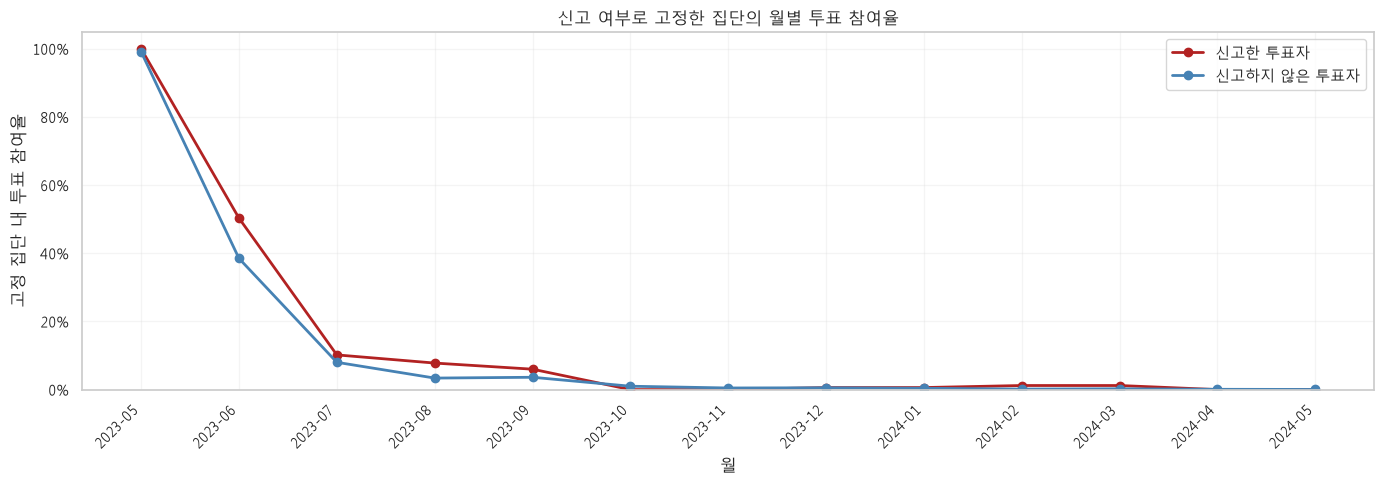

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fixed_activity_start = pd.Timestamp(params["start_at"])
fixed_activity_end = pd.Timestamp(params["end_at"])  # 미포함

# 1. 전체 조회 기간의 직접 투표 기록
df_fixed_activity_votes = (
    df_userquestionrecord[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_fixed_activity_votes["투표 시각"] = pd.to_datetime(
    df_fixed_activity_votes["created_at"],
    errors="raise",
)

df_fixed_activity_votes = (
    df_fixed_activity_votes.loc[
        df_fixed_activity_votes["투표 시각"].ge(fixed_activity_start)
        & df_fixed_activity_votes["투표 시각"].lt(fixed_activity_end)
    ]
    .copy()
)

df_fixed_activity_votes["월"] = (
    df_fixed_activity_votes["투표 시각"].dt.to_period("M")
)

# 2. 같은 전체 기간의 원본 질문 신고자
# 신고 사유·공통 유저 제외 조건은 적용하지 않음
df_fixed_activity_reports = (
    df_questionreport[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_fixed_activity_reports["신고 시각"] = pd.to_datetime(
    df_fixed_activity_reports["created_at"],
    errors="raise",
)

fixed_activity_reporter_ids = set(
    df_fixed_activity_reports.loc[
        df_fixed_activity_reports["신고 시각"].ge(
            fixed_activity_start
        )
        & df_fixed_activity_reports["신고 시각"].lt(
            fixed_activity_end
        ),
        "user_id",
    ]
)

# 3. 전체 기간 투표자를 두 집단으로 고정
df_fixed_activity_users = (
    df_fixed_activity_votes[["user_id"]]
    .drop_duplicates()
    .copy()
)

df_fixed_activity_users["집단"] = (
    df_fixed_activity_users["user_id"]
    .isin(fixed_activity_reporter_ids)
    .map({
        True: "신고한 투표자",
        False: "신고하지 않은 투표자",
    })
)

fixed_activity_group_order = [
    "신고한 투표자",
    "신고하지 않은 투표자",
]

df_fixed_activity_group_sizes = (
    df_fixed_activity_users
    .groupby("집단")["user_id"]
    .nunique()
    .reindex(fixed_activity_group_order, fill_value=0)
    .rename("집단 전체 유저 수")
    .reset_index()
)

# 4. 월별 고유 투표 참여 인원
df_fixed_activity_monthly_counts = (
    df_fixed_activity_votes
    .merge(
        df_fixed_activity_users,
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
    .groupby(["월", "집단"])["user_id"]
    .nunique()
    .rename("월별 투표 참여 인원")
    .reset_index()
)

# 투표자가 없는 월도 포함
fixed_activity_months = pd.period_range(
    fixed_activity_start.to_period("M"),
    (
        fixed_activity_end - pd.Timedelta(nanoseconds=1)
    ).to_period("M"),
    freq="M",
)

df_fixed_activity_monthly = (
    pd.DataFrame({"월": fixed_activity_months})
    .merge(df_fixed_activity_group_sizes, how="cross")
    .merge(
        df_fixed_activity_monthly_counts,
        on=["월", "집단"],
        how="left",
        validate="one_to_one",
    )
)

df_fixed_activity_monthly["월별 투표 참여 인원"] = (
    df_fixed_activity_monthly["월별 투표 참여 인원"]
    .fillna(0)
    .astype(int)
)

df_fixed_activity_monthly["월별 투표 참여율(%)"] = (
    df_fixed_activity_monthly["월별 투표 참여 인원"]
    .div(
        df_fixed_activity_monthly["집단 전체 유저 수"].where(
            df_fixed_activity_monthly["집단 전체 유저 수"].gt(0)
        )
    )
    .mul(100)
)

df_fixed_activity_monthly["집단"] = pd.Categorical(
    df_fixed_activity_monthly["집단"],
    categories=fixed_activity_group_order,
    ordered=True,
)

df_fixed_activity_monthly = (
    df_fixed_activity_monthly
    .sort_values(["월", "집단"])
    .reset_index(drop=True)
)

df_fixed_activity_monthly["조회 범위"] = [
    (
        "전체 월"
        if (
            fixed_activity_start <= month.start_time
            and fixed_activity_end >= (month + 1).start_time
        )
        else "부분 월"
    )
    for month in df_fixed_activity_monthly["월"]
]

# 5. 표 출력
print("[고정 집단 인원]")
display(df_fixed_activity_group_sizes)

df_fixed_activity_display = df_fixed_activity_monthly.copy()
df_fixed_activity_display["월"] = (
    df_fixed_activity_display["월"].astype(str)
)

print("\n[월별 투표 참여]")
display(df_fixed_activity_display.round(2))

# 6. 선그래프
fig, ax = plt.subplots(figsize=(14, 5))

for group, color in [
    ("신고한 투표자", "firebrick"),
    ("신고하지 않은 투표자", "steelblue"),
]:
    plot_data = df_fixed_activity_monthly.loc[
        df_fixed_activity_monthly["집단"].eq(group)
    ]

    ax.plot(
        plot_data["월"].astype(str),
        plot_data["월별 투표 참여율(%)"],
        marker="o",
        linewidth=2,
        color=color,
        label=group,
    )

ax.set_title("신고 여부로 고정한 집단의 월별 투표 참여율")
ax.set_xlabel("월")
ax.set_ylabel("고정 집단 내 투표 참여율")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(alpha=0.2)
ax.legend()

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [66]:
# 1. 월별 참여 인원·참여율을 좌우로 배치
df_monthly_activity_comparison = (
    df_fixed_activity_monthly
    .pivot(
        index="월",
        columns="집단",
        values=[
            "월별 투표 참여 인원",
            "월별 투표 참여율(%)",
        ],
    )
)

df_monthly_activity_comparison = (
    df_monthly_activity_comparison.reindex(columns=[
        ("월별 투표 참여 인원", "신고한 투표자"),
        ("월별 투표 참여 인원", "신고하지 않은 투표자"),
        ("월별 투표 참여율(%)", "신고한 투표자"),
        ("월별 투표 참여율(%)", "신고하지 않은 투표자"),
    ])
)

df_monthly_activity_comparison.columns = [
    "신고자 참여 인원",
    "비신고자 참여 인원",
    "신고자 참여율(%)",
    "비신고자 참여율(%)",
]

df_monthly_activity_comparison = (
    df_monthly_activity_comparison
    .reset_index()
)

df_monthly_activity_comparison["월"] = (
    df_monthly_activity_comparison["월"].astype(str)
)

# 부분 월 표시
partial_months = set(
    df_fixed_activity_monthly.loc[
        df_fixed_activity_monthly["조회 범위"].eq("부분 월"),
        "월",
    ].astype(str)
)

df_monthly_activity_comparison["월"] = [
    f"{month} *" if month in partial_months else month
    for month in df_monthly_activity_comparison["월"]
]

print("고정 집단: 신고자 167명 / 비신고자 4,646명")
print("* 부분 조회 월")

display(
    df_monthly_activity_comparison.style
    .format({
        "신고자 참여 인원": "{:,.0f}",
        "비신고자 참여 인원": "{:,.0f}",
        "신고자 참여율(%)": "{:.2f}",
        "비신고자 참여율(%)": "{:.2f}",
    })
    .hide(axis="index")
)

고정 집단: 신고자 167명 / 비신고자 4,646명
* 부분 조회 월


월,신고자 참여 인원,비신고자 참여 인원,신고자 참여율(%),비신고자 참여율(%)
2023-05 *,167,"4,604",100.00,99.10
2023-06,84,"1,788",50.30,38.48
2023-07,17,372,10.18,8.01
2023-08,13,157,7.78,3.38
2023-09,10,168,5.99,3.62
2023-10,0,46,0.00,0.99
2023-11,0,22,0.00,0.47
2023-12,1,25,0.60,0.54
2024-01,1,18,0.60,0.39
2024-02,2,7,1.20,0.15


In [67]:
import pandas as pd

monthly_revote_start = pd.Timestamp(params["start_at"])
monthly_revote_end = pd.Timestamp(params["end_at"])  # 미포함

# 1. 직접 투표 기록
df_month_revote_votes = (
    df_userquestionrecord[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_month_revote_votes["투표 시각"] = pd.to_datetime(
    df_month_revote_votes["created_at"],
    errors="raise",
)

df_month_revote_votes = (
    df_month_revote_votes.loc[
        df_month_revote_votes["투표 시각"].ge(monthly_revote_start)
        & df_month_revote_votes["투표 시각"].lt(monthly_revote_end)
    ]
    .copy()
)

df_month_revote_votes["투표일"] = (
    df_month_revote_votes["투표 시각"].dt.normalize()
)

df_month_revote_votes["월"] = (
    df_month_revote_votes["투표 시각"].dt.to_period("M")
)

# 2. 전체 조회 기간의 원본 질문 신고자
# 신고 사유·공통 유저 제외 조건 미적용
df_month_revote_reports = (
    df_questionreport[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_month_revote_reports["신고 시각"] = pd.to_datetime(
    df_month_revote_reports["created_at"],
    errors="raise",
)

month_revote_all_reporter_ids = set(
    df_month_revote_reports.loc[
        df_month_revote_reports["신고 시각"].ge(
            monthly_revote_start
        )
        & df_month_revote_reports["신고 시각"].lt(
            monthly_revote_end
        ),
        "user_id",
    ]
)

# 3. 개인별·월별 첫 투표일
df_month_revote_cohort = (
    df_month_revote_votes
    .groupby(["월", "user_id"], observed=True)["투표일"]
    .min()
    .reset_index(name="기준일")
)

# 전체 기간 신고 여부로 고정
# 기존 출력 코드와 연결되도록 집단명은 유지
df_month_revote_cohort["집단"] = (
    df_month_revote_cohort["user_id"]
    .isin(month_revote_all_reporter_ids)
    .map({
        True: "해당 월 신고자",
        False: "해당 월 비신고자",
    })
)

# 이후 30일을 끝까지 확인할 수 있는 유저만 포함
df_month_revote_cohort["30일 관측 가능"] = (
    df_month_revote_cohort["기준일"]
    + pd.Timedelta(days=31)
).le(monthly_revote_end)

df_month_revote_coverage = (
    df_month_revote_cohort
    .groupby("월", observed=True)
    .agg(
        월간_투표자=("user_id", "nunique"),
        분석_대상=("30일 관측 가능", "sum"),
    )
    .rename(columns={
        "월간_투표자": "월간 투표자 수",
        "분석_대상": "30일 관측 가능 유저 수",
    })
    .reset_index()
)

df_month_revote_cohort = (
    df_month_revote_cohort.loc[
        df_month_revote_cohort["30일 관측 가능"]
    ]
    .copy()
)

df_month_revote_days = (
    df_month_revote_votes[["user_id", "투표일"]]
    .drop_duplicates()
)

# 4. 월 첫 투표일 다음 날부터 재투표 확인
month_revote_parts = []

for month, cohort in df_month_revote_cohort.groupby(
    "월", observed=True
):
    cohort = cohort.copy()
    cohort["기준일"] = pd.to_datetime(cohort["기준일"])

    if cohort.empty:
        continue

    window_start = (
        pd.Timestamp(cohort["기준일"].min())
        + pd.Timedelta(days=1)
    )
    window_end = (
        pd.Timestamp(cohort["기준일"].max())
        + pd.Timedelta(days=30)
    )

    vote_days = df_month_revote_days.loc[
        df_month_revote_days["투표일"].between(
            window_start, window_end
        )
    ]

    detail = cohort[["user_id", "기준일"]].merge(
        vote_days,
        on="user_id",
        how="inner",
        validate="one_to_many",
    )

    detail["경과일"] = (
        detail["투표일"] - detail["기준일"]
    ).dt.days

    next_vote = (
        detail.loc[detail["경과일"].between(1, 30)]
        .groupby("user_id")["투표일"]
        .min()
        .rename("30일 내 다음 투표일")
        .reset_index()
    )

    result = cohort.merge(
        next_vote,
        on="user_id",
        how="left",
        validate="one_to_one",
    )

    result["다음 투표까지 경과일"] = (
        result["30일 내 다음 투표일"] - result["기준일"]
    ).dt.days

    for days in [1, 7, 30]:
        result[f"{days}일 내 재투표"] = (
            result["다음 투표까지 경과일"].between(1, days)
        )

    month_revote_parts.append(result)

if not month_revote_parts:
    raise ValueError("이후 30일을 관측할 수 있는 유저가 없습니다.")

df_month_revote_result = pd.concat(
    month_revote_parts,
    ignore_index=True,
)

# 5. 월별·집단별 재투표율
df_month_revote_summary = (
    df_month_revote_result
    .groupby(["월", "집단"], observed=True)
    .agg(
        유저_수=("user_id", "nunique"),
        재투표_1일=("1일 내 재투표", "sum"),
        재투표_7일=("7일 내 재투표", "sum"),
        재투표_30일=("30일 내 재투표", "sum"),
    )
    .reset_index()
    .rename(columns={
        "유저_수": "유저 수",
        "재투표_1일": "1일 내 재투표 인원",
        "재투표_7일": "7일 내 재투표 인원",
        "재투표_30일": "30일 내 재투표 인원",
    })
)

for days in [1, 7, 30]:
    df_month_revote_summary[f"{days}일 내 재투표율(%)"] = (
        df_month_revote_summary[f"{days}일 내 재투표 인원"]
        / df_month_revote_summary["유저 수"]
        * 100
    )

# 6. 신고자·비신고자를 옆에 배치
df_month_revote_comparison = (
    df_month_revote_summary
    .pivot(
        index="월",
        columns="집단",
        values=[
            "유저 수",
            "1일 내 재투표율(%)",
            "7일 내 재투표율(%)",
            "30일 내 재투표율(%)",
        ],
    )
    .reindex(columns=pd.MultiIndex.from_product([
        [
            "유저 수",
            "1일 내 재투표율(%)",
            "7일 내 재투표율(%)",
            "30일 내 재투표율(%)",
        ],
        ["해당 월 신고자", "해당 월 비신고자"],
    ]))
)

df_month_revote_comparison.columns = [
    f"{metric} · {'신고자' if group == '해당 월 신고자' else '비신고자'}"
    for metric, group in df_month_revote_comparison.columns
]

df_month_revote_comparison = (
    df_month_revote_comparison.reset_index()
)

df_month_revote_comparison["월"] = (
    df_month_revote_comparison["월"].astype(str)
)

display(df_month_revote_comparison.round(2))

print("\n[월별 관측 가능 인원]")
display(df_month_revote_coverage)

C:\Users\USER\AppData\Local\Temp\ipykernel_33836\4248879155.py:83: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=31)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\4248879155.py:126: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=1)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\4248879155.py:130: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=30)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\4248879155.py:126: Deprecatio

,월,유저 수 · 신고자,유저 수 · 비신고자,1일 내 재투표율(%) · 신고자,1일 내 재투표율(%) · 비신고자,7일 내 재투표율(%) · 신고자,7일 내 재투표율(%) · 비신고자,30일 내 재투표율(%) · 신고자,30일 내 재투표율(%) · 비신고자
0,2023-05,167.0,4604.0,97.60,88.97,99.40,95.44,99.40,96.35
1,2023-06,84.0,1788.0,29.76,30.65,50.00,56.38,50.00,63.93
2,2023-07,17.0,372.0,17.65,9.68,29.41,22.04,47.06,32.80
3,2023-08,13.0,157.0,7.69,9.55,15.38,21.02,30.77,31.85
4,2023-09,10.0,168.0,20.00,5.36,30.00,17.26,40.00,29.76
5,2023-10,NaN,46.0,NaN,8.70,NaN,10.87,NaN,13.04
6,2023-11,NaN,22.0,NaN,13.64,NaN,27.27,NaN,31.82
7,2023-12,1.0,25.0,0.00,16.00,0.00,32.00,0.00,36.00
8,2024-01,1.0,18.0,0.00,16.67,100.00,16.67,100.00,22.22
9,2024-02,2.0,7.0,50.00,0.00,100.00,0.00,100.00,0.00



[월별 관측 가능 인원]


,월,월간 투표자 수,30일 관측 가능 유저 수
0,2023-05,4771,4771
1,2023-06,1872,1872
2,2023-07,389,389
3,2023-08,170,170
4,2023-09,178,178
5,2023-10,46,46
6,2023-11,22,22
7,2023-12,26,26
8,2024-01,19,19
9,2024-02,9,9


## (폐기) 2회 이상 신고 후 출석률


In [68]:
import json
import pandas as pd

repeat_report_start = pd.Timestamp("2023-05-27")
repeat_attendance_end = pd.Timestamp("2024-05-09")

repeat_target_reasons = [
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
]


def parse_repeat_attendance(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 1. 5월 27일 이후 지정 사유 신고
df_repeat_reports = (
    df_questionreport_filtered.loc[
        df_questionreport_filtered["reason"]
        .astype("string")
        .str.strip()
        .isin(repeat_target_reasons),
        ["id", "user_id", "created_at"],
    ]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_repeat_reports["신고 시각"] = pd.to_datetime(
    df_repeat_reports["created_at"],
    errors="raise",
)

df_repeat_reports = (
    df_repeat_reports.loc[
        df_repeat_reports["신고 시각"].ge(repeat_report_start)
    ]
    .sort_values(["user_id", "신고 시각", "id"])
    .copy()
)

df_repeat_reports["기간 내 신고 순서"] = (
    df_repeat_reports.groupby("user_id").cumcount() + 1
)

# 2. 유저별 두 번째 신고일
df_repeat_report_cohort = (
    df_repeat_reports.loc[
        df_repeat_reports["기간 내 신고 순서"].eq(2),
        ["user_id", "신고 시각"],
    ]
    .rename(columns={"신고 시각": "두 번째 신고 시각"})
    .copy()
)

df_repeat_report_cohort["기준일"] = (
    df_repeat_report_cohort["두 번째 신고 시각"].dt.normalize()
)

# 이후 30일 전체를 관측할 수 있는 유저만 포함
df_repeat_report_cohort["30일 관측 가능"] = (
    df_repeat_report_cohort["기준일"]
    + pd.Timedelta(days=30)
).le(repeat_attendance_end)

df_repeat_report_cohort["출석 테이블 연결"] = (
    df_repeat_report_cohort["user_id"].isin(
        df_attendance["user_id"].dropna()
    )
)

repeat_total_users = len(df_repeat_report_cohort)

df_repeat_report_eligible = (
    df_repeat_report_cohort.loc[
        df_repeat_report_cohort["30일 관측 가능"]
        & df_repeat_report_cohort["출석 테이블 연결"]
    ]
    .copy()
)

if df_repeat_report_eligible.empty:
    raise ValueError("출석 연결 및 30일 관측 조건을 만족하는 유저가 없습니다.")

# 3. 대상 유저의 출석 날짜 펼치기
df_repeat_attendance = (
    df_attendance.loc[
        df_attendance["user_id"].isin(
            df_repeat_report_eligible["user_id"]
        ),
        ["user_id", "attendance_date_list"],
    ]
    .copy()
)

df_repeat_attendance["출석일"] = (
    df_repeat_attendance["attendance_date_list"]
    .apply(parse_repeat_attendance)
)

df_repeat_attendance = (
    df_repeat_attendance
    .explode("출석일")
    .dropna(subset=["출석일"])
    [["user_id", "출석일"]]
    .copy()
)

df_repeat_attendance["출석일"] = pd.to_datetime(
    df_repeat_attendance["출석일"],
    errors="raise",
).dt.normalize()

df_repeat_attendance = (
    df_repeat_attendance
    .drop_duplicates(["user_id", "출석일"])
)

# 4. 두 번째 신고일 이후 출석 확인
df_repeat_attendance_detail = (
    df_repeat_report_eligible[["user_id", "기준일"]]
    .merge(
        df_repeat_attendance,
        on="user_id",
        how="left",
        validate="one_to_many",
    )
)

df_repeat_attendance_detail["기준일 대비 일수"] = (
    df_repeat_attendance_detail["출석일"]
    - df_repeat_attendance_detail["기준일"]
).dt.days

df_repeat_attendance_detail["7일 내 출석"] = (
    df_repeat_attendance_detail["기준일 대비 일수"]
    .between(1, 7)
)

df_repeat_attendance_detail["30일 내 출석"] = (
    df_repeat_attendance_detail["기준일 대비 일수"]
    .between(1, 30)
)

df_repeat_user_activity = (
    df_repeat_attendance_detail
    .groupby("user_id", as_index=False)
    .agg(
        출석일_7일=("7일 내 출석", "sum"),
        출석일_30일=("30일 내 출석", "sum"),
    )
    .rename(columns={
        "출석일_7일": "이후 7일 출석일 수",
        "출석일_30일": "이후 30일 출석일 수",
    })
)

df_repeat_attendance_result = (
    df_repeat_report_eligible
    .merge(
        df_repeat_user_activity,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

df_repeat_attendance_result["7일 내 출석 있음"] = (
    df_repeat_attendance_result["이후 7일 출석일 수"].gt(0)
)

df_repeat_attendance_result["30일 내 출석 있음"] = (
    df_repeat_attendance_result["이후 30일 출석일 수"].gt(0)
)

# 5. 전체 요약
repeat_analysis_users = len(df_repeat_attendance_result)

df_repeat_attendance_summary = pd.DataFrame([
    {
        "기간": f"{days}일 내",
        "분석 유저 수": repeat_analysis_users,
        "출석 유저 수": int(
            df_repeat_attendance_result[
                f"{days}일 내 출석 있음"
            ].sum()
        ),
        "출석 없는 유저 수": int(
            (~df_repeat_attendance_result[
                f"{days}일 내 출석 있음"
            ]).sum()
        ),
        "출석률(%)": (
            df_repeat_attendance_result[
                f"{days}일 내 출석 있음"
            ].mean() * 100
        ),
    }
    for days in [7, 30]
])

print(f"5월 27일 이후 신고 2건 이상 유저: {repeat_total_users:,}명")
print(
    "출석 테이블 연결 불가:",
    f"{(~df_repeat_report_cohort['출석 테이블 연결']).sum():,}명",
)
print(
    "이후 30일 관측 불가:",
    f"{(~df_repeat_report_cohort['30일 관측 가능']).sum():,}명",
)
print(f"최종 분석 대상: {repeat_analysis_users:,}명")

display(df_repeat_attendance_summary.round(2))

# 개인별 결과
display(
    df_repeat_attendance_result[[
        "user_id",
        "두 번째 신고 시각",
        "기준일",
        "이후 7일 출석일 수",
        "이후 30일 출석일 수",
        "7일 내 출석 있음",
        "30일 내 출석 있음",
    ]]
    .sort_values("두 번째 신고 시각")
    .reset_index(drop=True)
)

5월 27일 이후 신고 2건 이상 유저: 1,193명
출석 테이블 연결 불가: 184명
이후 30일 관측 불가: 3명
최종 분석 대상: 1,006명


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3370057133.py:79: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=30)


,기간,분석 유저 수,출석 유저 수,출석 없는 유저 수,출석률(%)
0,7일 내,1006,754,252,74.95
1,30일 내,1006,793,213,78.83


,user_id,두 번째 신고 시각,기준일,이후 7일 출석일 수,이후 30일 출석일 수,7일 내 출석 있음,30일 내 출석 있음
0,1333368,2023-05-27 01:06:21,2023-05-27,1,15,True,True
1,845451,2023-05-27 01:17:21,2023-05-27,7,26,True,True
2,1318263,2023-05-27 01:20:05,2023-05-27,0,0,False,False
3,1431243,2023-05-27 01:23:51,2023-05-27,0,6,False,True
4,1504785,2023-05-27 01:24:37,2023-05-27,4,4,True,True
...,...,...,...,...,...,...,...
1001,1574418,2024-01-30 01:43:27,2024-01-30,0,0,False,False
1002,1247128,2024-02-02 09:48:53,2024-02-02,0,0,False,False
1003,1160430,2024-02-22 17:13:53,2024-02-22,0,0,False,False
1004,1354872,2024-03-09 03:56:16,2024-03-09,0,0,False,False


In [69]:
import numpy as np
import pandas as pd

nonreport_rng = np.random.default_rng(42)

# 1. 원본 질문 신고 이력이 없는 유저
# 제외된 신고자를 비신고자로 분류하지 않도록 원본 사용
nonreport_all_reporter_ids = set(
    df_questionreport["user_id"].dropna()
)

nonreport_pool_ids = sorted(
    (
        set(df_user["id"].dropna())
        & set(df_attendance["user_id"].dropna())
    )
    - nonreport_all_reporter_ids
)

nonreport_target_size = len(df_repeat_attendance_result)

if not nonreport_pool_ids:
    raise ValueError("출석 테이블에 연결되는 비신고자가 없습니다.")

# 2. 비교군 추출 및 기준일 부여
if len(nonreport_pool_ids) >= nonreport_target_size:
    nonreport_selected_ids = nonreport_rng.choice(
        nonreport_pool_ids,
        size=nonreport_target_size,
        replace=False,
    )

    # 신고자와 동일한 기준일 분포
    nonreport_anchor_dates = (
        df_repeat_attendance_result["기준일"]
        .to_numpy()
        .copy()
    )
else:
    nonreport_selected_ids = np.array(nonreport_pool_ids)

    # 후보가 부족하면 신고자 기준일 중 일부를 추출
    nonreport_anchor_dates = nonreport_rng.choice(
        df_repeat_attendance_result["기준일"].to_numpy(),
        size=len(nonreport_selected_ids),
        replace=False,
    )

nonreport_rng.shuffle(nonreport_anchor_dates)

df_nonreport_attendance_cohort = pd.DataFrame({
    "user_id": nonreport_selected_ids,
    "기준일": pd.to_datetime(nonreport_anchor_dates),
})

# 3. 비교군 출석 날짜 정리
df_nonreport_attendance = df_attendance.loc[
    df_attendance["user_id"].isin(nonreport_selected_ids),
    ["user_id", "attendance_date_list"],
].copy()

# 앞선 반복 신고자 셀의 함수 사용
df_nonreport_attendance["출석일"] = (
    df_nonreport_attendance["attendance_date_list"]
    .apply(parse_repeat_attendance)
)

df_nonreport_attendance = (
    df_nonreport_attendance
    .explode("출석일")
    .dropna(subset=["출석일"])
    [["user_id", "출석일"]]
    .copy()
)

df_nonreport_attendance["출석일"] = pd.to_datetime(
    df_nonreport_attendance["출석일"],
    errors="raise",
).dt.normalize()

df_nonreport_attendance = (
    df_nonreport_attendance
    .drop_duplicates(["user_id", "출석일"])
)

# 4. 기준일 이후 출석 확인
df_nonreport_attendance_detail = (
    df_nonreport_attendance_cohort
    .merge(
        df_nonreport_attendance,
        on="user_id",
        how="left",
        validate="one_to_many",
    )
)

df_nonreport_attendance_detail["기준일 대비 일수"] = (
    df_nonreport_attendance_detail["출석일"]
    - df_nonreport_attendance_detail["기준일"]
).dt.days

for days in [7, 30]:
    df_nonreport_attendance_detail[f"{days}일 내 출석 있음"] = (
        df_nonreport_attendance_detail["기준일 대비 일수"]
        .between(1, days)
    )

df_nonreport_attendance_result = (
    df_nonreport_attendance_detail
    .groupby("user_id", as_index=False)
    .agg(
        기준일=("기준일", "first"),
        출석_7일=("7일 내 출석 있음", "any"),
        출석_30일=("30일 내 출석 있음", "any"),
    )
    .rename(columns={
        "출석_7일": "7일 내 출석 있음",
        "출석_30일": "30일 내 출석 있음",
    })
)

# 5. 반복 신고자·비신고자 비교
df_repeat_vs_nonreport_summary = pd.DataFrame([
    {
        "집단": group_name,
        "유저 수": len(source),
        "7일 내 출석 유저 수": int(
            source["7일 내 출석 있음"].sum()
        ),
        "7일 내 출석률(%)": (
            source["7일 내 출석 있음"].mean() * 100
        ),
        "30일 내 출석 유저 수": int(
            source["30일 내 출석 있음"].sum()
        ),
        "30일 내 출석률(%)": (
            source["30일 내 출석 있음"].mean() * 100
        ),
    }
    for group_name, source in [
        ("반복 신고자", df_repeat_attendance_result),
        ("비신고자", df_nonreport_attendance_result),
    ]
])

print(f"비신고자 후보: {len(nonreport_pool_ids):,}명")
print(f"선정된 비신고자: {len(df_nonreport_attendance_result):,}명")

display(df_repeat_vs_nonreport_summary.round(2))

비신고자 후보: 335,301명
선정된 비신고자: 1,006명


,집단,유저 수,7일 내 출석 유저 수,7일 내 출석률(%),30일 내 출석 유저 수,30일 내 출석률(%)
0,반복 신고자,1006,754,74.95,793,78.83
1,비신고자,1006,581,57.75,644,64.02


## 1회 이상 신고한 사람의 구매기록


In [70]:
import pandas as pd

# 기존 DB 연결 객체 engine 사용
df_paymenthistory = pd.read_sql(
    """
    SELECT id, user_id, productId, created_at
    FROM accounts_paymenthistory
    """,
    con=engine,
)

# 1. 전체 일반 유저
df_user_purchase_status = (
    df_user[["id"]]
    .dropna()
    .drop_duplicates()
    .rename(columns={"id": "user_id"})
)

# 2. 유저별 구매 기록 수
user_purchase_counts = (
    df_paymenthistory
    .groupby("user_id")["id"]
    .nunique()
    .reset_index(name="구매 기록 수")
)

df_user_purchase_status = df_user_purchase_status.merge(
    user_purchase_counts,
    on="user_id",
    how="left",
    validate="one_to_one",
)

df_user_purchase_status["구매 기록 수"] = (
    df_user_purchase_status["구매 기록 수"]
    .fillna(0)
    .astype(int)
)

df_user_purchase_status["구분"] = (
    df_user_purchase_status["구매 기록 수"]
    .gt(0)
    .map({
        True: "구매 기록 있음",
        False: "구매 기록 없음",
    })
)

# 3. 전체 구매 기록 보유율
df_purchase_user_summary = (
    df_user_purchase_status["구분"]
    .value_counts()
    .reindex(
        ["구매 기록 있음", "구매 기록 없음"],
        fill_value=0,
    )
    .rename_axis("구분")
    .reset_index(name="유저 수")
)

total_purchase_analysis_users = len(df_user_purchase_status)

df_purchase_user_summary["비율(%)"] = (
    df_purchase_user_summary["유저 수"]
    / total_purchase_analysis_users * 100
    if total_purchase_analysis_users else float("nan")
)

display(df_purchase_user_summary.round(2))

# 4. 상품별 구매 기록 보유율
df_product_purchase_summary = (
    df_paymenthistory.loc[
        df_paymenthistory["user_id"].isin(
            df_user_purchase_status["user_id"]
        )
    ]
    .groupby("productId")
    .agg(
        구매_유저_수=("user_id", "nunique"),
        구매_기록_수=("id", "nunique"),
    )
    .reset_index()
    .rename(columns={
        "구매_유저_수": "구매 유저 수",
        "구매_기록_수": "구매 기록 수",
    })
)

df_product_purchase_summary["전체 유저 중 비율(%)"] = (
    df_product_purchase_summary["구매 유저 수"]
    / total_purchase_analysis_users * 100
    if total_purchase_analysis_users else float("nan")
)

display(
    df_product_purchase_summary
    .sort_values("구매 유저 수", ascending=False)
    .reset_index(drop=True)
    .round(2)
)

,구분,유저 수,비율(%)
0,구매 기록 있음,59192,8.74
1,구매 기록 없음,617889,91.26


,productId,구매 유저 수,구매 기록 수,전체 유저 중 비율(%)
0,heart.777,57432,57873,8.48
1,heart.1000,11124,19309,1.64
2,heart.200,9383,15822,1.39
3,heart.4000,1501,2136,0.22


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\393304200.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  purchase_start = purchase_reference_date - pd.Timedelta(days=10)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\393304200.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  purchase_end = purchase_reference_date + pd.Timedelta(days=10)


,날짜,구매 기록 수,구매 유저 수,해당일까지 가입한 유저 수,일별 구매 기록 보유율(%)
0,2023-05-04,NaN,NaN,35507,NaN
1,2023-05-05,NaN,NaN,41841,NaN
2,2023-05-06,NaN,NaN,80894,NaN
3,2023-05-07,NaN,NaN,129433,NaN
4,2023-05-08,NaN,NaN,168283,NaN
5,2023-05-09,NaN,NaN,208778,NaN
6,2023-05-10,NaN,NaN,248600,NaN
7,2023-05-11,NaN,NaN,285186,NaN
8,2023-05-12,NaN,NaN,318403,NaN
9,2023-05-13,421.0,362.0,364661,0.0993


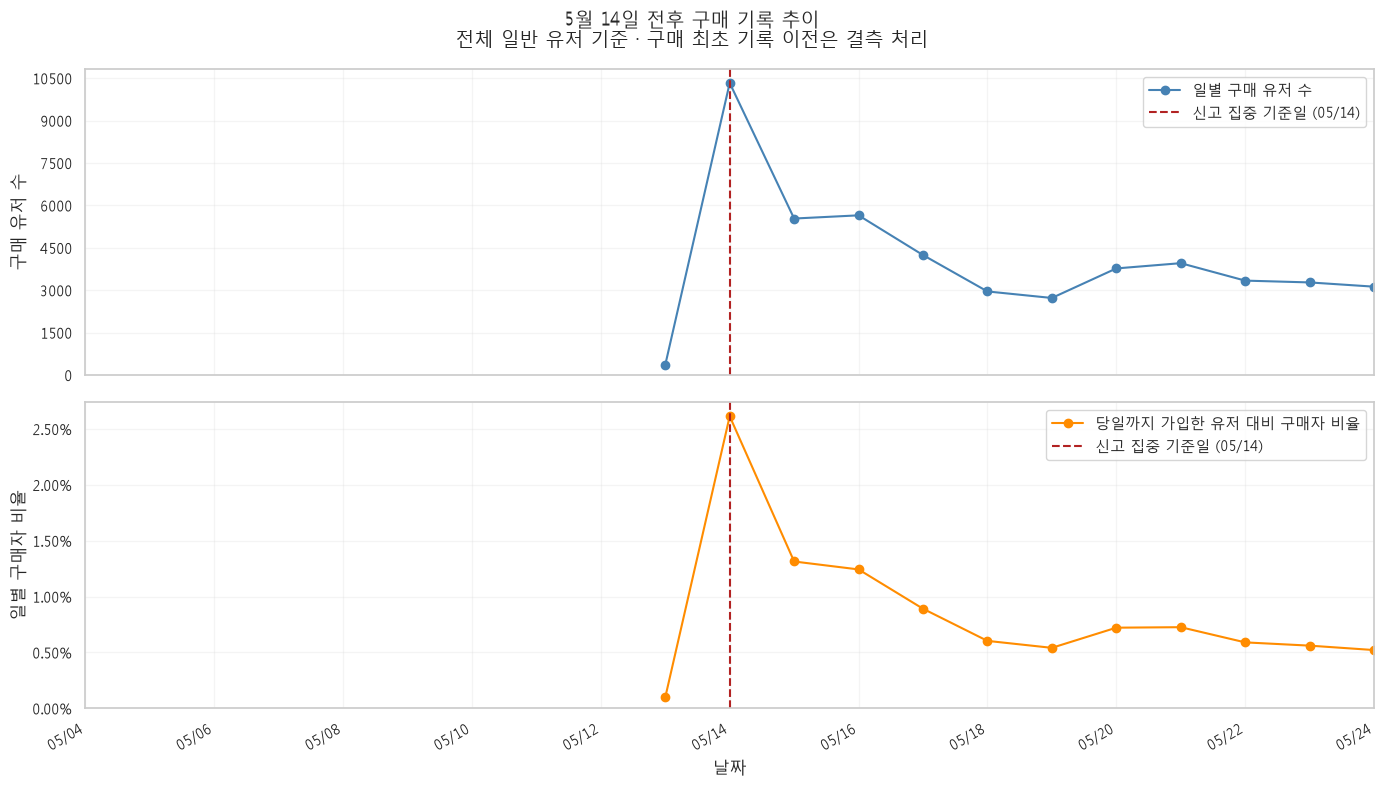

구매 최초 기록일: 2023-05-13


In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, MaxNLocator

# 기존 df_paymenthistory와 df_user 사용
purchase_reference_date = pd.Timestamp("2023-05-14")
purchase_start = purchase_reference_date - pd.Timedelta(days=10)
purchase_end = purchase_reference_date + pd.Timedelta(days=10)

# 1. 구매 기록
df_purchase_daily_source = (
    df_paymenthistory
    .drop_duplicates("id")
    .copy()
)

df_purchase_daily_source["구매 시각"] = pd.to_datetime(
    df_purchase_daily_source["created_at"],
    errors="raise",
)

df_purchase_daily_source["날짜"] = (
    df_purchase_daily_source["구매 시각"].dt.normalize()
)

purchase_first_record_date = (
    df_purchase_daily_source["날짜"].min()
)
purchase_last_record_date = (
    df_purchase_daily_source["날짜"].max()
)

if pd.isna(purchase_first_record_date):
    raise ValueError("구매 기록이 없습니다.")

# 2. 전체 일반 유저의 가입일
df_purchase_daily_users = (
    df_user[["id", "created_at"]]
    .drop_duplicates("id")
    .copy()
)

df_purchase_daily_users["가입일"] = pd.to_datetime(
    df_purchase_daily_users["created_at"],
    errors="raise",
).dt.normalize()

if df_purchase_daily_users["가입일"].isna().any():
    raise ValueError("가입일 결측을 확인해 주세요.")

# 일반 유저 구매만 포함
df_purchase_daily_source = (
    df_purchase_daily_source.loc[
        df_purchase_daily_source["user_id"].isin(
            df_purchase_daily_users["id"]
        )
    ]
    .copy()
)

# 3. 날짜별 구매 건수·구매자 수
purchase_dates = pd.date_range(
    purchase_start, purchase_end, freq="D"
)

df_purchase_daily_summary = (
    df_purchase_daily_source.loc[
        df_purchase_daily_source["날짜"].between(
            purchase_start, purchase_end
        )
    ]
    .groupby("날짜")
    .agg(
        구매_기록_수=("id", "nunique"),
        구매_유저_수=("user_id", "nunique"),
    )
    .reindex(purchase_dates, fill_value=0)
    .rename(columns={
        "구매_기록_수": "구매 기록 수",
        "구매_유저_수": "구매 유저 수",
    })
    .rename_axis("날짜")
    .reset_index()
)

df_purchase_daily_summary["해당일까지 가입한 유저 수"] = [
    int(df_purchase_daily_users["가입일"].le(day).sum())
    for day in df_purchase_daily_summary["날짜"]
]

# 최초·마지막 구매 기록 밖의 날짜는 결측 처리
purchase_observed_mask = (
    df_purchase_daily_summary["날짜"].between(
        purchase_first_record_date,
        purchase_last_record_date,
    )
)

df_purchase_daily_summary.loc[
    ~purchase_observed_mask,
    ["구매 기록 수", "구매 유저 수"],
] = float("nan")

df_purchase_daily_summary["일별 구매 기록 보유율(%)"] = (
    df_purchase_daily_summary["구매 유저 수"]
    .div(
        df_purchase_daily_summary["해당일까지 가입한 유저 수"]
        .where(
            df_purchase_daily_summary[
                "해당일까지 가입한 유저 수"
            ].gt(0)
        )
    )
    .mul(100)
)

display(df_purchase_daily_summary.round(4))

# 4. 그래프
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True,
)

axes[0].plot(
    df_purchase_daily_summary["날짜"],
    df_purchase_daily_summary["구매 유저 수"],
    color="steelblue",
    marker="o",
    label="일별 구매 유저 수",
)

axes[0].set_ylabel("구매 유저 수")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))

axes[1].plot(
    df_purchase_daily_summary["날짜"],
    df_purchase_daily_summary["일별 구매 기록 보유율(%)"],
    color="darkorange",
    marker="o",
    label="당일까지 가입한 유저 대비 구매자 비율",
)

axes[1].set_ylabel("일별 구매자 비율")
axes[1].set_xlabel("날짜")
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))

for ax in axes:
    ax.axvline(
        purchase_reference_date,
        color="firebrick",
        linestyle="--",
        label="신고 집중 기준일 (05/14)",
    )
    ax.set_xlim(purchase_start, purchase_end)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend()

axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

fig.suptitle(
    "5월 14일 전후 구매 기록 추이\n"
    "전체 일반 유저 기준 · 구매 최초 기록 이전은 결측 처리",
    fontsize=14,
)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(f"구매 최초 기록일: {purchase_first_record_date:%Y-%m-%d}")

In [72]:
import pandas as pd

purchase_compare_window = 30

# 1. 전체 일반 유저의 구매 기록
df_purchase_compare_source = (
    df_paymenthistory.loc[
        df_paymenthistory["user_id"].isin(df_user["id"]),
        ["id", "user_id", "productId", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_purchase_compare_source["구매일"] = pd.to_datetime(
    df_purchase_compare_source["created_at"],
    errors="raise",
).dt.normalize()

purchase_compare_start = (
    df_purchase_compare_source["구매일"].min()
)
purchase_compare_end = (
    df_purchase_compare_source["구매일"].max()
)

if pd.isna(purchase_compare_start):
    raise ValueError("구매 기록이 없습니다.")

# 2. 원본 질문 신고에서 유저별 첫 신고일
df_purchase_compare_reports = (
    df_questionreport.loc[
        df_questionreport["user_id"].isin(df_user["id"]),
        ["id", "user_id", "created_at"],
    ]
    .drop_duplicates("id")
    .copy()
)

df_purchase_compare_reports["신고 시각"] = pd.to_datetime(
    df_purchase_compare_reports["created_at"],
    errors="raise",
)

df_purchase_compare_cohort = (
    df_purchase_compare_reports
    .groupby("user_id")["신고 시각"]
    .min()
    .dt.normalize()
    .rename("첫 신고일")
    .reset_index()
)

# 신고 전후 30일을 모두 확인할 수 있는 유저만 포함
df_purchase_compare_cohort = (
    df_purchase_compare_cohort.loc[
        (
            df_purchase_compare_cohort["첫 신고일"]
            - pd.Timedelta(days=purchase_compare_window)
        ).ge(purchase_compare_start)
        & (
            df_purchase_compare_cohort["첫 신고일"]
            + pd.Timedelta(days=purchase_compare_window)
        ).le(purchase_compare_end)
    ]
    .copy()
)

# 3. 신고 전후 구매 기록 연결
df_purchase_compare_detail = (
    df_purchase_compare_cohort
    .merge(
        df_purchase_compare_source[["id", "user_id", "구매일"]],
        on="user_id",
        how="left",
        validate="one_to_many",
    )
)

df_purchase_compare_detail["신고일 대비 일수"] = (
    df_purchase_compare_detail["구매일"]
    - df_purchase_compare_detail["첫 신고일"]
).dt.days

df_purchase_compare_detail["신고 전 구매"] = (
    df_purchase_compare_detail["신고일 대비 일수"]
    .between(-purchase_compare_window, -1)
)

df_purchase_compare_detail["신고 후 구매"] = (
    df_purchase_compare_detail["신고일 대비 일수"]
    .between(1, purchase_compare_window)
)

df_purchase_compare_counts = (
    df_purchase_compare_detail
    .groupby("user_id", as_index=False)
    .agg(
        신고_전_구매_횟수=("신고 전 구매", "sum"),
        신고_후_구매_횟수=("신고 후 구매", "sum"),
    )
    .rename(columns={
        "신고_전_구매_횟수": "신고 전 30일 구매 횟수",
        "신고_후_구매_횟수": "신고 후 30일 구매 횟수",
    })
)

df_purchase_compare_result = (
    df_purchase_compare_cohort
    .merge(
        df_purchase_compare_counts,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# 신고 이전 30일에 구매 기록이 있던 유저만 선정
df_purchase_compare_result = (
    df_purchase_compare_result.loc[
        df_purchase_compare_result["신고 전 30일 구매 횟수"].gt(0)
    ]
    .copy()
)

if df_purchase_compare_result.empty:
    raise ValueError(
        "전후 관측 기간과 신고 전 구매 조건을 충족하는 유저가 없습니다."
    )

df_purchase_compare_result["구매 횟수 증감"] = (
    df_purchase_compare_result["신고 후 30일 구매 횟수"]
    - df_purchase_compare_result["신고 전 30일 구매 횟수"]
)

df_purchase_compare_result["구매 변화"] = "유지"

df_purchase_compare_result.loc[
    df_purchase_compare_result["구매 횟수 증감"].lt(0),
    "구매 변화",
] = "감소"

df_purchase_compare_result.loc[
    df_purchase_compare_result["구매 횟수 증감"].gt(0),
    "구매 변화",
] = "증가"

# 4. 전후 요약
df_purchase_compare_summary = pd.DataFrame([
    {
        "구간": label,
        "분석 유저 수": len(df_purchase_compare_result),
        "구매 기록 수": int(df_purchase_compare_result[column].sum()),
        "구매 유저 수": int(
            df_purchase_compare_result[column].gt(0).sum()
        ),
        "유저당 평균 구매 횟수": (
            df_purchase_compare_result[column].mean()
        ),
        "구매 기록 보유율(%)": (
            df_purchase_compare_result[column].gt(0).mean() * 100
        ),
    }
    for label, column in [
        ("신고 전 30일", "신고 전 30일 구매 횟수"),
        ("신고 후 30일", "신고 후 30일 구매 횟수"),
    ]
])

# 5. 감소·유지·증가 비율
df_purchase_change_distribution = (
    df_purchase_compare_result["구매 변화"]
    .value_counts()
    .reindex(["감소", "유지", "증가"], fill_value=0)
    .rename_axis("구매 변화")
    .reset_index(name="유저 수")
)

df_purchase_change_distribution["비율(%)"] = (
    df_purchase_change_distribution["유저 수"]
    / len(df_purchase_compare_result)
    * 100
)

print(
    "구매 기록 범위:",
    purchase_compare_start.date(),
    "~",
    purchase_compare_end.date(),
)
print(
    "분석 대상 첫 신고일:",
    df_purchase_compare_result["첫 신고일"].min().date(),
    "~",
    df_purchase_compare_result["첫 신고일"].max().date(),
)
print(f"분석 대상 구매자: {len(df_purchase_compare_result):,}명")

display(df_purchase_compare_summary.round(2))
display(df_purchase_change_distribution.round(2))

# 개인별 결과
display(
    df_purchase_compare_result
    .sort_values(["구매 횟수 증감", "user_id"])
    .reset_index(drop=True)
)

구매 기록 범위: 2023-05-13 ~ 2024-05-08
분석 대상 첫 신고일: 2023-06-12 ~ 2024-04-05
분석 대상 구매자: 29명


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1316183219.py:59: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(days=purchase_compare_window)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\1316183219.py:63: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=purchase_compare_window)


,구간,분석 유저 수,구매 기록 수,구매 유저 수,유저당 평균 구매 횟수,구매 기록 보유율(%)
0,신고 전 30일,29,43,29,1.48,100.00
1,신고 후 30일,29,2,1,0.07,3.45


,구매 변화,유저 수,비율(%)
0,감소,29,100.0
1,유지,0,0.0
2,증가,0,0.0


,user_id,첫 신고일,신고 전 30일 구매 횟수,신고 후 30일 구매 횟수,구매 횟수 증감,구매 변화
0,1190156,2023-06-19,7,2,-5,감소
1,1450300,2023-06-20,4,0,-4,감소
2,1552490,2023-06-23,3,0,-3,감소
3,1131913,2023-06-25,2,0,-2,감소
4,1145852,2024-04-05,2,0,-2,감소
5,1174863,2023-06-12,2,0,-2,감소
6,1040976,2023-06-28,1,0,-1,감소
7,1064807,2023-06-18,1,0,-1,감소
8,1094845,2023-07-13,1,0,-1,감소
9,1122495,2023-06-13,1,0,-1,감소


In [73]:
import pandas as pd

# 1. 원본 질문 신고 이력이 없는 전체 일반 유저
purchase_control_reporter_ids = set(
    df_questionreport["user_id"].dropna()
)

df_purchase_control_users = (
    df_user.loc[
        ~df_user["id"].isin(purchase_control_reporter_ids),
        ["id", "created_at"],
    ]
    .rename(columns={
        "id": "user_id",
        "created_at": "가입 시각",
    })
    .copy()
)

df_purchase_control_users["가입일"] = pd.to_datetime(
    df_purchase_control_users["가입 시각"],
    errors="raise",
).dt.normalize()

df_purchase_control_source = (
    df_purchase_compare_source.loc[
        df_purchase_compare_source["user_id"].isin(
            df_purchase_control_users["user_id"]
        ),
        ["id", "user_id", "구매일"],
    ]
    .copy()
)

# 2. 신고자별 이전 구매 횟수·최근 구매 시점
df_purchase_reporter_recent = (
    df_purchase_compare_detail.loc[
        df_purchase_compare_detail["신고 전 구매"]
    ]
    .groupby("user_id")["구매일"]
    .max()
    .rename("최근 구매일")
    .reset_index()
)

df_purchase_reporter_profiles = (
    df_purchase_compare_result
    .merge(
        df_purchase_reporter_recent,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

df_purchase_reporter_profiles["최근 구매 경과일"] = (
    df_purchase_reporter_profiles["첫 신고일"]
    - df_purchase_reporter_profiles["최근 구매일"]
).dt.days

# 3. 기준일별로 구매 횟수가 같은 비신고자 전체 확보
purchase_control_candidates = []

for anchor_date, reporter_profiles in (
    df_purchase_reporter_profiles.groupby("첫 신고일")
):
    previous_records = df_purchase_control_source.loc[
        df_purchase_control_source["구매일"].ge(
            anchor_date - pd.Timedelta(days=30)
        )
        & df_purchase_control_source["구매일"].lt(anchor_date)
    ]

    candidates = (
        previous_records
        .groupby("user_id", as_index=False)
        .agg(
            이전_구매_횟수=("id", "nunique"),
            최근_구매일=("구매일", "max"),
        )
        .rename(columns={"이전_구매_횟수": "이전 구매 횟수"})
        .merge(
            df_purchase_control_users[["user_id", "가입일"]],
            on="user_id",
            how="inner",
            validate="one_to_one",
        )
    )

    candidates = candidates.loc[
        candidates["가입일"].le(anchor_date)
    ].copy()

    candidates["최근 구매 경과일"] = (
        anchor_date - candidates["최근_구매일"]
    ).dt.days

    # 같은 기준일·이전 구매 횟수의 신고자 조건과 연결
    reference_profiles = (
        reporter_profiles[[
            "신고 전 30일 구매 횟수",
            "최근 구매 경과일",
        ]]
        .drop_duplicates()
        .rename(columns={
            "신고 전 30일 구매 횟수": "이전 구매 횟수",
            "최근 구매 경과일": "신고자 최근 구매 경과일",
        })
    )

    candidates = candidates.merge(
        reference_profiles,
        on="이전 구매 횟수",
        how="inner",
        validate="many_to_many",
    )

    candidates["최근 구매 경과일 차이"] = (
        candidates["최근 구매 경과일"]
        - candidates["신고자 최근 구매 경과일"]
    ).abs()

    candidates["기준일"] = anchor_date
    purchase_control_candidates.append(candidates)

if not purchase_control_candidates:
    raise ValueError("비교군 후보가 없습니다.")

df_purchase_control_candidates = pd.concat(
    purchase_control_candidates,
    ignore_index=True,
)

if df_purchase_control_candidates.empty:
    raise ValueError("이전 구매 횟수가 같은 비신고자가 없습니다.")

# 유저별 한 번만 포함
# 여러 기준일에 해당하면 최근 구매 시점 차이가 가장 작은 기준일 선택
df_purchase_control_cohort = (
    df_purchase_control_candidates
    .sort_values([
        "user_id",
        "최근 구매 경과일 차이",
        "기준일",
    ])
    .drop_duplicates("user_id")
    .copy()
)

# 4. 비신고자의 기준일 이후 30일 구매
df_purchase_control_detail = (
    df_purchase_control_cohort[["user_id", "기준일"]]
    .merge(
        df_purchase_control_source,
        on="user_id",
        how="left",
        validate="one_to_many",
    )
)

df_purchase_control_detail["이후 구매"] = (
    df_purchase_control_detail["구매일"].gt(
        df_purchase_control_detail["기준일"]
    )
    & df_purchase_control_detail["구매일"].le(
        df_purchase_control_detail["기준일"]
        + pd.Timedelta(days=30)
    )
)

purchase_control_after_counts = (
    df_purchase_control_detail
    .groupby("user_id")["이후 구매"]
    .sum()
)

df_purchase_control_result = (
    df_purchase_control_cohort[[
        "user_id", "기준일", "이전 구매 횟수"
    ]]
    .rename(columns={
        "이전 구매 횟수": "이전 30일 구매 횟수",
    })
    .copy()
)

df_purchase_control_result["이후 30일 구매 횟수"] = (
    df_purchase_control_result["user_id"]
    .map(purchase_control_after_counts)
    .fillna(0)
    .astype(int)
)

df_purchase_control_result["집단"] = "비신고자"

# 5. 신고자 전체와 결합
df_purchase_reporter_result = (
    df_purchase_compare_result[[
        "user_id",
        "첫 신고일",
        "신고 전 30일 구매 횟수",
        "신고 후 30일 구매 횟수",
    ]]
    .rename(columns={
        "첫 신고일": "기준일",
        "신고 전 30일 구매 횟수": "이전 30일 구매 횟수",
        "신고 후 30일 구매 횟수": "이후 30일 구매 횟수",
    })
    .copy()
)

df_purchase_reporter_result["집단"] = "신고자"

df_purchase_all_control_result = pd.concat(
    [df_purchase_reporter_result, df_purchase_control_result],
    ignore_index=True,
)

df_purchase_all_control_result["구매 횟수 증감"] = (
    df_purchase_all_control_result["이후 30일 구매 횟수"]
    - df_purchase_all_control_result["이전 30일 구매 횟수"]
)

# 6. 집단별 요약
df_purchase_all_control_summary = (
    df_purchase_all_control_result
    .groupby("집단")
    .agg(
        유저_수=("user_id", "nunique"),
        이전_평균=("이전 30일 구매 횟수", "mean"),
        이후_평균=("이후 30일 구매 횟수", "mean"),
        평균_증감=("구매 횟수 증감", "mean"),
        이후_구매율=(
            "이후 30일 구매 횟수",
            lambda s: s.gt(0).mean() * 100,
        ),
    )
    .reindex(["신고자", "비신고자"])
    .rename(columns={
        "유저_수": "유저 수",
        "이전_평균": "이전 30일 평균 구매 횟수",
        "이후_평균": "이후 30일 평균 구매 횟수",
        "평균_증감": "평균 구매 횟수 증감",
        "이후_구매율": "이후 30일 구매 기록 보유율(%)",
    })
    .reset_index()
)

display(df_purchase_all_control_summary.round(2))

# 이전 구매 횟수별 비교 — 집단의 구매 빈도 구성 차이 확인
display(
    df_purchase_all_control_result
    .groupby(["이전 30일 구매 횟수", "집단"])
    .agg(
        유저_수=("user_id", "nunique"),
        이후_평균_구매=("이후 30일 구매 횟수", "mean"),
        평균_증감=("구매 횟수 증감", "mean"),
    )
    .reset_index()
    .round(2)
)

C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3274543713.py:69: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  anchor_date - pd.Timedelta(days=30)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3274543713.py:69: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  anchor_date - pd.Timedelta(days=30)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3274543713.py:69: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  anchor_date - pd.Timedelta(days=30)
C:\Users\USER\AppData\Local\Temp\ipykernel_

,집단,유저 수,이전 30일 평균 구매 횟수,이후 30일 평균 구매 횟수,평균 구매 횟수 증감,이후 30일 구매 기록 보유율(%)
0,신고자,29,1.48,0.07,-1.41,3.45
1,비신고자,51947,1.17,0.01,-1.16,0.65


,이전 30일 구매 횟수,집단,유저_수,이후_평균_구매,평균_증감
0,1,비신고자,45370,0.01,-0.99
1,1,신고자,23,0.00,-1.00
2,2,비신고자,5214,0.01,-1.99
3,2,신고자,3,0.00,-2.00
4,3,비신고자,659,0.02,-2.98
5,3,신고자,1,0.00,-3.00
6,4,비신고자,582,0.01,-3.99
7,4,신고자,1,0.00,-4.00
8,7,비신고자,122,0.05,-6.95
9,7,신고자,1,2.00,-5.00


## 출석 테이블로 신고자 비신고자 비교


In [74]:
import json
import pandas as pd

period_activity_start = pd.Timestamp("2023-05-27")
period_activity_end = pd.Timestamp("2023-06-26")  # 미포함
period_activity_days = (
    period_activity_end - period_activity_start
).days


def parse_period_activity_attendance(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 1. 기간 시작 전에 가입한 일반 유저
df_period_activity_users = (
    df_user[["id", "created_at"]]
    .rename(columns={
        "id": "user_id",
        "created_at": "가입 시각",
    })
    .drop_duplicates("user_id")
    .copy()
)

df_period_activity_users["가입 시각"] = pd.to_datetime(
    df_period_activity_users["가입 시각"],
    errors="raise",
)

df_period_activity_users = (
    df_period_activity_users.loc[
        df_period_activity_users["가입 시각"].lt(
            period_activity_start
        )
    ]
    .copy()
)

# 출석 테이블에 없는 유저는 미출석으로 단정하지 않고 제외
period_attendance_user_ids = set(
    df_attendance["user_id"].dropna()
)

period_missing_attendance_count = (
    ~df_period_activity_users["user_id"].isin(
        period_attendance_user_ids
    )
).sum()

df_period_activity_users = (
    df_period_activity_users.loc[
        df_period_activity_users["user_id"].isin(
            period_attendance_user_ids
        )
    ]
    .copy()
)

if df_period_activity_users.empty:
    raise ValueError("분석 조건을 만족하는 유저가 없습니다.")


# 2. 해당 기간의 원본 질문 신고
# 신고 사유·공통 유저 제외 조건 미적용
df_period_activity_reports = (
    df_questionreport[["id", "user_id", "created_at"]]
    .drop_duplicates("id")
    .copy()
)

df_period_activity_reports["신고 시각"] = pd.to_datetime(
    df_period_activity_reports["created_at"],
    errors="raise",
)

df_period_activity_reports = (
    df_period_activity_reports.loc[
        df_period_activity_reports["신고 시각"].ge(
            period_activity_start
        )
        & df_period_activity_reports["신고 시각"].lt(
            period_activity_end
        )
    ]
    .copy()
)

period_report_counts = (
    df_period_activity_reports
    .groupby("user_id")["id"]
    .nunique()
    .rename("기간 내 질문 신고 건수")
    .reset_index()
)

df_period_activity_users = df_period_activity_users.merge(
    period_report_counts,
    on="user_id",
    how="left",
    validate="one_to_one",
)

df_period_activity_users["기간 내 질문 신고 건수"] = (
    df_period_activity_users["기간 내 질문 신고 건수"]
    .fillna(0)
    .astype(int)
)

df_period_activity_users["집단"] = (
    df_period_activity_users["기간 내 질문 신고 건수"]
    .gt(0)
    .map({
        True: "기간 내 신고자",
        False: "기간 내 비신고자",
    })
)


# 3. 출석 날짜 정리
df_period_activity_attendance = df_attendance.loc[
    df_attendance["user_id"].isin(
        df_period_activity_users["user_id"]
    ),
    ["user_id", "attendance_date_list"],
].copy()

df_period_activity_attendance["출석일"] = (
    df_period_activity_attendance["attendance_date_list"]
    .apply(parse_period_activity_attendance)
)

df_period_activity_attendance = (
    df_period_activity_attendance
    .explode("출석일")
    .dropna(subset=["출석일"])
    [["user_id", "출석일"]]
    .copy()
)

df_period_activity_attendance["출석일"] = pd.to_datetime(
    df_period_activity_attendance["출석일"],
    errors="raise",
).dt.normalize()

df_period_activity_attendance = (
    df_period_activity_attendance.loc[
        df_period_activity_attendance["출석일"].ge(
            period_activity_start
        )
        & df_period_activity_attendance["출석일"].lt(
            period_activity_end
        )
    ]
    .drop_duplicates(["user_id", "출석일"])
)


# 4. 개인별 출석일 수
period_attendance_counts = (
    df_period_activity_attendance
    .groupby("user_id")["출석일"]
    .nunique()
    .rename("기간 내 출석일 수")
    .reset_index()
)

df_period_activity_result = (
    df_period_activity_users
    .merge(
        period_attendance_counts,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# 출석 테이블은 있으나 해당 기간 출석이 없으면 0일
df_period_activity_result["기간 내 출석일 수"] = (
    df_period_activity_result["기간 내 출석일 수"]
    .fillna(0)
    .astype(int)
)


# 5. 집단별 비교표
period_activity_order = [
    "기간 내 신고자",
    "기간 내 비신고자",
]

df_period_activity_summary = (
    df_period_activity_result
    .groupby("집단")
    .agg(
        유저_수=("user_id", "nunique"),
        출석_유저_수=(
            "기간 내 출석일 수",
            lambda s: s.gt(0).sum(),
        ),
        평균_출석일_수=("기간 내 출석일 수", "mean"),
        중앙값_출석일_수=("기간 내 출석일 수", "median"),
    )
    .reindex(period_activity_order, fill_value=0)
    .rename(columns={
        "유저_수": "유저 수",
        "출석_유저_수": "기간 내 출석 유저 수",
        "평균_출석일_수": "평균 출석일 수",
        "중앙값_출석일_수": "중앙값 출석일 수",
    })
)

period_activity_denominator = (
    df_period_activity_summary["유저 수"]
    .where(df_period_activity_summary["유저 수"].gt(0))
)

df_period_activity_summary["기간 내 출석률(%)"] = (
    df_period_activity_summary["기간 내 출석 유저 수"]
    .div(period_activity_denominator)
    .mul(100)
)

df_period_activity_summary["평균 출석일 비율(%)"] = (
    df_period_activity_summary["평균 출석일 수"]
    / period_activity_days
    * 100
)

print(
    f"분석 기간: {period_activity_start:%Y-%m-%d}"
    f" ~ {period_activity_end - pd.Timedelta(days=1):%Y-%m-%d}"
    f" ({period_activity_days}일)"
)
print(
    "출석 테이블 연결 불가로 제외:",
    f"{period_missing_attendance_count:,}명",
)

display(
    df_period_activity_summary.reset_index()[[
        "집단",
        "유저 수",
        "기간 내 출석 유저 수",
        "기간 내 출석률(%)",
        "평균 출석일 수",
        "중앙값 출석일 수",
        "평균 출석일 비율(%)",
    ]].round(2)
)

분석 기간: 2023-05-27 ~ 2023-06-25 (30일)
출석 테이블 연결 불가로 제외: 308,775명


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\284470323.py:241: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  f" ~ {period_activity_end - pd.Timedelta(days=1):%Y-%m-%d}"


,집단,유저 수,기간 내 출석 유저 수,기간 내 출석률(%),평균 출석일 수,중앙값 출석일 수,평균 출석일 비율(%)
0,기간 내 신고자,3223,3066,95.13,7.76,6.0,25.88
1,기간 내 비신고자,309138,276990,89.60,5.17,3.0,17.22


In [75]:
import pandas as pd

weekly_activity_windows = [
    (
        "1주차",
        period_activity_start,
        period_activity_start + pd.Timedelta(days=7),
    ),
    (
        "2주차",
        period_activity_start + pd.Timedelta(days=7),
        period_activity_start + pd.Timedelta(days=14),
    ),
]

weekly_activity_results = []
weekly_activity_summaries = []

for week_label, week_start, week_end in weekly_activity_windows:
    # 해당 주의 고유 출석일 수
    weekly_counts = (
        df_period_activity_attendance.loc[
            df_period_activity_attendance["출석일"].ge(week_start)
            & df_period_activity_attendance["출석일"].lt(week_end)
        ]
        .groupby("user_id")["출석일"]
        .nunique()
        .rename("주간 출석일 수")
        .reset_index()
    )

    # 기존 집단 유지, 출석 없는 유저도 0일로 포함
    weekly_users = (
        df_period_activity_users[["user_id", "집단"]]
        .merge(
            weekly_counts,
            on="user_id",
            how="left",
            validate="one_to_one",
        )
    )

    weekly_users["주간 출석일 수"] = (
        weekly_users["주간 출석일 수"]
        .fillna(0)
        .astype(int)
    )

    weekly_users["주차"] = week_label
    weekly_activity_results.append(weekly_users)

    weekly_summary = (
        weekly_users
        .groupby("집단")
        .agg(
            유저_수=("user_id", "nunique"),
            출석_유저_수=(
                "주간 출석일 수",
                lambda s: s.gt(0).sum(),
            ),
            평균_출석일_수=("주간 출석일 수", "mean"),
            중앙값_출석일_수=("주간 출석일 수", "median"),
        )
        .reindex(["기간 내 신고자", "기간 내 비신고자"])
        .rename(columns={
            "유저_수": "유저 수",
            "출석_유저_수": "출석 유저 수",
            "평균_출석일_수": "평균 출석일 수",
            "중앙값_출석일_수": "중앙값 출석일 수",
        })
        .reset_index()
    )

    weekly_summary["출석률(%)"] = (
        weekly_summary["출석 유저 수"]
        .div(
            weekly_summary["유저 수"].where(
                weekly_summary["유저 수"].gt(0)
            )
        )
        .mul(100)
    )

    weekly_summary["평균 출석일 비율(%)"] = (
        weekly_summary["평균 출석일 수"] / 7 * 100
    )

    weekly_summary.insert(0, "주차", week_label)
    weekly_activity_summaries.append(weekly_summary)

    print(
        f"\n[{week_label}] "
        f"{week_start:%Y-%m-%d} ~ "
        f"{week_end - pd.Timedelta(days=1):%Y-%m-%d}"
    )

    display(
        weekly_summary[[
            "집단",
            "유저 수",
            "출석 유저 수",
            "출석률(%)",
            "평균 출석일 수",
            "중앙값 출석일 수",
            "평균 출석일 비율(%)",
        ]].round(2)
    )

# 전체 결과 보관
df_weekly_activity_result = pd.concat(
    weekly_activity_results,
    ignore_index=True,
)

df_weekly_activity_summary = pd.concat(
    weekly_activity_summaries,
    ignore_index=True,
)

C:\Users\USER\AppData\Local\Temp\ipykernel_33836\782937994.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  period_activity_start + pd.Timedelta(days=7),
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\782937994.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  period_activity_start + pd.Timedelta(days=7),
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\782937994.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  period_activity_start + pd.Timedelta(days=14),



[1주차] 2023-05-27 ~ 2023-06-02


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\782937994.py:94: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  f"{week_end - pd.Timedelta(days=1):%Y-%m-%d}"


,집단,유저 수,출석 유저 수,출석률(%),평균 출석일 수,중앙값 출석일 수,평균 출석일 비율(%)
0,기간 내 신고자,3223,2902,90.04,3.31,3.0,47.22
1,기간 내 비신고자,309138,255039,82.50,2.42,2.0,34.62



[2주차] 2023-06-03 ~ 2023-06-09


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\782937994.py:94: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  f"{week_end - pd.Timedelta(days=1):%Y-%m-%d}"


,집단,유저 수,출석 유저 수,출석률(%),평균 출석일 수,중앙값 출석일 수,평균 출석일 비율(%)
0,기간 내 신고자,3223,2106,65.34,2.30,2.0,32.90
1,기간 내 비신고자,309138,159448,51.58,1.53,1.0,21.85


## 전체 리텐션


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3056033104.py:44: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=31)


전체 고유 투표자: 4,813명
30일 관측 가능한 분석 대상: 4,813명
관측 기간 부족으로 제외: 0명


,구간,분석 유저 수,재참여 유저 수,재참여율(%)
0,1~7일,4813,4582,95.20
1,8~14일,4813,3187,66.22
2,15~21일,4813,1992,41.39
3,22~30일,4813,1313,27.28
4,1~30일 전체,4813,4630,96.20


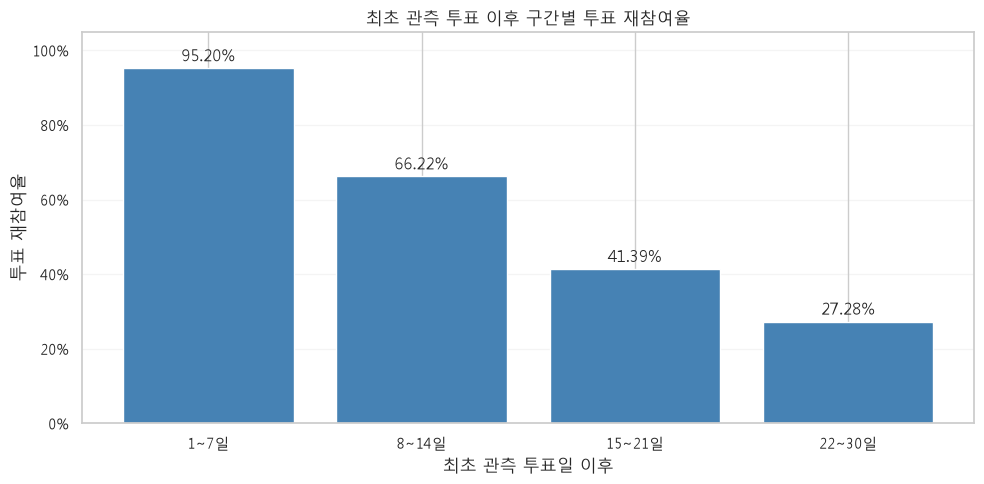

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 1. 직접 투표 기록
df_overall_retention_votes = (
    df_userquestionrecord[
        ["id", "user_id", "created_at"]
    ]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_overall_retention_votes["투표 시각"] = pd.to_datetime(
    df_overall_retention_votes["created_at"],
    errors="raise",
)

df_overall_retention_votes = (
    df_overall_retention_votes
    .dropna(subset=["투표 시각"])
)

# 원본 데이터가 해당 시각까지 빠짐없이 조회됐다는 전제
overall_retention_query_end = pd.Timestamp(params["end_at"])

# 2. 유저별 최초 관측 투표일
df_overall_retention_cohort = (
    df_overall_retention_votes
    .groupby("user_id")["투표 시각"]
    .min()
    .reset_index(name="최초 관측 투표 시각")
)

df_overall_retention_cohort["기준일"] = (
    df_overall_retention_cohort["최초 관측 투표 시각"]
    .dt.normalize()
)

# 기준일 이후 30일째의 마지막 시각까지 관측 가능한 유저
df_overall_retention_cohort["30일 관측 가능"] = (
    df_overall_retention_cohort["기준일"]
    + pd.Timedelta(days=31)
).le(overall_retention_query_end)

overall_retention_total = len(df_overall_retention_cohort)

df_overall_retention_cohort = (
    df_overall_retention_cohort.loc[
        df_overall_retention_cohort["30일 관측 가능"]
    ]
    .copy()
)

if df_overall_retention_cohort.empty:
    raise ValueError("최초 투표 이후 30일을 관측할 수 있는 유저가 없습니다.")

# 3. 개인별 기준일 이후 투표 연결
df_overall_retention_detail = (
    df_overall_retention_cohort[["user_id", "기준일"]]
    .merge(
        df_overall_retention_votes[["user_id", "투표 시각"]],
        on="user_id",
        how="inner",
        validate="one_to_many",
    )
)

df_overall_retention_detail["경과일"] = (
    df_overall_retention_detail["투표 시각"].dt.normalize()
    - df_overall_retention_detail["기준일"]
).dt.days

# 4. 구간별 재참여 여부
# 최초 투표 당일은 모든 구간에서 제외
overall_retention_windows = {
    "1~7일": (1, 7),
    "8~14일": (8, 14),
    "15~21일": (15, 21),
    "22~30일": (22, 30),
    "1~30일 전체": (1, 30),
}

df_overall_retention_result = (
    df_overall_retention_cohort[
        ["user_id", "최초 관측 투표 시각", "기준일"]
    ]
    .copy()
)

for label, (start_day, end_day) in overall_retention_windows.items():
    active_user_ids = (
        df_overall_retention_detail.loc[
            df_overall_retention_detail["경과일"]
            .between(start_day, end_day),
            "user_id",
        ]
        .unique()
    )

    df_overall_retention_result[label] = (
        df_overall_retention_result["user_id"].isin(active_user_ids)
    )

# 5. 전체 요약표
overall_retention_users = len(df_overall_retention_result)

df_overall_retention_summary = pd.DataFrame([
    {
        "구간": label,
        "분석 유저 수": overall_retention_users,
        "재참여 유저 수": int(
            df_overall_retention_result[label].sum()
        ),
        "재참여율(%)": (
            df_overall_retention_result[label].mean() * 100
        ),
    }
    for label in overall_retention_windows
])

print(f"전체 고유 투표자: {overall_retention_total:,}명")
print(f"30일 관측 가능한 분석 대상: {overall_retention_users:,}명")
print(
    "관측 기간 부족으로 제외:",
    f"{overall_retention_total - overall_retention_users:,}명",
)

display(df_overall_retention_summary.round(2))

# 6. 구간별 그래프 — 누적 1~30일 값은 제외
df_overall_retention_plot = (
    df_overall_retention_summary.loc[
        df_overall_retention_summary["구간"].ne("1~30일 전체")
    ]
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    df_overall_retention_plot["구간"],
    df_overall_retention_plot["재참여율(%)"],
    color="steelblue",
)

for bar in bars:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("최초 관측 투표 이후 구간별 투표 재참여율")
ax.set_xlabel("최초 관측 투표일 이후")
ax.set_ylabel("투표 재참여율")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 최초 관측 출석 이후 주차별 출석 유지율


C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3693705882.py:78: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + pd.Timedelta(days=28)


출석 기록이 있는 전체 일반 유저: 328,692명
이후 28일 관측 가능한 유저: 328,592명
관측 기간 부족으로 제외: 100명


,구간,분석 유저 수,출석 유저 수,출석 유지율(%)
0,1~7일,328592,231228,70.37
1,8~14일,328592,131683,40.07
2,15~21일,328592,73531,22.38
3,22~28일,328592,53527,16.29
4,1~28일 전체,328592,241061,73.36


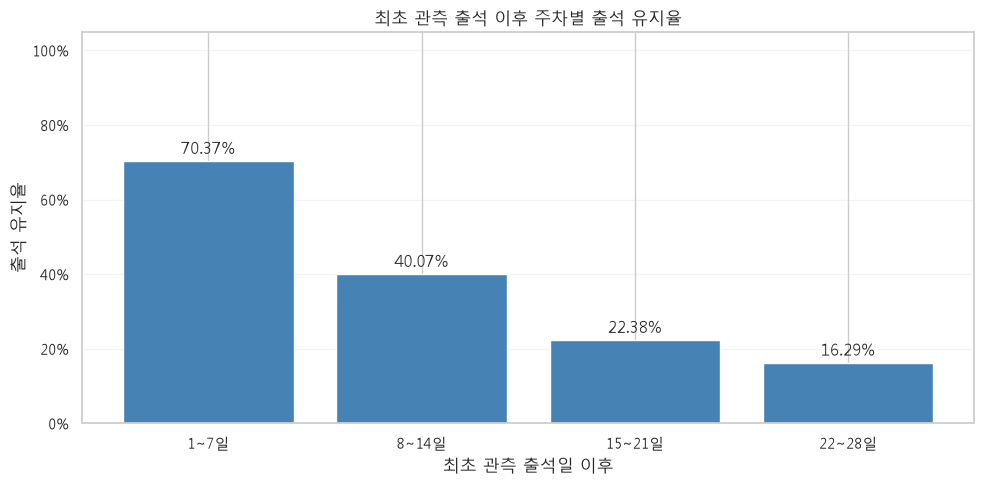

In [77]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

attendance_retention_start = pd.Timestamp("2023-05-27")
attendance_retention_end = pd.Timestamp("2024-05-09")


def parse_attendance_retention_dates(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 1. 전체 일반 유저의 출석 날짜 정리
df_attendance_retention_dates = (
    df_attendance.loc[
        df_attendance["user_id"].isin(df_user["id"]),
        ["user_id", "attendance_date_list"],
    ]
    .copy()
)

df_attendance_retention_dates["출석일"] = (
    df_attendance_retention_dates["attendance_date_list"]
    .apply(parse_attendance_retention_dates)
)

df_attendance_retention_dates = (
    df_attendance_retention_dates
    .explode("출석일")
    .dropna(subset=["user_id", "출석일"])
    [["user_id", "출석일"]]
    .copy()
)

df_attendance_retention_dates["출석일"] = pd.to_datetime(
    df_attendance_retention_dates["출석일"],
    errors="raise",
).dt.normalize()

df_attendance_retention_dates = (
    df_attendance_retention_dates.loc[
        df_attendance_retention_dates["출석일"].between(
            attendance_retention_start,
            attendance_retention_end,
        )
    ]
    .drop_duplicates(["user_id", "출석일"])
)

if df_attendance_retention_dates.empty:
    raise ValueError("분석 기간에 출석 기록이 없습니다.")

# 2. 유저별 최초 관측 출석일
df_attendance_retention_cohort = (
    df_attendance_retention_dates
    .groupby("user_id")["출석일"]
    .min()
    .reset_index(name="최초 관측 출석일")
)

attendance_retention_total = len(df_attendance_retention_cohort)

# 이후 28일을 모두 관측할 수 있는 유저만 포함
df_attendance_retention_cohort = (
    df_attendance_retention_cohort.loc[
        (
            df_attendance_retention_cohort["최초 관측 출석일"]
            + pd.Timedelta(days=28)
        ).le(attendance_retention_end)
    ]
    .copy()
)

if df_attendance_retention_cohort.empty:
    raise ValueError("첫 출석 이후 28일을 관측할 수 있는 유저가 없습니다.")

# 3. 최초 출석일 이후 출석 연결
df_attendance_retention_detail = (
    df_attendance_retention_cohort
    .merge(
        df_attendance_retention_dates,
        on="user_id",
        how="inner",
        validate="one_to_many",
    )
)

df_attendance_retention_detail["경과일"] = (
    df_attendance_retention_detail["출석일"]
    - df_attendance_retention_detail["최초 관측 출석일"]
).dt.days

# 4. 구간별 출석 여부
attendance_retention_windows = {
    "1~7일": (1, 7),
    "8~14일": (8, 14),
    "15~21일": (15, 21),
    "22~28일": (22, 28),
    "1~28일 전체": (1, 28),
}

df_attendance_retention_result = (
    df_attendance_retention_cohort.copy()
)

for label, (start_day, end_day) in attendance_retention_windows.items():
    active_ids = (
        df_attendance_retention_detail.loc[
            df_attendance_retention_detail["경과일"].between(
                start_day, end_day
            ),
            "user_id",
        ]
        .unique()
    )

    df_attendance_retention_result[label] = (
        df_attendance_retention_result["user_id"].isin(active_ids)
    )

# 5. 요약표
attendance_retention_users = len(df_attendance_retention_result)

df_attendance_retention_summary = pd.DataFrame([
    {
        "구간": label,
        "분석 유저 수": attendance_retention_users,
        "출석 유저 수": int(
            df_attendance_retention_result[label].sum()
        ),
        "출석 유지율(%)": (
            df_attendance_retention_result[label].mean() * 100
        ),
    }
    for label in attendance_retention_windows
])

print(f"출석 기록이 있는 전체 일반 유저: {attendance_retention_total:,}명")
print(f"이후 28일 관측 가능한 유저: {attendance_retention_users:,}명")
print(
    "관측 기간 부족으로 제외:",
    f"{attendance_retention_total - attendance_retention_users:,}명",
)

display(df_attendance_retention_summary.round(2))

# 6. 그래프
df_attendance_retention_plot = (
    df_attendance_retention_summary.loc[
        df_attendance_retention_summary["구간"].ne("1~28일 전체")
    ]
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    df_attendance_retention_plot["구간"],
    df_attendance_retention_plot["출석 유지율(%)"],
    color="steelblue",
)

for bar in bars:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("최초 관측 출석 이후 주차별 출석 유지율")
ax.set_xlabel("최초 관측 출석일 이후")
ax.set_ylabel("출석 유지율")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 한사람 당 평균 출석률


In [78]:
import json
import pandas as pd

full_attendance_start = pd.Timestamp("2023-05-27")


def parse_full_attendance_dates(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 1. 전체 출석 날짜 펼치기
df_full_attendance_dates = df_attendance[
    ["user_id", "attendance_date_list"]
].copy()

df_full_attendance_dates["출석일"] = (
    df_full_attendance_dates["attendance_date_list"]
    .apply(parse_full_attendance_dates)
)

df_full_attendance_dates = (
    df_full_attendance_dates
    .explode("출석일")
    .dropna(subset=["user_id", "출석일"])
    [["user_id", "출석일"]]
    .copy()
)

df_full_attendance_dates["출석일"] = pd.to_datetime(
    df_full_attendance_dates["출석일"],
    errors="raise",
).dt.normalize()

df_full_attendance_dates = (
    df_full_attendance_dates.loc[
        df_full_attendance_dates["출석일"].ge(full_attendance_start)
    ]
    .drop_duplicates(["user_id", "출석일"])
)

if df_full_attendance_dates.empty:
    raise ValueError("5월 27일 이후 출석 기록이 없습니다.")

full_attendance_end = df_full_attendance_dates["출석일"].max()

# 2. 출석 테이블에 연결되는 일반 유저
df_full_attendance_users = (
    df_user.loc[
        df_user["id"].isin(df_attendance["user_id"]),
        ["id", "created_at"],
    ]
    .rename(columns={
        "id": "user_id",
        "created_at": "가입 시각",
    })
    .drop_duplicates("user_id")
    .copy()
)

df_full_attendance_users["가입일"] = pd.to_datetime(
    df_full_attendance_users["가입 시각"],
    errors="raise",
).dt.normalize()

df_full_attendance_users = (
    df_full_attendance_users.loc[
        df_full_attendance_users["가입일"].notna()
        & df_full_attendance_users["가입일"].le(full_attendance_end)
    ]
    .copy()
)

# 개인별 관측 시작일 = 5월 27일과 가입일 중 늦은 날짜
df_full_attendance_users["개인 관측 시작일"] = (
    df_full_attendance_users["가입일"]
    .clip(lower=full_attendance_start)
)

df_full_attendance_users["관측 가능 일수"] = (
    full_attendance_end
    - df_full_attendance_users["개인 관측 시작일"]
).dt.days + 1

# 3. 개인 관측 시작일 이후의 출석만 집계
df_full_attendance_detail = (
    df_full_attendance_dates
    .merge(
        df_full_attendance_users[[
            "user_id", "개인 관측 시작일"
        ]],
        on="user_id",
        how="inner",
        validate="many_to_one",
    )
)

df_full_attendance_detail = df_full_attendance_detail.loc[
    df_full_attendance_detail["출석일"].ge(
        df_full_attendance_detail["개인 관측 시작일"]
    )
]

full_attendance_counts = (
    df_full_attendance_detail
    .groupby("user_id")["출석일"]
    .nunique()
    .rename("출석일 수")
    .reset_index()
)

# 출석 테이블은 있지만 해당 기간 기록이 없는 유저도 포함
df_full_attendance_result = (
    df_full_attendance_users
    .merge(
        full_attendance_counts,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

df_full_attendance_result["출석일 수"] = (
    df_full_attendance_result["출석일 수"]
    .fillna(0)
    .astype(int)
)

df_full_attendance_result["개인 출석률(%)"] = (
    df_full_attendance_result["출석일 수"]
    / df_full_attendance_result["관측 가능 일수"]
    * 100
)

# 4. 전체 요약
df_full_attendance_summary = pd.DataFrame([{
    "분석 유저 수": len(df_full_attendance_result),
    "1인당 평균 출석일 수": (
        df_full_attendance_result["출석일 수"].mean()
    ),
    "1인당 평균 출석률(%)": (
        df_full_attendance_result["개인 출석률(%)"].mean()
    ),
    "개인 출석률 중앙값(%)": (
        df_full_attendance_result["개인 출석률(%)"].median()
    ),
}])

print(
    f"출석 분석 기간: {full_attendance_start:%Y-%m-%d}"
    f" ~ {full_attendance_end:%Y-%m-%d}"
)

display(df_full_attendance_summary.round(2))

# 개인별 결과
display(
    df_full_attendance_result[[
        "user_id",
        "가입일",
        "개인 관측 시작일",
        "관측 가능 일수",
        "출석일 수",
        "개인 출석률(%)",
    ]]
    .sort_values(
        ["개인 출석률(%)", "user_id"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
    .round(2)
)

출석 분석 기간: 2023-05-27 ~ 2024-05-09


,분석 유저 수,1인당 평균 출석일 수,1인당 평균 출석률(%),개인 출석률 중앙값(%)
0,349637,6.36,1.83,0.86


,user_id,가입일,개인 관측 시작일,관측 가능 일수,출석일 수,개인 출석률(%)
0,1583730,2024-05-09,2024-05-09,1,1,100.00
1,1499325,2023-05-24,2023-05-27,349,310,88.83
2,1314665,2023-05-16,2023-05-27,349,302,86.53
3,1467385,2023-05-23,2023-05-27,349,277,79.37
4,1491003,2023-05-24,2023-05-27,349,274,78.51
...,...,...,...,...,...,...
349632,1583647,2024-04-25,2024-04-25,15,0,0.00
349633,1583653,2024-04-25,2024-04-25,15,0,0.00
349634,1583660,2024-04-27,2024-04-27,13,0,0.00
349635,1583697,2024-05-03,2024-05-03,7,0,0.00


## 월별 투표 참여율


In [79]:
import pandas as pd

# 1. 전체 보유 투표 기록
df_monthly_voter_source = (
    df_userquestionrecord[["id", "user_id", "created_at"]]
    .dropna(subset=["user_id"])
    .drop_duplicates("id")
    .copy()
)

df_monthly_voter_source["투표 시각"] = pd.to_datetime(
    df_monthly_voter_source["created_at"],
    errors="raise",
)

df_monthly_voter_source["월"] = (
    df_monthly_voter_source["투표 시각"].dt.to_period("M")
)

# 2. 조회 기간의 모든 월 생성
monthly_voter_query_start = pd.Timestamp(params["start_at"])
monthly_voter_query_end = pd.Timestamp(params["end_at"])

monthly_voter_months = pd.period_range(
    monthly_voter_query_start.to_period("M"),
    (
        monthly_voter_query_end - pd.Timedelta(nanoseconds=1)
    ).to_period("M"),
    freq="M",
)

# 3. 월별 고유 투표 참여 인원
df_monthly_voter_summary = (
    df_monthly_voter_source
    .groupby("월")["user_id"]
    .nunique()
    .reindex(monthly_voter_months, fill_value=0)
    .rename_axis("월")
    .reset_index(name="투표 참여 인원")
)

df_monthly_voter_summary["전월 대비 증감 인원"] = (
    df_monthly_voter_summary["투표 참여 인원"]
    .diff()
    .astype("Int64")
)

# 부분 조회 월 표시
df_monthly_voter_summary["조회 범위"] = [
    (
        "전체 월"
        if (
            monthly_voter_query_start <= month.start_time
            and monthly_voter_query_end
            >= (month + 1).start_time
        )
        else "부분 월"
    )
    for month in df_monthly_voter_summary["월"]
]

df_monthly_voter_summary["월"] = (
    df_monthly_voter_summary["월"].astype(str)
)

display(df_monthly_voter_summary)

C:\Users\USER\AppData\Local\Temp\ipykernel_33836\3684016057.py:27: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  monthly_voter_query_end - pd.Timedelta(nanoseconds=1)


,월,투표 참여 인원,전월 대비 증감 인원,조회 범위
0,2023-05,4771,<NA>,부분 월
1,2023-06,1872,-2899,전체 월
2,2023-07,389,-1483,전체 월
3,2023-08,170,-219,전체 월
4,2023-09,178,8,전체 월
5,2023-10,46,-132,전체 월
6,2023-11,22,-24,전체 월
7,2023-12,26,4,전체 월
8,2024-01,19,-7,전체 월
9,2024-02,9,-10,전체 월


## 월별 출석


In [80]:
import json
import pandas as pd

monthly_attendance_start = pd.Timestamp("2023-05-27")
monthly_attendance_end = pd.Timestamp("2024-05-06")  # 미포함


def parse_monthly_attendance(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return value

    if value is None or pd.isna(value):
        return []

    raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# 1. 일반 유저의 출석 목록 펼치기
df_monthly_attendance_source = (
    df_attendance.loc[
        df_attendance["user_id"].isin(df_user["id"]),
        ["user_id", "attendance_date_list"],
    ]
    .copy()
)

df_monthly_attendance_source["출석일"] = (
    df_monthly_attendance_source["attendance_date_list"]
    .apply(parse_monthly_attendance)
)

df_monthly_attendance_source = (
    df_monthly_attendance_source
    .explode("출석일")
    .dropna(subset=["user_id", "출석일"])
    [["user_id", "출석일"]]
    .copy()
)

df_monthly_attendance_source["출석일"] = pd.to_datetime(
    df_monthly_attendance_source["출석일"],
    errors="raise",
).dt.normalize()

# 2. 분석 기간 적용
df_monthly_attendance_source = (
    df_monthly_attendance_source.loc[
        df_monthly_attendance_source["출석일"].ge(
            monthly_attendance_start
        )
        & df_monthly_attendance_source["출석일"].lt(
            monthly_attendance_end
        )
    ]
    .drop_duplicates(["user_id", "출석일"])
    .copy()
)

df_monthly_attendance_source["월"] = (
    df_monthly_attendance_source["출석일"].dt.to_period("M")
)

# 3. 월별 고유 출석 인원
monthly_attendance_months = pd.period_range(
    monthly_attendance_start.to_period("M"),
    (
        monthly_attendance_end - pd.Timedelta(nanoseconds=1)
    ).to_period("M"),
    freq="M",
)

df_monthly_attendance_summary = (
    df_monthly_attendance_source
    .groupby("월")["user_id"]
    .nunique()
    .reindex(monthly_attendance_months, fill_value=0)
    .rename_axis("월")
    .reset_index(name="출석 인원")
)

df_monthly_attendance_summary["전월 대비 증감 인원"] = (
    df_monthly_attendance_summary["출석 인원"]
    .diff()
    .astype("Int64")
)

# 실제 관측한 날짜 범위 표시
df_monthly_attendance_summary["관측 시작일"] = [
    max(month.start_time, monthly_attendance_start).date()
    for month in df_monthly_attendance_summary["월"]
]

df_monthly_attendance_summary["관측 종료일"] = [
    (
        min(
            (month + 1).start_time,
            monthly_attendance_end,
        )
        - pd.Timedelta(days=1)
    ).date()
    for month in df_monthly_attendance_summary["월"]
]

df_monthly_attendance_summary["월"] = (
    df_monthly_attendance_summary["월"].astype(str)
)

display(df_monthly_attendance_summary)

C:\Users\USER\AppData\Local\Temp\ipykernel_33836\193206057.py:70: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  monthly_attendance_end - pd.Timedelta(nanoseconds=1)
C:\Users\USER\AppData\Local\Temp\ipykernel_33836\193206057.py:102: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  - pd.Timedelta(days=1)


,월,출석 인원,전월 대비 증감 인원,관측 시작일,관측 종료일
0,2023-05,264049,<NA>,2023-05-27,2023-05-31
1,2023-06,226928,-37121,2023-06-01,2023-06-30
2,2023-07,61836,-165092,2023-07-01,2023-07-31
3,2023-08,28314,-33522,2023-08-01,2023-08-31
4,2023-09,20482,-7832,2023-09-01,2023-09-30
5,2023-10,9011,-11471,2023-10-01,2023-10-31
6,2023-11,6050,-2961,2023-11-01,2023-11-30
7,2023-12,3612,-2438,2023-12-01,2023-12-31
8,2024-01,3072,-540,2024-01-01,2024-01-31
9,2024-02,1191,-1881,2024-02-01,2024-02-29


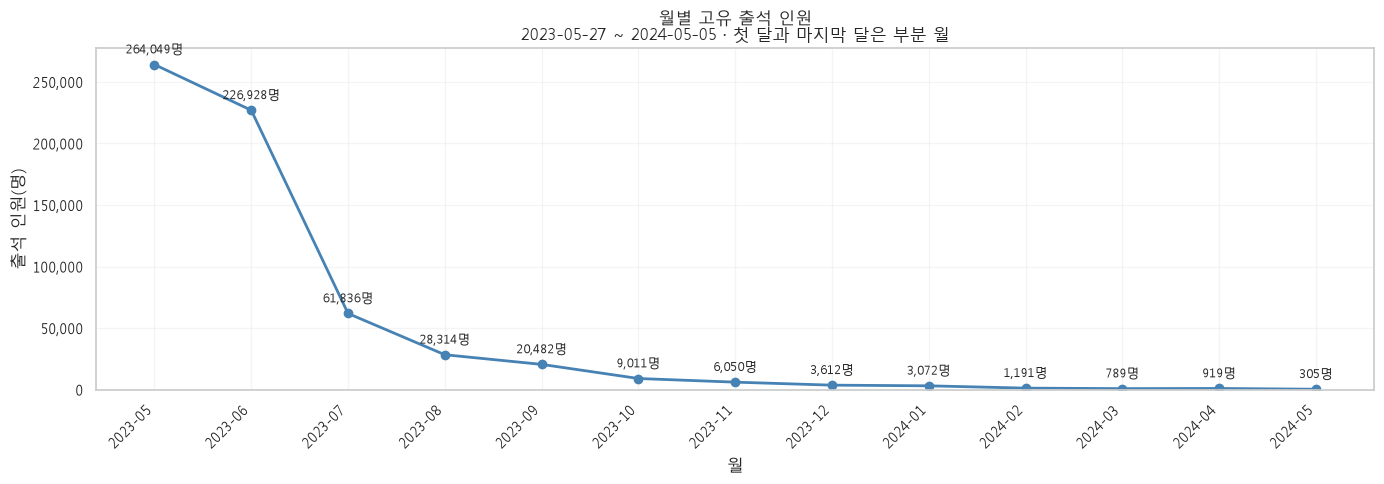

In [81]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

df_monthly_attendance_plot = df_monthly_attendance_summary.copy()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_monthly_attendance_plot["월"],
    df_monthly_attendance_plot["출석 인원"],
    color="steelblue",
    marker="o",
    linewidth=2,
)

for month, count in zip(
    df_monthly_attendance_plot["월"],
    df_monthly_attendance_plot["출석 인원"],
):
    ax.annotate(
        f"{count:,}명",
        xy=(month, count),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_title(
    "월별 고유 출석 인원\n"
    "2023-05-27 ~ 2024-05-05 · 첫 달과 마지막 달은 부분 월"
)
ax.set_xlabel("월")
ax.set_ylabel("출석 인원(명)")
ax.set_ylim(bottom=0)
ax.margins(y=0.15)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)
ax.grid(alpha=0.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 데이터 마트 만들기 2023-05, 2023-06


In [82]:
# from pathlib import Path
# import json
# import pandas as pd

# mart_mapper = QuestionIdMapper()

# # 기존 조회 범위에 맞춰 5월 4일부터 추출
# mart_start = pd.Timestamp("2023-05-04")
# mart_end = pd.Timestamp("2023-07-01")  # 미포함

# if (
#     pd.Timestamp(params["start_at"]) > mart_start
#     or pd.Timestamp(params["end_at"]) < mart_end
# ):
#     raise ValueError("원본 조회 기간이 5월 4일~6월 30일을 포함해야 합니다.")

# mart_target_reasons = [
#     "그냥 싫어",
#     "나랑 맞지 않는 질문인 것 같음",
#     "불쾌한 질문 내용",
#     "이 질문은 재미없어요",
#     "기타",
#     "불쾌한 내용이 포함되어 있음",
#     "선정적이거나 자극적인 질문",
# ]


# def parse_mart_attendance(value):
#     if isinstance(value, str):
#         value = json.loads(value)

#     if isinstance(value, list):
#         return value

#     if value is None or pd.isna(value):
#         return []

#     raise ValueError("출석 날짜 목록 형식을 확인해 주세요.")


# # 1. 공통 연결 정보
# df_mart_users = (
#     df_user[["id", "gender"]]
#     .rename(columns={"id": "user_id"})
#     .copy()
# )

# df_mart_questions = (
#     df_question[["id", "question_text"]]
#     .rename(columns={"id": "question_id"})
#     .copy()
# )

# df_mart_labels = (
#     df_labels
#     .rename(columns=lambda column: column.strip())
#     [["대표 질문 ID", "라벨링"]]
#     .rename(columns={
#         "대표 질문 ID": "representative_question_id",
#         "라벨링": "category",
#     })
#     .copy()
# )

# df_mart_labels["representative_question_id"] = pd.to_numeric(
#     df_mart_labels["representative_question_id"],
#     errors="raise",
# ).astype("Int64")

# if (
#     df_mart_labels["representative_question_id"].isna().any()
#     or df_mart_labels["representative_question_id"].duplicated().any()
# ):
#     raise ValueError("ラベル CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

# df_mart_labels["category"] = (
#     df_mart_labels["category"]
#     .astype("string")
#     .str.strip()
#     .replace({"": "미분류", "해당 없음": "미분류"})
#     .fillna("미분류")
# )

# # 2. 질문 신고 — 원본 사유 전체
# df_mart_reports = (
#     df_questionreport[
#         ["id", "user_id", "question_id", "created_at", "reason"]
#     ]
#     .drop_duplicates("id")
#     .rename(columns={"created_at": "event_at"})
#     .copy()
# )

# df_mart_reports["event_id"] = (
#     "report_" + df_mart_reports["id"].astype("string")
# )
# df_mart_reports["event_type"] = "report"
# df_mart_reports["source"] = "polls_questionreport"
# df_mart_reports["time_precision"] = "datetime"

# df_mart_reports["reason"] = (
#     df_mart_reports["reason"].astype("string").str.strip()
# )

# df_mart_reports["is_selected_reason"] = (
#     df_mart_reports["reason"].isin(mart_target_reasons)
# )

# df_mart_reports = df_mart_reports.drop(columns="id")

# # 3. 투票 — 현재 조회한 원본 기록
# df_mart_votes = (
#     df_userquestionrecord[
#         ["id", "user_id", "chosen_user_id", "question_id", "created_at"]
#     ]
#     .drop_duplicates("id")
#     .rename(columns={"created_at": "event_at"})
#     .copy()
# )

# df_mart_votes["event_id"] = (
#     "vote_" + df_mart_votes["id"].astype("string")
# )
# df_mart_votes["event_type"] = "vote"
# df_mart_votes["source"] = "accounts_userquestionrecord"
# df_mart_votes["time_precision"] = "datetime"

# df_mart_votes = df_mart_votes.drop(columns="id")

# # 4. 출석 — 유저별 고유 출석 날짜
# df_mart_attendance = (
#     df_attendance[["user_id", "attendance_date_list"]]
#     .copy()
# )

# df_mart_attendance["event_at"] = (
#     df_mart_attendance["attendance_date_list"]
#     .apply(parse_mart_attendance)
# )

# df_mart_attendance = (
#     df_mart_attendance
#     .explode("event_at")
#     .dropna(subset=["user_id", "event_at"])
#     [["user_id", "event_at"]]
#     .copy()
# )

# df_mart_attendance["event_at"] = pd.to_datetime(
#     df_mart_attendance["event_at"],
#     errors="raise",
# ).dt.normalize()

# df_mart_attendance["user_id"] = pd.to_numeric(
#     df_mart_attendance["user_id"],
#     errors="raise",
# ).astype("Int64")

# df_mart_attendance = (
#     df_mart_attendance
#     .drop_duplicates(["user_id", "event_at"])
# )

# df_mart_attendance["event_id"] = (
#     "attendance_"
#     + df_mart_attendance["user_id"].astype("string")
#     + "_"
#     + df_mart_attendance["event_at"].dt.strftime("%Y%m%d")
# )
# df_mart_attendance["event_type"] = "attendance"
# df_mart_attendance["source"] = "accounts_attendance"
# df_mart_attendance["time_precision"] = "date"

# # 5. 활동 테이블 통합
# mart_event_columns = [
#     "event_id",
#     "event_type",
#     "event_at",
#     "time_precision",
#     "user_id",
#     "chosen_user_id",
#     "question_id",
#     "reason",
#     "is_selected_reason",
#     "source",
# ]

# mart_event_frames = []

# for event_frame in [
#     df_mart_reports,
#     df_mart_votes,
#     df_mart_attendance,
# ]:
#     event_frame = event_frame.copy()

#     for column in mart_event_columns:
#         if column not in event_frame.columns:
#             event_frame[column] = pd.NA

#     for column in ["user_id", "chosen_user_id", "question_id"]:
#         event_frame[column] = pd.to_numeric(
#             event_frame[column],
#             errors="raise",
#         ).astype("Int64")

#     event_frame["event_at"] = pd.to_datetime(
#         event_frame["event_at"],
#         errors="raise",
#     )

#     event_frame = event_frame.loc[
#         event_frame["event_at"].ge(mart_start)
#         & event_frame["event_at"].lt(mart_end),
#         mart_event_columns,
#     ]

#     mart_event_frames.append(event_frame)

# df_monthly_activity_mart = pd.concat(
#     mart_event_frames,
#     ignore_index=True,
# )

# # 6. 대표 질문 ID 연결
# # 출석에는 질문이 없으므로 변환하지 않음
# df_monthly_activity_mart["representative_question_id"] = pd.Series(
#     pd.NA,
#     index=df_monthly_activity_mart.index,
#     dtype="Int64",
# )

# mart_question_mask = (
#     df_monthly_activity_mart["question_id"].notna()
# )

# df_monthly_activity_mart.loc[
#     mart_question_mask, "representative_question_id"
# ] = mart_mapper.transform(
#     df_monthly_activity_mart.loc[
#         mart_question_mask, "question_id"
#     ]
# )

# # 제외 여부는 표시만 하고 행은 유지
# df_monthly_activity_mart["is_mapper_excluded"] = (
#     mart_question_mask
#     & df_monthly_activity_mart["question_id"].isin(
#         mart_mapper.remove_ids
#     )
# )

# df_monthly_activity_mart["is_excluded_reporter"] = (
#     df_monthly_activity_mart["user_id"].isin(excluded_reporter_ids)
# )

# # 유저 성별 연결 — 연결되지 않아도 행 유지
# df_monthly_activity_mart = (
#     df_monthly_activity_mart
#     .merge(
#         df_mart_users,
#         on="user_id",
#         how="left",
#         validate="many_to_one",
#         indicator="user_join_status",
#     )
#     .merge(
#         df_mart_questions,
#         on="question_id",
#         how="left",
#         validate="many_to_one",
#     )
#     .merge(
#         df_mart_labels,
#         on="representative_question_id",
#         how="left",
#         validate="many_to_one",
#     )
# )

# df_monthly_activity_mart["user_info_matched"] = (
#     df_monthly_activity_mart["user_join_status"].eq("both")
# )

# df_monthly_activity_mart = (
#     df_monthly_activity_mart
#     .drop(columns="user_join_status")
# )

# if df_monthly_activity_mart["event_id"].duplicated().any():
#     raise ValueError("활동 ID가 중복됩니다.")

# # 7. 저장 컬럼 정리
# mart_output_columns = [
#     "event_id",
#     "event_type",
#     "event_at",
#     "time_precision",
#     "user_id",
#     "gender",
#     "user_info_matched",
#     "chosen_user_id",
#     "question_id",
#     "representative_question_id",
#     "question_text",
#     "category",
#     "reason",
#     "is_selected_reason",
#     "is_excluded_reporter",
#     "is_mapper_excluded",
#     "source",
# ]

# # 8. 5·6월을 합쳐 CSV 한 개로 저장
# df_may_june_activity_mart = (
#     df_monthly_activity_mart[mart_output_columns]
#     .sort_values(["event_at", "event_type", "event_id"])
#     .reset_index(drop=True)
# )

# # 파일 안에서 월별 구분 가능
# df_may_june_activity_mart.insert(
#     2,
#     "event_month",
#     df_may_june_activity_mart["event_at"].dt.strftime("%Y-%m"),
# )

# save_path = Path.cwd() / "2023_05_06_활동마트.csv"

# df_may_june_activity_mart.to_csv(
#     save_path,
#     index=False,
#     encoding="utf-8-sig",
#     date_format="%Y-%m-%d %H:%M:%S",
# )

# print(f"저장 위치: {save_path.resolve()}")
# print(f"전체 기록: {len(df_may_june_activity_mart):,}건")

# display(
#     df_may_june_activity_mart
#     .groupby(["event_month", "event_type"])
#     .size()
#     .reset_index(name="기록 수")
# )

### 마트 데이터 검증


In [83]:
from pathlib import Path
from collections import Counter
import pandas as pd
from sqlalchemy import text

# 실제 파일 위치에 맞게 변경 가능
verify_path = Path(
    r"C:\Users\USER\Desktop\final_prj\codeit-sns-moderation"
) / "2023_05_06_활동마트_0501부터.csv"

verify_start = pd.Timestamp("2023-05-01")
verify_end = pd.Timestamp("2023-07-01")  # 미포함

verify_mapper = QuestionIdMapper()

verify_reasons = {
    "그냥 싫어",
    "나랑 맞지 않는 질문인 것 같음",
    "불쾌한 질문 내용",
    "이 질문은 재미없어요",
    "기타",
    "불쾌한 내용이 포함되어 있음",
    "선정적이거나 자극적인 질문",
}

if not verify_path.exists():
    raise FileNotFoundError(verify_path)

# 1. 최종 카테고리 연결 기준
verify_labels = (
    df_labels
    .rename(columns=lambda column: column.strip())
    [["대표 질문 ID", "라벨링"]]
    .copy()
)

verify_labels["대표 질문 ID"] = pd.to_numeric(
    verify_labels["대표 질문 ID"],
    errors="raise",
).astype("Int64")

if (
    verify_labels["대표 질문 ID"].isna().any()
    or verify_labels["대표 질문 ID"].duplicated().any()
):
    raise ValueError("라벨 CSV의 대표 질문 ID 결측·중복을 확인해 주세요.")

verify_labels["라벨링"] = (
    verify_labels["라벨링"]
    .astype("string")
    .str.strip()
    .replace({"": "미분류", "해당 없음": "미분류"})
    .fillna("미분류")
)

verify_category_map = dict(zip(
    verify_labels["대표 질문 ID"],
    verify_labels["라벨링"],
))

# 2. CSV를 나눠 읽으며 검증
verify_counts = Counter()
verify_errors = Counter()
verify_seen_event_ids = set()

verify_total_rows = 0
verify_first_date = None
verify_last_date = None

verify_source_map = {
    "report": "polls_questionreport",
    "vote": "accounts_userquestionrecord",
    "attendance": "accounts_attendance",
}

for chunk in pd.read_csv(
    verify_path,
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False,
    chunksize=100_000,
):
    verify_total_rows += len(chunk)

    dates = pd.to_datetime(chunk["event_at"], errors="coerce")
    valid_dates = dates.dropna()

    verify_errors["日時の欠損・形式異常"] += dates.isna().sum()
    verify_errors["期間外"] += (
        dates.notna()
        & ~dates.between(
            verify_start,
            verify_end,
            inclusive="left",
        )
    ).sum()

    if not valid_dates.empty:
        current_min = valid_dates.min()
        current_max = valid_dates.max()

        verify_first_date = (
            current_min if verify_first_date is None
            else min(verify_first_date, current_min)
        )
        verify_last_date = (
            current_max if verify_last_date is None
            else max(verify_last_date, current_max)
        )

    verify_errors["月と活動日の不一致"] += (
        chunk["event_month"].ne(dates.dt.strftime("%Y-%m"))
        & dates.notna()
    ).sum()

    verify_errors["不明な活動種別"] += (
        ~chunk["event_type"].isin(verify_source_map)
    ).sum()

    verify_errors["原本テーブル不一致"] += (
        chunk["source"].ne(
            chunk["event_type"].map(verify_source_map)
        )
    ).sum()

    # ファイル全体の活動 ID 重複
    event_ids = chunk["event_id"]
    verify_errors["event_id空欄"] += event_ids.eq("").sum()

    within_duplicates = event_ids.duplicated().sum()
    unique_ids = set(event_ids)

    verify_errors["event_id重複"] += (
        within_duplicates
        + len(unique_ids & verify_seen_event_ids)
    )
    verify_seen_event_ids.update(unique_ids)

    # 月・活動別件数
    for key, count in chunk.groupby(
        ["event_month", "event_type"]
    ).size().items():
        verify_counts[key] += int(count)

    # 質問がある活動の代表 ID・除外フラグ
    question_mask = chunk["question_id"].ne("")

    raw_question_ids = pd.to_numeric(
        chunk.loc[question_mask, "question_id"],
        errors="raise",
    ).astype("Int64")

    expected_reps = (
        verify_mapper.transform(raw_question_ids)
        .astype("string")
        .fillna("")
    )

    actual_reps = chunk.loc[
        question_mask, "representative_question_id"
    ]

    verify_errors["代表質問ID不一致"] += (
        actual_reps.ne(expected_reps)
    ).sum()

    expected_mapper_excluded = raw_question_ids.isin(
        verify_mapper.remove_ids
    )

    actual_mapper_excluded = (
        chunk.loc[question_mask, "is_mapper_excluded"]
        .str.lower()
    )

    verify_errors["mapper除外フラグ不一致"] += (
        actual_mapper_excluded.ne(
            expected_mapper_excluded
            .map({True: "true", False: "false"})
        )
    ).sum()

    # カテゴリ接続
    representative_ids = pd.to_numeric(
        actual_reps.replace("", pd.NA),
        errors="raise",
    ).astype("Int64")

    expected_categories = (
        representative_ids.map(verify_category_map)
        .fillna("")
    )

    verify_errors["カテゴリ不一致"] += (
        chunk.loc[question_mask, "category"]
        .ne(expected_categories)
    ).sum()

    # 指定理由フラグ
    report_mask = chunk["event_type"].eq("report")

    expected_selected = (
        chunk.loc[report_mask, "reason"]
        .str.strip()
        .isin(verify_reasons)
        .map({True: "true", False: "false"})
    )

    verify_errors["選定理由フラグ不一致"] += (
        chunk.loc[report_mask, "is_selected_reason"]
        .str.lower()
        .ne(expected_selected)
    ).sum()

    # 出席は日付単位・質問なし
    attendance_mask = chunk["event_type"].eq("attendance")

    verify_errors["出席形式異常"] += (
        attendance_mask
        & (
            chunk["time_precision"].ne("date")
            | chunk["question_id"].ne("")
            | chunk["reason"].ne("")
        )
    ).sum()

# 3. 原本 DB の月別件数
verify_sql = """
SELECT
    DATE_FORMAT(created_at, '%Y-%m') AS event_month,
    'report' AS event_type,
    COUNT(*) AS db_count
FROM polls_questionreport
WHERE created_at >= :start_at
  AND created_at < :end_at
GROUP BY DATE_FORMAT(created_at, '%Y-%m')

UNION ALL

SELECT
    DATE_FORMAT(created_at, '%Y-%m') AS event_month,
    'vote' AS event_type,
    COUNT(*) AS db_count
FROM accounts_userquestionrecord
WHERE answer_status <> 'P'
  AND created_at >= :start_at
  AND created_at < :end_at
GROUP BY DATE_FORMAT(created_at, '%Y-%m')

UNION ALL

SELECT
    DATE_FORMAT(j.attendance_day, '%Y-%m') AS event_month,
    'attendance' AS event_type,
    COUNT(DISTINCT a.user_id, j.attendance_day) AS db_count
FROM accounts_attendance AS a
JOIN JSON_TABLE(
    a.attendance_date_list,
    '$[*]' COLUMNS (
        attendance_day DATE PATH '$'
    )
) AS j ON TRUE
WHERE j.attendance_day >= :start_at
  AND j.attendance_day < :end_at
GROUP BY DATE_FORMAT(j.attendance_day, '%Y-%m')
"""

with engine.connect() as conn:
    df_verify_db_counts = pd.read_sql_query(
        text(verify_sql),
        conn,
        params={
            "start_at": "2023-05-01 00:00:00",
            "end_at": "2023-07-01 00:00:00",
        },
    )

df_verify_csv_counts = pd.DataFrame([
    {
        "event_month": month,
        "event_type": event_type,
        "csv_count": count,
    }
    for (month, event_type), count in verify_counts.items()
])

df_verify_count_comparison = (
    df_verify_db_counts
    .merge(
        df_verify_csv_counts,
        on=["event_month", "event_type"],
        how="outer",
    )
    .fillna({"db_count": 0, "csv_count": 0})
)

df_verify_count_comparison["차이"] = (
    df_verify_count_comparison["csv_count"]
    - df_verify_count_comparison["db_count"]
)

df_verify_count_comparison["결과"] = (
    df_verify_count_comparison["차이"]
    .eq(0)
    .map({True: "일치", False: "불일치"})
)

# 4. 검증 결과 출력
verify_check_names = {
    "日時の欠損・形式異常": "활동 날짜 결측·형식 오류",
    "期間外": "분석 기간 밖 기록",
    "月と活動日の不一致": "월·활동 날짜 불일치",
    "不明な活動種別": "알 수 없는 활동 유형",
    "原本テーブル不一致": "원본 테이블명 불일치",
    "event_id空欄": "활동 ID 빈칸",
    "event_id重複": "활동 ID 중복",
    "代表質問ID不一致": "대표 질문 ID 불일치",
    "mapper除外フラグ不一致": "mapper 제외 표시 불일치",
    "カテゴリ不一致": "카테고리 불일치",
    "選定理由フラグ不一致": "선정 사유 표시 불일치",
    "出席形式異常": "출석 기록 형식 오류",
}

df_verify_checks = pd.DataFrame([
    {
        "검증 항목": verify_check_names[key],
        "문제 건수": int(count),
        "결과": "정상" if count == 0 else "확인 필요",
    }
    for key, count in verify_errors.items()
])

print(f"전체 CSV 기록: {verify_total_rows:,}건")
print(f"최초 활동: {verify_first_date}")
print(f"마지막 활동: {verify_last_date}")

display(df_verify_checks)
display(
    df_verify_count_comparison
    .sort_values(["event_month", "event_type"])
    .reset_index(drop=True)
)

if (
    any(verify_errors.values())
    or df_verify_count_comparison["차이"].ne(0).any()
):
    print("검증 결과: 확인이 필요한 항목이 있습니다.")
else:
    print("검증 결과: 검사 항목 정상, 원본 DB 건수와 일치합니다.")

전체 CSV 기록: 3,060,596건
최초 활동: 2023-05-01 00:05:13
마지막 활동: 2023-06-30 23:15:17


,검증 항목,문제 건수,결과
0,활동 날짜 결측·형식 오류,0,정상
1,분석 기간 밖 기록,0,정상
2,월·활동 날짜 불일치,0,정상
3,알 수 없는 활동 유형,0,정상
4,원본 테이블명 불일치,0,정상
5,활동 ID 빈칸,0,정상
6,활동 ID 중복,0,정상
7,대표 질문 ID 불일치,0,정상
8,mapper 제외 표시 불일치,0,정상
9,카테고리 불일치,0,정상


,event_month,event_type,db_count,csv_count,차이,결과
0,2023-05,attendance,611238,611238,0,일치
1,2023-05,report,44322,44322,0,일치
2,2023-05,vote,1097144,1097144,0,일치
3,2023-06,attendance,1232776,1232776,0,일치
4,2023-06,report,4094,4094,0,일치
5,2023-06,vote,71022,71022,0,일치


검증 결과: 검사 항목 정상, 원본 DB 건수와 일치합니다.
